# How Frontier's cooling affects a GPU: a step-by-step model

## Start here

### The question

A GPU's power draw changes constantly. We have recordings of that power. We want to answer: **given a power recording, how hot does the chip get, and how much heat flows out of it, once you include the cooling system around it?**

The chip doesn't cool itself in isolation. It shares water with thousands of other chips, and that water is managed by a slow thermostat. So we need a model of the whole path the heat takes.

### The short answer

Every number here is worked out further down.

1. **When a big job starts, the cooling water briefly gets warmer.** The thermostat valve reacts late, so the water going back to the GPUs peaks about 4.4 °C above its target and stays more than 1 °C above it for about 4 minutes.
2. **That warms every GPU by about 4 °C for those minutes**, even though the GPU's own work hasn't changed.
3. **The chip smooths its own power.** A change lasting 12 ms moves its temperature by only about 2 % of what a long-lasting change of the same size would.
4. **The cooling water never sees fast spikes.** The chip and metal around it soak up quick bursts and let them out slowly, so the flow of heat into the water is nearly steady.
5. **The rhythm of a workload matters.** Switching on and off faster than about once a minute gets averaged out by the cooling system. Switching every 4 minutes or slower triggers a water-temperature swing each time, adding up to about 9 °C to the swing at the chip.

### The story of one job's heat

Follow the heat outward, with real numbers from this notebook:

1. **In the chip.** One MI250X GPU package at full power draws about 560 W. Nearly all electrical power becomes heat. It's made in two silicon dies with a combined area of 14.5 cm², so 560 W ÷ 14.5 cm² ≈ 39 W/cm². A kitchen hob is around 10 W/cm².
2. **Through the metal.** The heat passes through the die and a stack of metal and contact material into a **cold plate**, a metal block with water channels. To push that heat through, the chip must run hotter than the water: about 0.05 °C per watt, so 560 W × 0.05 ≈ 28 °C.
3. **Into the cabinet's water.** A cabinet holds 128 computers (*nodes*), each with 4 GPU packages. During HPL (a standard benchmark) a cabinet draws about 330 kW. Water at about 28 kW per °C of warming carries that away, warming by 320 kW ÷ 28 kW/°C ≈ 11 °C on the way through.
4. **To the CDU.** Three cabinets send their warm water to one **coolant distribution unit (CDU)**, about 1 MW in total. Inside is a heat exchanger: two streams of water separated by metal plates, which swap heat without mixing.
5. **To the building.** The other side of the heat exchanger is the building's water. A valve sets how much of it flows. The valve is the thermostat, and it tries to send water back to the cabinets at about 28.6 °C.

That group of 3 cabinets plus their CDU is called a **cooling group**, and it's the system modelled here. The diagram a few cells down shows the same path.

### How the notebook is organised

| Section | Question it answers |
|---|---|
| **Six ideas** | What are the few physical ideas everything else uses? Each has a tiny made-up example. |
| **Part 1** | What did the sensors on a real cooling group record, and do the numbers make sense? |
| **Part 2** | How much electricity does a cabinet draw, given what its computers report? |
| **Part 3** | Can a simple model reproduce the cabinet water, CDU and valve? |
| **Part 4** | Can a simple model reproduce the temperature of a real GPU chip, and what happens to the heat flow inside it? |
| **Part 5** | We measured one computer closely. What would 128 of them add up to? |
| **Part 6** | Put it all together: give it a workload, get the chip's response. Includes a cell for trying your own. |
| **Summary** | The conclusions on one page, and how far to trust them. |

### How to read the figures

* **Red numbered circles** on a figure match the numbered list under it. Read the list with the figure next to it.
* **Colours:** grey is power. Blue is the main result, usually the model. Orange is what it's compared against. A wide faded black or grey line is a real measurement, with the thin model line drawn over it. If they overlap, the model is right there.
* **Time** runs left to right, in seconds unless the axis says otherwise.

### Plain glossary

| Word | Meaning |
|---|---|
| **Power** (W, kW, MW) | Energy per second. Everything electrical ends up as this much heat per second. |
| **Heat flux** (W/cm²) | Power spread over an area: how concentrated the heat flow is. |
| **Temperature difference** (°C or K) | A change of 1 K is the same as a change of 1 °C. The notebook's code output often says K. |
| **Thermal resistance** (K/W) | How much hotter one side must be to push 1 W through. Like a narrow pipe. |
| **Thermal mass / heat capacity** (J/K) | How much heat something soaks up per degree of warming. A bathtub warms more slowly than a mug. |
| **Time constant**, τ (tau) | How long something takes to get about 63 % of the way to its new temperature. Thermal mass × resistance. |
| **Steady state** | What things settle to if the inputs stop changing. |
| **Setpoint** | The temperature a thermostat aims for. |
| **Overshoot** | Going past the target before settling back. |
| **Node, blade, cabinet** | A node is one computer (1 CPU, 4 GPU packages). Two nodes sit on a blade. A cabinet holds 128 nodes. |
| **Package** | One MI250X GPU: two silicon dies plus memory on one board. |
| **Junction** | The hottest part of the chip, where the transistors are and the heat is made. |
| **Secondary loop** | The water going through the cabinets. **Primary loop** is the building's water on the other side of the CDU. |
| **LIT / LOT** | Temperature of water going **i**nto / coming **o**ut of a cabinet (*liquid inlet/outlet temperature*). LIT is the water the thermostat controls. |
| **PIT / POT / PLF** | Building-water temperature entering / leaving the CDU, and its flow rate. |
| **AC / DC power** | The cabinet takes in AC electricity from the building and converts it to DC for the computers. |
| **HPL** | High Performance Linpack, the benchmark in these recordings. It runs flat out, with short pauses. |
| **Model** | A set of equations that imitates the real thing. |
| **Fit** | Choosing a model's numbers so it matches a measurement. |
| **RMS error** | The typical size of the gap between model and measurement. |

In [1]:
# Setup: load the libraries, say where figures and results go, and define a helper for the red numbered circles.
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.optimize import least_squares
from scipy.signal import lfilter, lfilter_zi
from scipy.ndimage import uniform_filter1d

from ampere import Ensemble, MetricConfig, MetricType, set_backend
set_backend('pandas')          # no Arkouda server needed for a single-node trace

ROOT = Path('.').resolve()
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
POWER_C, MAIN_C, CMP_C, THIRD_C = '0.45', 'tab:blue', 'tab:orange', 'tab:green'
CAB_C = ['tab:blue', 'tab:orange', 'tab:green']

def mark(ax, n, x, y, dx=16, dy=16):
    '''Draw red circle number n, with a line to the point (x, y), matching the numbered list under the figure.'''
    ax.annotate(str(n), (x, y), xytext=(dx, dy), textcoords='offset points', ha='center', va='center', fontsize=10, fontweight='bold',
                color='white', bbox=dict(boxstyle='circle,pad=0.25', fc='crimson', ec='none'),
                arrowprops=dict(arrowstyle='-', color='crimson', lw=1.3), zorder=20)

    _         _                   _       
   / \   _ __| | _____  _   _  __| | __ _ 
  / _ \ | '__| |/ / _ \| | | |/ _` |/ _` |
 / ___ \| |  |   < (_) | |_| | (_| | (_| |
/_/   \_\_|  |_|\_\___/ \__,_|\__,_|\__,_|
                                          
Client Version: 2026.02.02+40.gec39a6ec8

### The path of the heat, as a picture

Red arrows carry heat outward. The blue arrow is cooled water going back. Under each box: the size of the heat flow, and how quickly that part reacts.

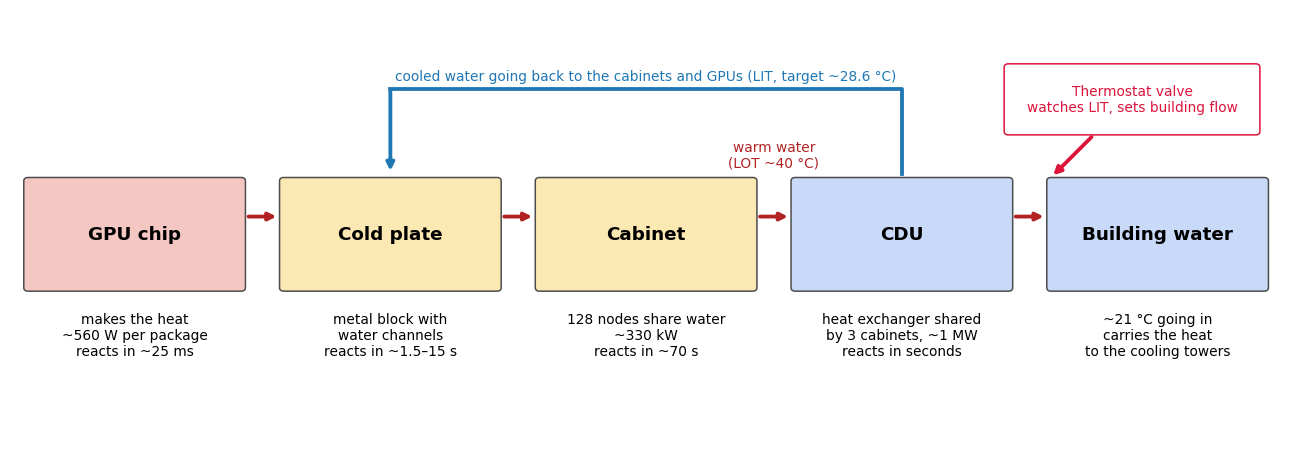

In [2]:
def fig_diagram():
    fig, a = plt.subplots(figsize=(15, 5.2)); a.axis('off'); a.set(xlim=(0, 15), ylim=(0, 6.2))
    boxes = [(0.2, 'GPU chip', 'makes the heat\n~560 W per package\nreacts in ~25 ms', '#f4c7c3'),
             (3.2, 'Cold plate', 'metal block with\nwater channels\nreacts in ~1.5–15 s', '#fce8b2'),
             (6.2, 'Cabinet', '128 nodes share water\n~330 kW\nreacts in ~70 s', '#fce8b2'),
             (9.2, 'CDU', 'heat exchanger shared\nby 3 cabinets, ~1 MW\nreacts in seconds', '#c9daf8'),
             (12.2, 'Building water', '~21 °C going in\ncarries the heat\nto the cooling towers', '#c9daf8')]
    for x, name, note, col in boxes:
        a.add_patch(FancyBboxPatch((x, 2.3), 2.5, 1.5, boxstyle='round,pad=0.05', fc=col, ec='0.3'))
        a.text(x + 1.25, 3.05, name, ha='center', va='center', fontsize=12, fontweight='bold')
        a.text(x + 1.25, 1.95, note, ha='center', va='top', fontsize=9)
    arrow = lambda p, q, c: a.annotate('', q, p, arrowprops=dict(arrowstyle='-|>', color=c, lw=2.5))
    for x in (2.75, 5.75, 8.75, 11.75):
        arrow((x, 3.3), (x + 0.4, 3.3), 'firebrick')
    a.text(8.95, 3.95, 'warm water\n(LOT ~40 °C)', ha='center', va='bottom', fontsize=9, color='firebrick')
    a.plot([10.45, 10.45, 4.45], [3.9, 5.1, 5.1], color='tab:blue', lw=2.5)
    arrow((4.45, 5.1), (4.45, 3.9), 'tab:blue')
    a.text(7.45, 5.17, 'cooled water going back to the cabinets and GPUs (LIT, target ~28.6 °C)', ha='center', va='bottom', fontsize=9, color='tab:blue')
    a.add_patch(FancyBboxPatch((11.7, 4.5), 2.9, 0.9, boxstyle='round,pad=0.05', fc='white', ec='crimson'))
    a.text(13.15, 4.95, 'Thermostat valve\nwatches LIT, sets building flow', ha='center', va='center', fontsize=9, color='crimson')
    arrow((12.7, 4.45), (12.2, 3.85), 'crimson')
    fig.savefig(FIG / 'cg_diagram.png', bbox_inches='tight')

fig_diagram()

## Six ideas that everything else uses

Each idea has a small made-up example, not Frontier data, so you can see it on its own first.

### Idea 1: Water warms by heat ÷ flow

Water carries a fixed amount of heat per degree of warming. So

$$\text{temperature rise of the water} = \frac{\text{heat picked up}}{\text{flow's heat capacity}}$$

**Worked example.** A cabinet makes 320 kW. Its water can carry 28 kW per °C of warming. The water warms by 320 ÷ 28 ≈ 11 °C on its way through. Twice the flow would give half the rise. Flow is often given in **gallons per minute (gpm)**. One gpm of water carries 263 W per °C, so 28 kW/°C is about 106 gpm.

### Idea 2: Heat needs a temperature difference to flow

Heat flows from hot to cold, and the more resistance in its way, the bigger the difference it needs:

$$\text{temperature difference} = \text{power} \times \text{thermal resistance}$$

**Worked example.** A GPU package has about 0.05 K/W between chip and water. At 560 W: 560 × 0.05 = 28 °C. With water at 30 °C, the chip sits around 58 °C. This is the same form as Ohm's law, with temperature as voltage and power as current.

### Idea 3: Thermal mass means things take time to warm

Fill a bathtub with a leak: water level rises until the leak matches the tap, and a bigger tub takes longer to get there. Temperature does the same. Heat comes in, heat leaks out through a resistance, and the thermal mass sets how long the rise takes.

The final temperature doesn't depend on the mass. The **time constant** τ = resistance × mass does: after one τ, the object has gone about 63 % of the way.

The cell below heats three objects with the same 100 W and the same 0.1 K/W, and different thermal masses.

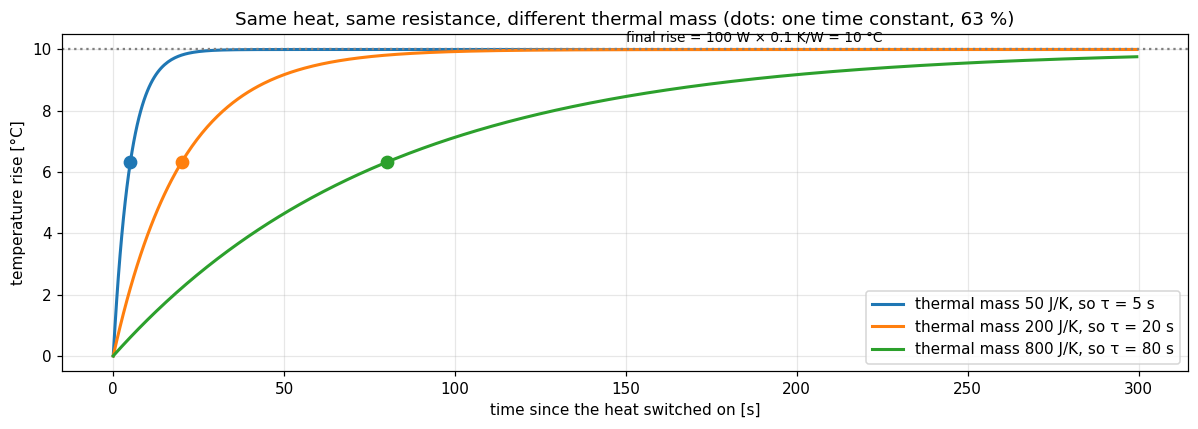

In [3]:
def toy_step():
    t = np.arange(0, 300, 0.5)
    R, P = 0.1, 100.0                                   # K/W, W: final rise = P * R = 10 K
    fig, a = plt.subplots(figsize=(11, 4))
    for C, col in zip([50, 200, 800], [MAIN_C, CMP_C, THIRD_C]):
        tau = R * C
        a.plot(t, P * R * (1 - np.exp(-t / tau)), color=col, lw=2, label=f'thermal mass {C} J/K, so τ = {tau:.0f} s')
        a.plot(tau, P * R * (1 - np.exp(-1)), 'o', color=col, ms=8)
    a.axhline(10, color='0.5', ls=':'); a.annotate('final rise = 100 W × 0.1 K/W = 10 °C', (150, 10), xytext=(0, 5), textcoords='offset points', fontsize=9)
    a.set(xlabel='time since the heat switched on [s]', ylabel='temperature rise [°C]', title='Same heat, same resistance, different thermal mass (dots: one time constant, 63 %)')
    a.legend(); fig.tight_layout(); fig.savefig(FIG / 'cg_idea_thermal_mass.png', bbox_inches='tight')

toy_step()

All three head for the same 10 °C. Only the speed differs. Each dot marks one time constant, where the curve has gone 63 % of the way.

### Idea 4: Thermal mass smooths fast changes

If power flips up and down faster than the object can respond, the object only ever gets a small part of the way before the power flips back. So fast swings get averaged out and slow ones pass through in full. Engineers call this a **low-pass filter**.

The cell below flips a 100 W heater on and off with three different rhythms, using the same object each time (τ = 20 s).

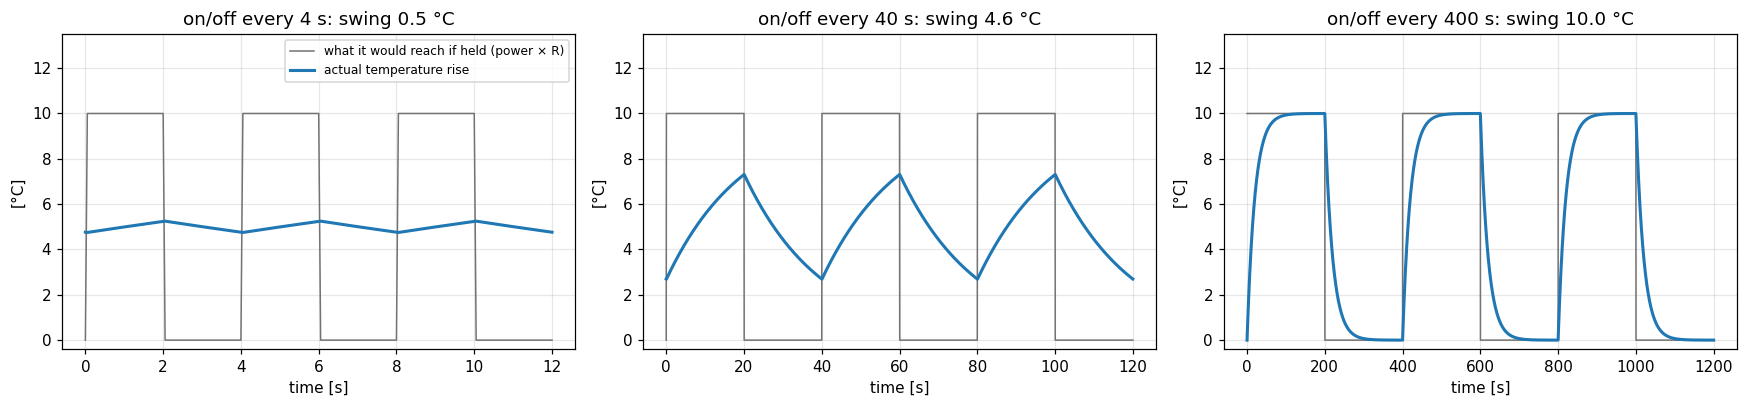

In [4]:
def toy_smoothing():
    dt, R, tau = 0.05, 0.1, 20.0
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    for a, per in zip(ax, [4, 40, 400]):
        t = np.arange(0, 1200, dt)
        P = np.where((t % per) < per / 2, 100.0, 0.0)
        e = np.exp(-dt / tau)
        T = lfilter([0, (1 - e) * R], [1, -e], P)
        last = t >= t[-1] - per
        show = t >= t[-1] - 3 * per
        a.plot(t[show] - t[show][0], P[show] * R, color=POWER_C, lw=1, label='what it would reach if held (power × R)')
        a.plot(t[show] - t[show][0], T[show], color=MAIN_C, lw=2, label='actual temperature rise')
        a.set(xlabel='time [s]', ylabel='[°C]', title=f'on/off every {per} s: swing {np.ptp(T[last]):.1f} °C')
    for a in ax: a.set_ylim(-0.4, 13.5)
    ax[0].legend(fontsize=8, loc='upper right'); fig.tight_layout(); fig.savefig(FIG / 'cg_idea_smoothing.png', bbox_inches='tight')

toy_smoothing()

The same heater gives a 0.5 °C swing when it flips every 4 s, 4.6 °C at 40 s, and the full 10 °C at 400 s. **This single idea explains most of what follows.** The chip, cold plate and cabinet are all filters like this, with different time constants.

### Idea 5: A thermostat that reacts late overshoots

Think of a shower where the water takes a while to reach you. You feel cold, turn the tap, and nothing changes yet, so you turn it more. By the time it arrives it's too hot.

The cell below is a toy tank of water. Heat input triples at t = 100 s. A thermostat adjusts the cooling to hold 10 °C. The two runs are identical, except that one thermostat reads the temperature 5 s late and the other 60 s late.

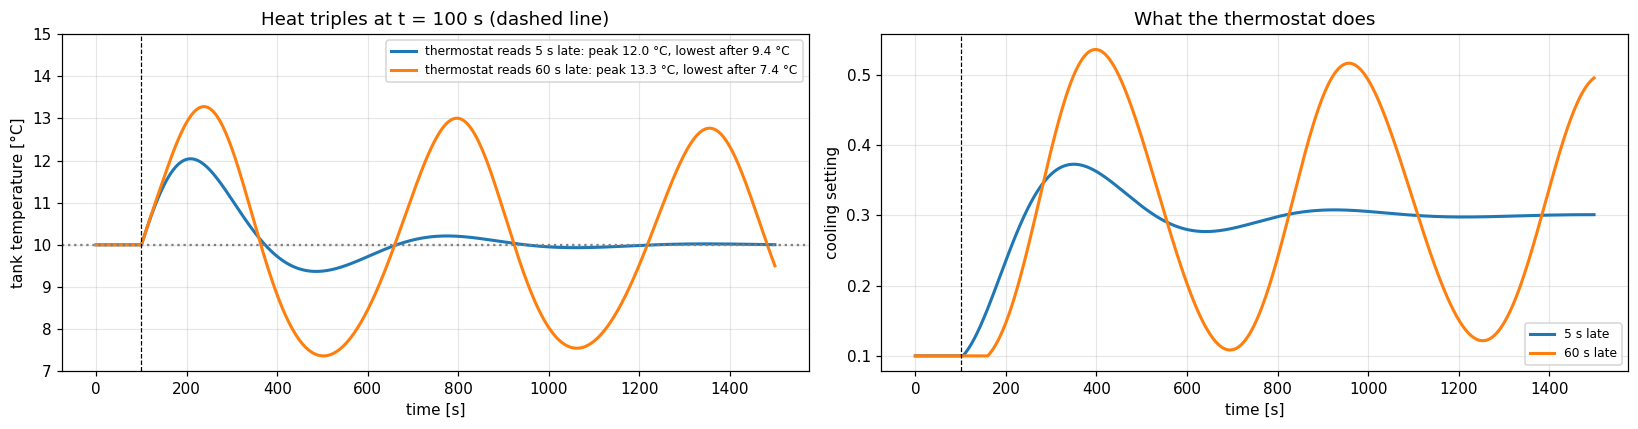

In [5]:
def toy_thermostat(lag_s, Kp=0.02, Ki=0.0008, n=1500):
    '''A tank at temperature T with heat input Q and cooling u * T. A thermostat adjusts u using T as it was lag_s seconds ago.'''
    t = np.arange(n); Q = np.where(t >= 100, 3.0, 1.0)
    C, target = 60.0, 10.0
    T, u, e_prev = target, 0.1, 0.0
    hist = [T] * (lag_s + 1); Ts, us = [], []
    for k in range(n):
        Ts.append(T); us.append(u)
        T += (Q[k] - u * T) / C
        hist.append(T); hist.pop(0)
        e = hist[0] - target                       # the error the thermostat can see
        u = float(np.clip(u + Kp * (e - e_prev) + Ki * e, 0.02, 1.0)); e_prev = e
    return t, np.array(Ts), np.array(us)

def fig_toy_thermostat():
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    for lag, col in [(5, MAIN_C), (60, CMP_C)]:
        t, T, u = toy_thermostat(lag)
        after = t >= 100
        ax[0].plot(t, T, color=col, lw=2, label=f'thermostat reads {lag} s late: peak {T.max():.1f} °C, lowest after {T[T.argmax():].min():.1f} °C')
        ax[1].plot(t, u, color=col, lw=2, label=f'{lag} s late')
    ax[0].axhline(10, color='0.5', ls=':'); ax[0].axvline(100, color='k', lw=0.8, ls='--')
    ax[0].set(xlabel='time [s]', ylabel='tank temperature [°C]', ylim=(7, 15), title='Heat triples at t = 100 s (dashed line)'); ax[0].legend(fontsize=8, loc='upper right')
    ax[1].axvline(100, color='k', lw=0.8, ls='--')
    ax[1].set(xlabel='time [s]', ylabel='cooling setting', title='What the thermostat does'); ax[1].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_idea_thermostat.png', bbox_inches='tight')

fig_toy_thermostat()

Both overshoot, because the extra heat arrives before any thermostat can respond. The late one overshoots more (13.3 °C vs. 12.0 °C), then over-corrects (down to 7.4 °C vs. 9.4 °C), and is still swinging at the end of the plot. The real CDU in Part 3 overshoots in the same way at a job's start, though it settles rather than swinging on. Part 3 tests how much of its overshoot comes from the delay.

### Idea 6: Fitting, RMS error and train/test

We don't know many of the real numbers, such as a cabinet's thermal mass. So we **fit** them: try values, see how far the model's curve is from the measurement, and adjust until the gap is as small as possible. The computer does this search (`least_squares` in the code).

* **RMS error** summarises the gap as one number, the typical distance between the curves. RMS 0.2 °C means the model is typically 0.2 °C off.
* **Train/test.** A model can match the data it was tuned on and still be wrong. The honest check is to fit using only part of the recording (**train**) and then see how it does on the part it never saw (**test**).

In the cell below the "measurement" is made up: a known curve with a known amount of noise added (0.4 °C), so we can see whether the fit recovers the truth.

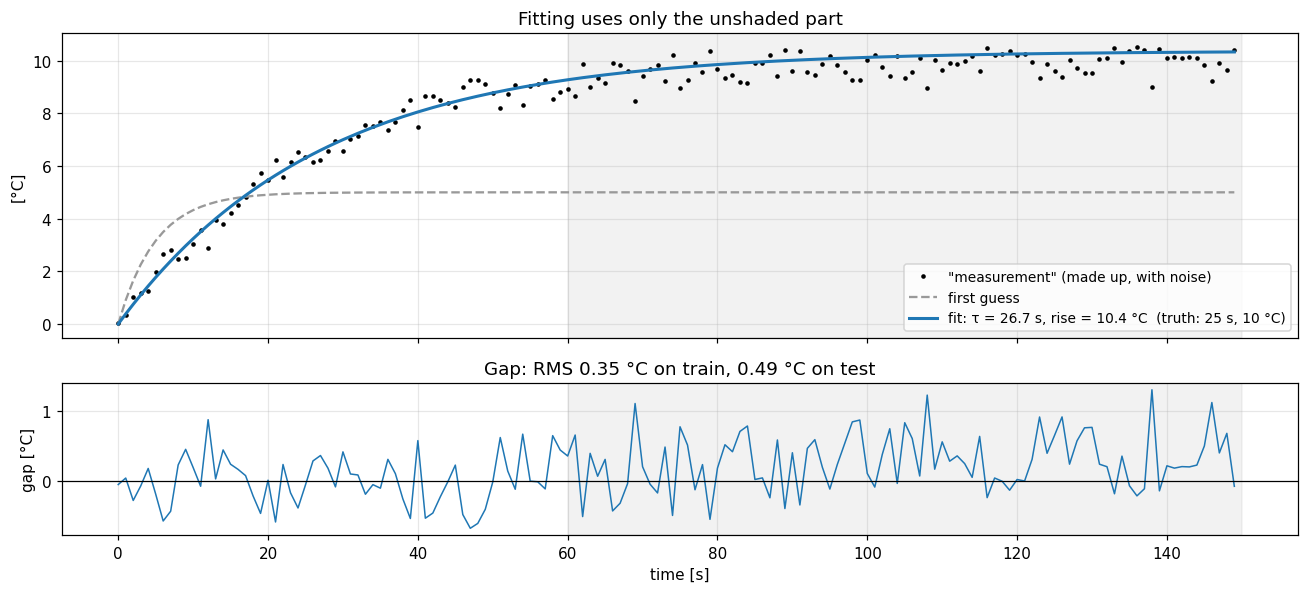

In [6]:
def toy_fit():
    rng = np.random.default_rng(0)
    t = np.arange(0.0, 150.0, 1.0); true_tau, true_rise = 25.0, 10.0
    curve = lambda q, t: q[1] * (1 - np.exp(-t / q[0]))
    meas = curve([true_tau, true_rise], t) + rng.normal(0, 0.4, len(t))
    tr = t < 60
    s = least_squares(lambda q: curve(q, t[tr]) - meas[tr], [5.0, 5.0])
    fit = curve(s.x, t); gap = fit - meas
    fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    ax[0].plot(t, meas, '.', color='k', ms=4, label='"measurement" (made up, with noise)')
    ax[0].plot(t, curve([5.0, 5.0], t), color='0.6', ls='--', label='first guess')
    ax[0].plot(t, fit, color=MAIN_C, lw=2, label=f'fit: τ = {s.x[0]:.1f} s, rise = {s.x[1]:.1f} °C  (truth: {true_tau:.0f} s, {true_rise:.0f} °C)')
    ax[0].set(ylabel='[°C]', title='Fitting uses only the unshaded part'); ax[0].legend(fontsize=9)
    ax[1].plot(t, gap, color=MAIN_C, lw=1); ax[1].axhline(0, color='k', lw=0.8)
    ax[1].set(xlabel='time [s]', ylabel='gap [°C]', title=f'Gap: RMS {np.sqrt(np.mean(gap[tr]**2)):.2f} °C on train, {np.sqrt(np.mean(gap[~tr]**2)):.2f} °C on test')
    for a in ax: a.axvspan(60, 150, color='0.5', alpha=0.1)
    fig.tight_layout(); fig.savefig(FIG / 'cg_idea_fitting.png', bbox_inches='tight')

toy_fit()

**How to read this figure.** Black dots are the "measurement". The grey dashes are the starting guess, which is well off. The blue line is where the search ended. The lower panel shows the gap between blue and the dots.

The fit found τ = 26.7 s and a rise of 10.4 °C, close to the truth of 25 s and 10 °C, using only the first 60 s. The gap is 0.35 °C on train and 0.49 °C on test. The noise we added was 0.4 °C, so no model could honestly get far below that. Test error is a little worse than train, and that's normal. **When you see "RMS train / test" later, this is what it means.** Train and test being close says the model isn't just memorising the data.

Those are all the ideas. The next few cells hold reference material: the same plan in technical terms, the papers it builds on, a units table, and the fixed numbers the code uses. **On a first read you can skip ahead to Part 1.**

### The same plan in technical terms

`liquid_bl_rochpl.ipynb` drove a liquid boundary layer directly with GPU power. Frontier doesn't cool that way: each MI250X sits on a
warm-water **cold plate**, 128 nodes share a cabinet's coolant, and three cabinets share one **coolant distribution unit (CDU)** whose
heat exchanger hands the heat to the facility loop. This notebook builds that chain, fits each link to measured Frontier data, and
runs arbitrary workload power traces through it:

```
per-GPU power trace ─► node power ─► 128 nodes ─► cabinet DC ─► cabinet AC ──────────────┐
  (ms, rocm_smi)        (craypm)      (sync/desync)   (Redfish)    (rectifiers)            ▼
                                                                         cabinet thermal mass ─► secondary return
GPU junction T, heat flux ◄─ die/TIM/cold-plate RC network ◄─ coolant temperature  ◄─ CDU heat exchanger + valve controller
                                                                                            ▲
                                                                              facility (primary) supply temperature
```

1. **Load the cooling-group telemetry** (`3Cab_POW.txt`: 3 cabinets + their CDU, 1 Hz, 47 min, a 3-cabinet HPL run) and check the energy balance.
2. **Power chain**: Redfish node power → cabinet DC → cabinet AC, measured vs. the RAPS loss model of the ExaDigiT digital twin [1, 2].
3. **Cooling-group dynamics**: cabinet thermal mass, CDU counterflow heat exchanger, primary-valve PI controller. Fitted on the first 1 400 s, tested on the rest, then run closed-loop from AC power and facility supply temperature alone.
4. **GPU junction model**: a 3-node Cauer (die → package → cold plate → coolant) network fitted to the measured MI250X junction temperature of the single-node rocHPL trace (Ampere). Outputs junction temperature and the heat flux through each layer.
5. **Single node → cabinet**: build cabinet power from one node's trace with 128 synchronised or desynchronised copies, and compare its fluctuation level with the measured cabinet.
6. **End-to-end scenarios**: replay the measured HPL run with ms-scale GPU structure, a synthetic periodic workload, and a sweep of workload periods (10 s to 2 h) showing what the cooling infrastructure passes, damps or amplifies at the GPU junction.

Everything downstream of the power trace is a function call (`run_chain`), so any power trace can be dropped in.

### Literature this builds on

| # | Reference | What it contributes here |
|---|---|---|
| 1 | W. Brewer, M. Maiterth, V. Kumar, R. Wojda, S. Bouknight, J. Hines, W. Shin, S. Greenwood, D. Grant, W. Williams, F. Wang, "A Digital Twin Framework for Liquid-cooled Supercomputers as Demonstrated at Exascale," *SC24*, 2024. [doi:10.1109/SC41406.2024.00029](https://doi.org/10.1109/SC41406.2024.00029), [arXiv:2410.05133](https://arxiv.org/abs/2410.05133) | ExaDigiT: RAPS turns per-node utilisation into rack and system power (with rectifier and SIVOC losses) and drives a Modelica cooling model. Validated against Frontier telemetry. The direct precedent for "single node data → cabinet AC power". |
| 2 | ExaDigiT RAPS source, [github.com/ExaDigiT/RAPS](https://github.com/ExaDigiT/RAPS) (`config/frontier.yaml`, `raps/power.py`) | Exact Frontier constants: 128 nodes/rack, 32 rectifiers/rack, 32 × 250 W switches/rack, SIVOC $P_{in}=(P+13\,\mathrm{W})/0.98$ per node, rectifier $P_{in}=(P+17\,\mathrm{W})/0.96$ per rectifier, 3 racks per CDU, CDU pump ≈ 8.5 kW. |
| 3 | V. Kumar, S. Greenwood, W. Brewer, W. Williams, D. Grant, N. Parkison, "Thermo-Fluid Modeling Framework for Supercomputer Digital Twins: Part 1, Demonstration at Exascale," *American Modelica Conference*, 2024. [osti:2480044](https://www.osti.gov/biblio/2480044) | Frontier's cooling topology: 25 operating CDUs (27 installed), ≤ 3 cabinets each, ~1.6 MW CDU capacity, 250–300 gpm secondary flow, primary valve controls secondary supply temperature. The basis for the "cooling group" (3 cabinets + 1 CDU) in this notebook. |
| 4 | ExaDigiT datacenterCoolingModel, [github.com/ExaDigiT/datacenterCoolingModel](https://github.com/ExaDigiT/datacenterCoolingModel) | Modelica (TRANSFORM) cabinet/CDU records, e.g. 21.9 US gal of coolant per cabinet. |
| 5 | Z. Sun et al., "Energy dataset of Frontier supercomputer for waste heat recovery," *Scientific Data* 11:1077, 2024. [doi:10.1038/s41597-024-03913-w](https://doi.org/10.1038/s41597-024-03913-w) | A year of plant data. 97–99 % of the heat leaves through liquid, PUE ≈ 1.05. Justifies "all cabinet AC power ends up in the coolant". |
| 6 | W. Shin, V. Oles, A. M. Karimi, J. A. Ellis, F. Wang, "Revealing power, energy and thermal dynamics of a 200PF pre-exascale supercomputer," *SC21*, 2021. [doi:10.1145/3458817.3476188](https://doi.org/10.1145/3458817.3476188) | Summit: job-driven power swings, GPU temperatures following power edges, ~1 min lag before the plant reacts. The cabinet time constant fitted here (≈ 66–78 s) is the Frontier analogue. |
| 7 | S. Atchley et al., "Frontier: Exploring Exascale," *SC23*, 2023. [doi:10.1145/3581784.3607089](https://doi.org/10.1145/3581784.3607089) | Node architecture: 1 EPYC 7A53, 4 MI250X (8 GCDs), 4 Slingshot NICs. |
| 8 | A. M. Karimi, M. Maiterth, W. Shin, N. Sattar, H. Lu, F. Wang, "Exploring the Frontiers of Energy Efficiency using Power Management at System Scale," *SC24 Workshops*, 2024. [doi:10.1109/SCW63240.2024.00230](https://doi.org/10.1109/SCW63240.2024.00230) | Frontier power capping/DVFS. Relevant when the workload trace itself is shaped by caps. |
| 9 | T. Wilde, M. Ott, et al., "First Analysis on Cooling Temperature Impacts on MI250X Exascale Nodes (HPE Cray EX235a)," *CUG 2024*. [slides](https://cug.org/proceedings/cug2024_proceedings/includes/files/pres106s2.pdf) | Node HPL power rises from 2 582 W to 2 651 W as coolant inlet goes 25 → 40 °C (leakage). Coolant flows serially across a blade, so the downstream GPU runs hotter, consistent with the per-GPU offsets fitted in Part 4. |
| 10 | W. Huang, S. Ghosh, S. Velusamy, K. Sankaranarayanan, K. Skadron, M. Stan, "HotSpot: A compact thermal modeling methodology for early-stage VLSI design," *IEEE TVLSI* 14(5), 2006. | Compact RC (Cauer) thermal networks for chip packages: the form of the junction model in Part 4. |

MI250X facts used: 2 GCDs × 724 mm² per package (TechPowerUp database), 560 W peak board power (AMD product page). AMD does not publish a junction-to-coolant resistance or Tjmax for the OAM; both are fitted or left open here.

### Units cheat sheet

| Unit | What it is | Everyday reading |
|---|---|---|
| **kW**, **MW** | power | One Frontier cabinet draws ~90 kW idle and ~330 kW during HPL. A cooling group (3 cabinets) is ~1 MW. |
| **gpm** | US gallons per minute of coolant | 1 gpm of water carries 263 W per °C of temperature rise. 100 gpm ≈ 6.3 L/s. |
| **kW/K** | heat a coolant stream carries per degree of warming ($\dot m c_p$) | 28 kW/K and 320 kW → the cabinet warms its coolant by ~11 °C. |
| **K/W** | thermal resistance | 0.05 K/W × 560 W = 28 °C between the GPU junction and the coolant. |
| **J/K**, **MJ/K** | heat capacity ("thermal mass") | Time constant = resistance × capacity, e.g. 0.016 K/W × 2 J/K ≈ 30 ms for the silicon die. |
| **W/cm²** | heat flux | 560 W over the 14.5 cm² of the two MI250X dies ≈ 39 W/cm². |
| **LIT / LOT** | cabinet liquid **i**nlet / **o**utlet temperature (secondary loop) | The GPU's coolant is LIT plus whatever its blade adds upstream of it. |
| **PIT / POT / PLF** | CDU **p**rimary (facility side) **i**nlet / **o**utlet temperature, **f**low | The facility water that finally carries the heat away. |

### Fixed numbers and assumptions

Everything that is an assumption rather than a fit lives here.

* **Coolant**: water properties are used to turn gpm into kW/K. Sun et al. [5] list a 50/50 water–glycol mix ($\rho c_p$ ≈ 11 % lower) without saying which loop it is in. Fitted quantities are reported in kW/K, which doesn't depend on that choice; only the gpm equivalents do.
* **All cabinet AC power ends up in the coolant**: HPE Cray EX compute cabinets are fanless, and [5] measures 97–99 % heat-to-liquid.
* **Die area** converts GPU power to junction heat flux: 2 × 724 mm² per MI250X (the same 14.5 cm² as `liquid_bl_rochpl.ipynb`).
* **Train/test split**: the cooling-group fits use only $t$ < 1 400 s (idle tail of a previous job, the HPL step, the plateau). The HPL ramp-down and the idle period after it are held out.

In [7]:
# --- Data ---
CG_FILE = ROOT / '3Cab_POW.txt'                 # 3 cabinets + 1 CDU, 1 Hz (one Frontier cooling group)
TRACE = ROOT / 'data' / 'rochpl-frontier'       # single-node rocHPL trace (Ampere CSV export), as in liquid_bl_rochpl.ipynb
CABS = [1, 2, 3]

# --- Coolant (water) ---
RHO_W, CP_W = 998.0, 4180.0
GPM_WK = 6.309e-5 * RHO_W * CP_W                # W/K carried by 1 gpm of water (~263)

# --- Frontier topology and RAPS power constants [1, 2] ---
N_NODES = 128                                   # nodes per cabinet
N_RECT, N_SWITCH, P_SWITCH = 32, 32, 250.0      # rectifiers per cabinet, Slingshot switches per cabinet, W per switch
SIVOC = (13.0, 0.98)                            # P_in = (P + 13 W) / 0.98 per node
RECT = (17.0, 0.96)                             # P_in = (P + 17 W) / 0.96 per rectifier

# --- MI250X ---
A_DIE_CM2 = 2 * 7.24                            # two 724 mm^2 GCDs per package
OAM_DEVICES = [0, 2, 4, 6]                      # rocm_smi devices that carry each package's energy counter and junction sensor

# --- Grids and fitting ---
DT_CG = 1.0                                     # cooling-group time step [s]
DT_GPU = 1e-3                                   # GPU/junction time step [s]
T_SPLIT = 1400.0                                # cooling-group fits use t < T_SPLIT; the rest is held out

## Part 1: What the sensors recorded

**The question.** What did a real cooling group do during a real job, and do the numbers make physical sense?

**What it is.** The file `3Cab_POW.txt` is a recording of one cooling group (3 cabinets and their CDU), one row per second for 47 minutes, on 24 February 2026. During it, all 3 cabinets ran HPL.

**What goes in and out.** In: the text file. Out: a clean table, one row per second, and a check that the energy adds up.

**Why check the energy?** Heat can't vanish. The electricity going in should equal the heat the building water carries away. If that fails, we've misunderstood a sensor. It's our test that the column meanings below are right, since the file doesn't define them.

The columns have terse names. This is how they're read here, with the guessed ones marked.

| Column | Read as | Basis |
|---|---|---|
| `ACP_Cn` | cabinet *n* AC input power [W] | 90 kW idle, ~340 kW HPL |
| `DCP_Cn` | cabinet *n* DC (380 V bus) power [W] | slightly below ACP, noisier |
| `HSNP_Cn` | Slingshot (high-speed network) switch power [W] | ≈ 8.9 kW ≈ RAPS's 32 × 250 W |
| `RFNP_Cn` | sum of node power reported via Redfish [W] | 470 W/node idle, 2.2 kW/node peak *(inferred name)* |
| `NPMC_Cn` | sum of node `pm_counters` | all zero (`SKIP_PMC=1` in the preamble) |
| `LIT_Cn`, `LOT_Cn` | cabinet liquid inlet/outlet temperature [°C] | secondary loop |
| `CDU_PLF` | CDU primary-loop flow [gpm] | *inferred*: in gpm, flow × ΔT closes the energy balance below |
| `CDU_PIT`, `CDU_POT` | CDU primary inlet/outlet temperature [°C] | facility water, 21 °C supply in February |
| `CDU_POW` | CDU power [W] | ≈ 9.3 kW, flat: constant-speed pumps (RAPS: 8.5 kW) |

A few rows are missing (gaps of 5–18 s, six in total). The code fills them with straight lines so there's one value per second.

**What the next two cells do.** The first reads the file and compares electricity in with heat out. The second draws the overview.

**How to read the printed energy check.** "sum AC" is the electricity going in. "primary heat" is the building water's flow × how much it warmed × 263 W per gpm per °C. A ratio of 1 would be a perfect match. The ratios of 1.06 and 0.93 are within 7 %, which is good for sensors like these, and supports reading `CDU_PLF` as gallons per minute.

In [8]:
def load_cooling_group(path):
    '''Read a cooling-group telemetry dump (debug preamble, then a whitespace table starting at the INDEX header).

    Returns (raw table, table on a uniform DT_CG grid indexed by seconds since the first row).
    '''
    lines = Path(path).read_text().splitlines()
    hdr = next(i for i, l in enumerate(lines) if l.startswith('INDEX'))
    raw = pd.read_csv(path, sep=r'\s+', skiprows=hdr)
    t = (pd.to_datetime(raw.TS) - pd.to_datetime(raw.TS.iloc[0])).dt.total_seconds().to_numpy()
    tg = np.arange(0.0, np.floor(t[-1]) + DT_CG, DT_CG)
    cols = [c for c in raw.columns if c not in ('INDEX', 'TS')]
    cg = pd.DataFrame({c: np.interp(tg, t, raw[c].to_numpy(float)) for c in cols}, index=pd.Index(tg, name='t_s'))
    return raw, cg

raw_cg, cg = load_cooling_group(CG_FILE)
t_cg = cg.index.to_numpy()
AC = np.array([cg[f'ACP_C{i}'] for i in CABS])               # W, shape (3, n)
LIT_m = np.array([cg[f'LIT_C{i}'] for i in CABS]); LOT_m = np.array([cg[f'LOT_C{i}'] for i in CABS])
PIT, POT, PLF = cg.CDU_PIT.to_numpy(), cg.CDU_POT.to_numpy(), cg.CDU_PLF.to_numpy()
LIT = LIT_m.mean(0)                                          # the 3 cabinets share one supply header
train = t_cg < T_SPLIT
gaps = np.diff((pd.to_datetime(raw_cg.TS) - pd.to_datetime(raw_cg.TS.iloc[0])).dt.total_seconds().to_numpy())
print(f"{raw_cg.TS.iloc[0]} -> {raw_cg.TS.iloc[-1]}: {len(raw_cg)} rows, {t_cg[-1]:.0f} s; gaps > 1.5 s: {np.round(gaps[gaps > 1.5], 1)}")

# Energy balance: AC power in vs. heat carried away by the primary (facility) water
Q_prim = PLF * GPM_WK * (POT - PIT)
for name, a, b in [('idle tail', 2200, 2800), ('HPL plateau', 700, 1300)]:
    m = (t_cg > a) & (t_cg < b)
    print(f"{name:12s}: sum AC {AC[:, m].sum(0).mean()/1e3:6.1f} kW, primary heat {Q_prim[m].mean()/1e3:6.1f} kW "
          f"(ratio {Q_prim[m].mean()/AC[:, m].sum(0).mean():.3f})")

2026-02-24T20:14:13.385994735Z -> 2026-02-24T21:01:29.386283669Z: 2794 rows, 2836 s; gaps > 1.5 s: [ 6.1 18.1  6.   5.   6.1  8. ]
idle tail   : sum AC  269.4 kW, primary heat  285.8 kW (ratio 1.061)
HPL plateau : sum AC  960.9 kW, primary heat  892.1 kW (ratio 0.928)


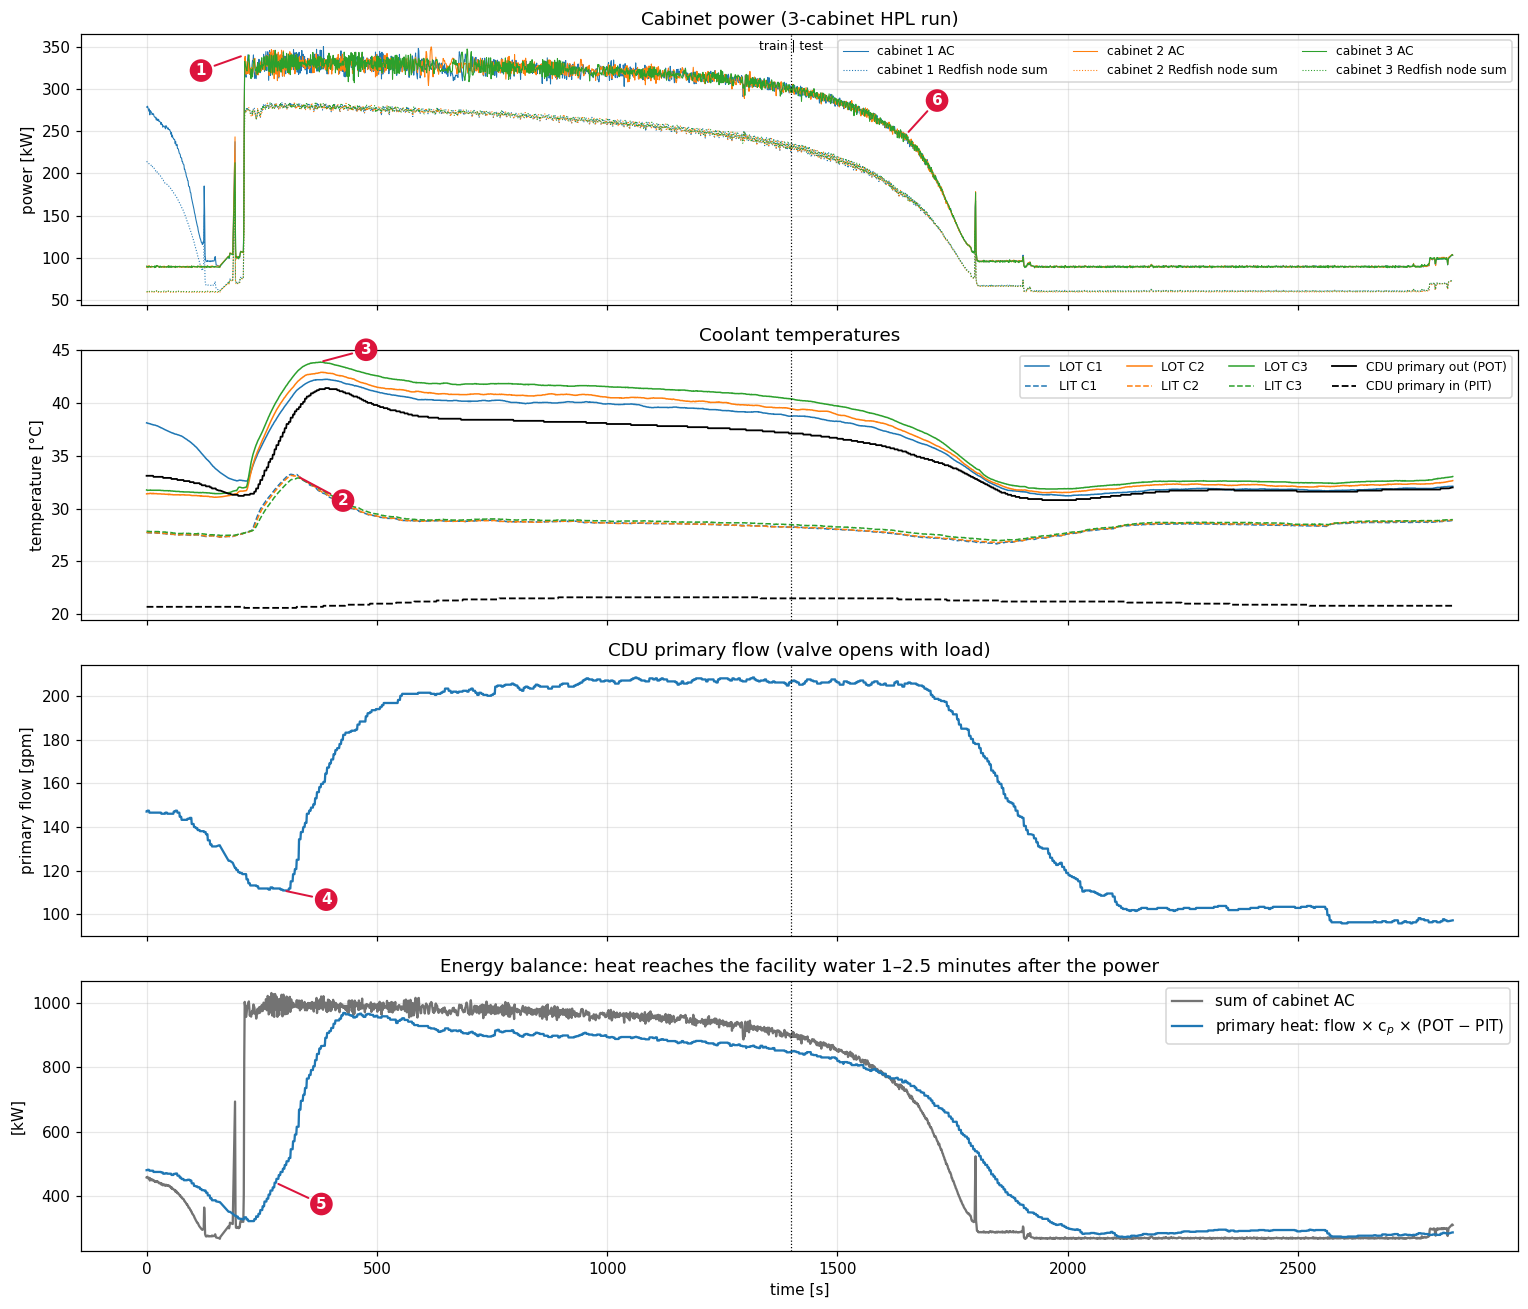

In [9]:
def fig_overview():
    fig, ax = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
    for j, i in enumerate(CABS):
        ax[0].plot(t_cg, AC[j] / 1e3, color=CAB_C[j], lw=0.7, label=f'cabinet {i} AC')
        ax[0].plot(t_cg, cg[f'RFNP_C{i}'] / 1e3, color=CAB_C[j], lw=0.7, ls=':', label=f'cabinet {i} Redfish node sum')
        ax[1].plot(t_cg, LOT_m[j], color=CAB_C[j], lw=1, label=f'LOT C{i}')
        ax[1].plot(t_cg, LIT_m[j], color=CAB_C[j], lw=1, ls='--', label=f'LIT C{i}')
    ax[0].set(ylabel='power [kW]', title='Cabinet power (3-cabinet HPL run)'); ax[0].legend(ncol=3, fontsize=8)
    ax[1].plot(t_cg, POT, 'k', lw=1.2, label='CDU primary out (POT)'); ax[1].plot(t_cg, PIT, 'k--', lw=1.2, label='CDU primary in (PIT)')
    ax[1].set(ylabel='temperature [°C]', title='Coolant temperatures'); ax[1].legend(ncol=4, fontsize=8)
    ax[2].plot(t_cg, PLF, color=MAIN_C); ax[2].set(ylabel='primary flow [gpm]', title='CDU primary flow (valve opens with load)')
    ax[3].plot(t_cg, AC.sum(0) / 1e3, color=POWER_C, label='sum of cabinet AC')
    ax[3].plot(t_cg, Q_prim / 1e3, color=MAIN_C, label='primary heat: flow × c$_p$ × (POT − PIT)')
    ax[3].set(xlabel='time [s]', ylabel='[kW]', title='Energy balance: heat reaches the facility water 1–2.5 minutes after the power'); ax[3].legend()
    for a in ax: a.axvline(T_SPLIT, color='k', lw=0.8, ls=':')
    ax[0].annotate('train | test', (T_SPLIT, ax[0].get_ylim()[1] * 0.95), ha='center', fontsize=8)
    near = (t_cg > 211) & (t_cg < 800)
    mark(ax[0], 1, 211, 340, dx=-28, dy=-10)
    i = np.argmax(np.where(near, LIT, -np.inf)); mark(ax[1], 2, t_cg[i], LIT[i], dx=30, dy=-16)
    i = np.argmax(np.where(near, LOT_m[2], -np.inf)); mark(ax[1], 3, t_cg[i], LOT_m[2][i], dx=30, dy=8)
    i = np.argmin(np.where(near, PLF, np.inf)); mark(ax[2], 4, t_cg[i], PLF[i], dx=28, dy=-6)
    i = int(np.searchsorted(t_cg, 280)); mark(ax[3], 5, t_cg[i], Q_prim[i] / 1e3, dx=30, dy=-14)
    mark(ax[0], 6, 1650, AC[0][int(np.searchsorted(t_cg, 1650))] / 1e3, dx=20, dy=22)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part1_overview.png', bbox_inches='tight')

fig_overview()

**How to read this figure.** It's one story told in four panels, sharing the same time axis. The dotted vertical line at 1 400 s is where fitting stops in Part 3.

1. **The job starts** at about t = 211 s. Each cabinet jumps from about 110 kW to about 330 kW within seconds. Solid lines are the electricity into each cabinet, and dotted lines are what its computers report.
2. **The water going back to the cabinets (LIT) overshoots.** It starts at about 27.5 °C and peaks at 33.1 °C, 116 s after the job starts. That's about 4.4 °C above the 28.6 °C target. It stays more than 1 °C above target for about 4 minutes.
3. **The water leaving the cabinets (LOT) climbs to 42–44 °C** about 2.8 minutes after the job starts. It takes that long because the cabinet's metal has to warm first.
4. **The valve starts late.** The building-water flow is still falling (the previous job's wind-down) until 86 s after the step, then it climbs, reaching 90 % of its rise about 5 minutes after the step. Point 2 happens because the heat arrives faster than the valve opens. Part 3 tests how much of that is down to the delay.
5. **Energy balance.** Heat in the building water (blue) trails the electricity (grey), reaching half the plateau 71 s after the step and 90 % after 151 s. The gap between the curves is heat being stored in the warming hardware and water. From about 450 s they run nearly parallel, a few percent apart.
6. **HPL's power decays by itself.** As the benchmark progresses, its remaining matrix shrinks, so power falls. It's a normal feature of HPL, and gives a slow, gentle shutdown around 1 400–1 800 s.

The two curves in panel 4 stay apart by a few percent, in opposite directions at idle and at load. A roughly 12 % calibration factor on the building-water side, fitted in Part 3 and called $\kappa$, accounts for that.

## Part 2: From the computers' power to the cabinet's electricity

**The question.** The computers report their own power, but the cooling system has to remove all the electricity the *cabinet* draws. How do we get from one to the other?

**The analogy.** A phone charger gets warm: it takes more from the wall than reaches the phone. A cabinet has the same kind of losses, plus equipment the computers don't count, such as network switches.

**What goes in and out.** In: the summed power reported by a cabinet's 128 nodes (`RFNP`, called the *node sum*). Out: the cabinet's AC power (`ACP`), which all ends up as heat in the water.

**What the published model says.** ORNL's digital twin of Frontier (RAPS [1, 2]) has formulas for this path:

| Step | What happens | Formula in words |
|---|---|---|
| Node voltage converter (SIVOC) | 380 V down to 48 V, one per node | power in = (node power + 13 W) ÷ 0.98 |
| Network switches | 32 per cabinet | add 32 × 250 W |
| Rectifier | AC to 380 V DC, 32 per cabinet | power in = (its share + 17 W) ÷ 0.96 |

**What the next cell does.** It takes 30-second averages, keeps only moments when power is steady (sensors have different timing during fast changes), fits a curve through the measured AC vs. node sum, and compares it with RAPS. In the printout, `N` is the node sum.

In [10]:
def raps_cabinet_ac(node_sum_W, n_nodes=N_NODES):
    '''RAPS power-conversion model [2] (raps/power.py): node sum [W] -> cabinet AC input [W].

    SIVOC per node: (P_node + 13) / 0.98. Switches add N_SWITCH * 250 W on the DC bus. The DC bus is split evenly over
    N_RECT rectifiers, each drawing (P + 17) / 0.96 from AC.
    '''
    dc = n_nodes * (np.asarray(node_sum_W) / n_nodes + SIVOC[0]) / SIVOC[1] + N_SWITCH * P_SWITCH
    return N_RECT * (dc / N_RECT + RECT[0]) / RECT[1], dc

# Use 30 s means where the node sum is steady (ramps mix the sensors' different timing)
sm = lambda x: uniform_filter1d(x, 30, axis=-1)
RF = np.array([cg[f'RFNP_C{i}'] for i in CABS]); DC = np.array([cg[f'DCP_C{i}'] for i in CABS])
RFs, ACs, DCs = sm(RF), sm(AC), sm(DC)
steady = np.abs(np.gradient(RFs, axis=1)) < 50              # node sum changing < 50 W/s
x, y = RFs[steady], ACs[steady]
AC_POLY = np.polyfit(x, y, 2)
RF_RANGE = (x.min(), x.max())
RAPS_SLOPE = 1 / (SIVOC[1] * RECT[1])                        # incremental AC per W of node power in RAPS

def cabinet_ac_from_nodes(node_sum_W):
    '''Cabinet AC [W] from the cabinet's node-power sum [W], fitted to the measured cooling group.

    Inside the measured range a quadratic. Outside it, a straight-line continuation with RAPS's incremental slope
    (1 / (0.98 * 0.96)) so extrapolation stays physical.
    '''
    x = np.asarray(node_sum_W, float)
    lo, hi = RF_RANGE
    xc = np.clip(x, lo, hi)
    return np.polyval(AC_POLY, xc) + RAPS_SLOPE * (x - xc)

ac_raps, dc_raps = raps_cabinet_ac(x)
print(f"fit: AC = {AC_POLY[0]:.3e}*N^2 + {AC_POLY[1]:.3f}*N + {AC_POLY[2]/1e3:.1f} kW  (RMS {np.std(y - np.polyval(AC_POLY, x))/1e3:.2f} kW)")
for lo, hi, name in [(55e3, 70e3, 'idle'), (260e3, 290e3, 'HPL peak')]:
    m = (x > lo) & (x < hi)
    print(f"{name:8s}: node sum {x[m].mean()/1e3:5.1f} kW ({x[m].mean()/N_NODES:4.0f} W/node) | AC measured {y[m].mean()/1e3:5.1f}, "
          f"RAPS {ac_raps[m].mean()/1e3:5.1f} kW | DC measured {DCs[steady][m].mean()/1e3:5.1f}, RAPS {dc_raps[m].mean()/1e3:5.1f} kW | "
          f"switches {np.mean([cg[f'HSNP_C{i}'].mean() for i in CABS])/1e3:.1f} kW")

fit: AC = -2.598e-06*N^2 + 1.987*N + -21.1 kW  (RMS 1.44 kW)
idle    : node sum  60.8 kW ( 475 W/node) | AC measured  90.1, RAPS  75.3 kW | DC measured  86.5, RAPS  71.7 kW | switches 8.9 kW
HPL peak: node sum 272.3 kW (2128 W/node) | AC measured 327.1, RAPS 300.1 kW | DC measured 294.5, RAPS 287.6 kW | switches 8.9 kW


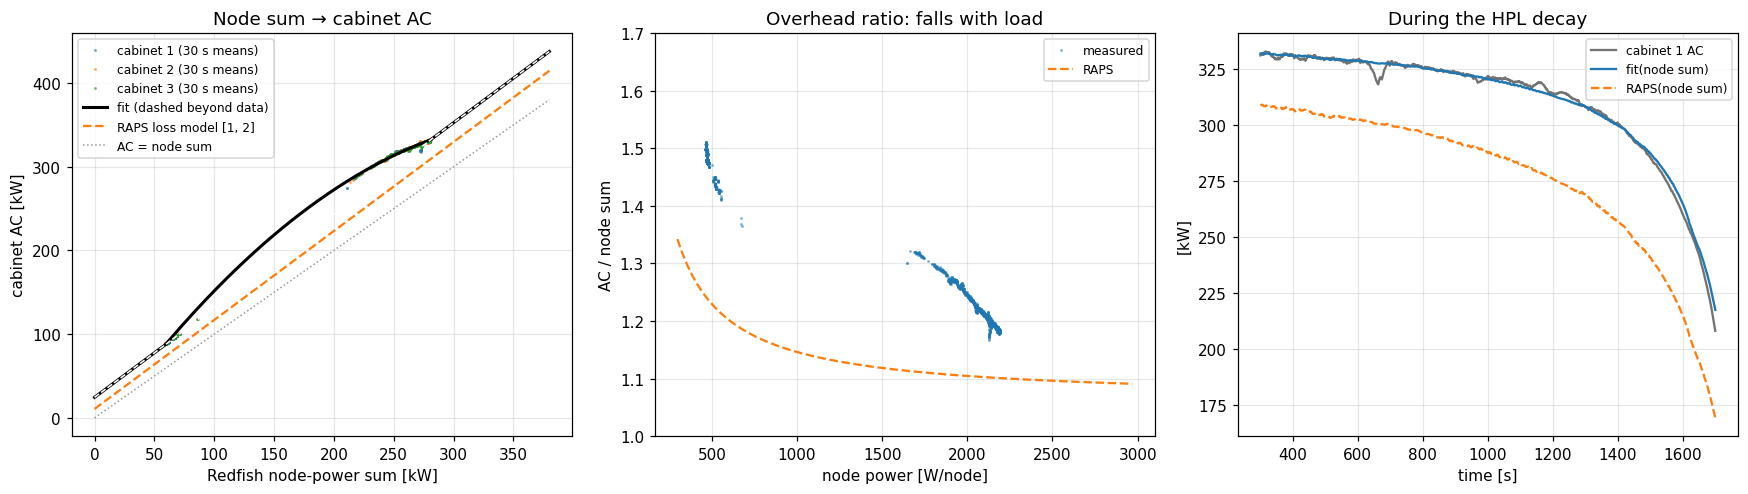

In [11]:
def fig_power_chain():
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    a = ax[0]; xx = np.linspace(0, 380e3, 200)
    for j in range(3):
        a.plot(RFs[j][steady[j]] / 1e3, ACs[j][steady[j]] / 1e3, '.', ms=2, color=CAB_C[j], alpha=0.5, label=f'cabinet {CABS[j]} (30 s means)')
    a.plot(xx / 1e3, cabinet_ac_from_nodes(xx) / 1e3, 'k', lw=2, label='fit (dashed beyond data)')
    a.plot(xx[(xx < RF_RANGE[0]) | (xx > RF_RANGE[1])] / 1e3, cabinet_ac_from_nodes(xx[(xx < RF_RANGE[0]) | (xx > RF_RANGE[1])]) / 1e3, 'w--', lw=1)
    a.plot(xx / 1e3, raps_cabinet_ac(xx)[0] / 1e3, color=CMP_C, lw=1.5, ls='--', label='RAPS loss model [1, 2]')
    a.plot(xx / 1e3, xx / 1e3, color='0.6', lw=1, ls=':', label='AC = node sum')
    a.set(xlabel='Redfish node-power sum [kW]', ylabel='cabinet AC [kW]', title='Node sum → cabinet AC'); a.legend(fontsize=8)
    a = ax[1]
    a.plot(x / N_NODES, y / x, '.', ms=2, color=MAIN_C, alpha=0.4, label='measured')
    a.plot(xx[20:] / N_NODES, raps_cabinet_ac(xx[20:])[0] / xx[20:], color=CMP_C, ls='--', label='RAPS')
    a.set(xlabel='node power [W/node]', ylabel='AC / node sum', ylim=(1, 1.7), title='Overhead ratio: falls with load'); a.legend(fontsize=8)
    a = ax[2]; m = (t_cg > 300) & (t_cg < 1700)
    a.plot(t_cg[m], ACs[0][m] / 1e3, color=POWER_C, label='cabinet 1 AC')
    a.plot(t_cg[m], cabinet_ac_from_nodes(RFs[0][m]) / 1e3, color=MAIN_C, label='fit(node sum)')
    a.plot(t_cg[m], raps_cabinet_ac(RFs[0][m])[0] / 1e3, color=CMP_C, ls='--', label='RAPS(node sum)')
    a.set(xlabel='time [s]', ylabel='[kW]', title='During the HPL decay'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part2_power_chain.png', bbox_inches='tight')

fig_power_chain()

**How to read this figure.**

* **Left:** each dot is a 30-second average. Horizontal is what the computers report, vertical is what the cabinet draws. The black line is our fit, the orange dashes are RAPS, and the dotted line is where the two would be equal. Dots only exist near idle (lower left) and at high load (upper right).
* **Middle:** the same data as a ratio, AC ÷ node sum. A ratio of 1.5 means the cabinet draws 50 % more than its computers report.
* **Right:** cabinet 1 over the HPL decay. Blue (our fit) lies on grey (measured). Orange (RAPS) has the same shape but sits lower.

**What this shows.** RAPS's published conversion losses applied to the Redfish node sum **under-predict cabinet AC by ~15 kW at idle (16 %) and ~27 kW at the HPL peak (8 %)**.

* At idle the whole gap is on the DC side. Measured DC is ~15 kW above RAPS's node + switch total, so there's cabinet load that the per-node Redfish sum doesn't see: blade and chassis controllers, other unmonitored loads, or a different measurement point.
* At the peak the DC gap is only ~7 kW, and the rest is conversion: measured AC/DC is 1.11 against RAPS's 1.04.
* Cabinet AC barely moves while the node sum decays through HPL (right), so the overhead isn't a constant fraction.

The run has steady data only near idle (about 60–85 kW node sum) and from about 210 to 281 kW, so the curve in between is interpolation. `cabinet_ac_from_nodes` is therefore the empirical fit inside 59–281 kW of node sum, continued with RAPS's slope outside it. Use RAPS's form when you need the loss breakdown, and this fit when you need the AC power that actually heats the coolant.

## Part 3: A model of the cabinets, the CDU and the valve

**The question.** Can a simple model reproduce the temperatures and valve flow in Part 1, using only the electricity going in and the building water's temperature?

**What goes in and out.** In: the 3 cabinets' AC power and the building water's incoming temperature (PIT). Out: water temperatures (LIT, LOT, POT) and the valve's flow (PLF), second by second.

There are three pieces. Each uses Ideas 1–5.

### Piece 1: The cabinet, a warm metal block in a stream

**The analogy.** Picture a big block of metal with a heater in it and a stream running past. The block has to warm before it can pass on more heat, so the stream's temperature changes late (Idea 3).

$$C_h \frac{dT_h}{dt} = P_{AC}(t) - \varepsilon\,\dot m c_p\,(T_h - T_{in}), \qquad T_{out} = T_{in} + \varepsilon\,(T_h - T_{in})$$

In words: **how fast the block warms = heat coming in − heat the water takes away.** And: **the water leaves somewhere between its entry temperature and the block's temperature.**

| Symbol | Meaning | How we get it |
|---|---|---|
| $T_h$ | temperature of the cabinet's hardware, treated as one block | computed |
| $C_h$ | its thermal mass | fitted |
| $dT_h/dt$ | how fast that temperature is changing | computed |
| $P_{AC}$ | electricity into the cabinet, all of which becomes heat | measured |
| $\dot m c_p$ | how much heat the water carries per degree of warming (Idea 1) | fitted |
| $T_{in}$, $T_{out}$ | water temperature in (LIT, reaching the cabinet after a short delay $d$) and out (LOT) | computed |
| $UA$ | how easily heat crosses from metal to water | fitted |
| $\varepsilon = 1 - e^{-UA/\dot m c_p}$ | how close the leaving water gets to the block's temperature: 0 is not at all, 1 is all the way | computed from the two above |

### Piece 2: The CDU, two streams swapping heat

**The analogy.** A car radiator, or two pipes pressed together: warm water on one side, cold on the other, metal between. How much heat crosses depends on the temperature difference and on the flow on each side.

$$Q_{hx} = \varepsilon_{hx}\, C_{min}\,(T_{ret} - T_{PIT}), \qquad T_{sup} = T_{ret} - \frac{Q_{hx}}{C_s}, \qquad T_{POT} = T_{PIT} + \kappa\, \frac{Q_{hx}}{C_p}$$

In words: **heat moved = effectiveness × the smaller stream's capacity × the temperature gap between the two entering streams.** Then **each stream's temperature changes by heat moved ÷ its capacity** (Idea 1).

| Symbol | Meaning | How we get it |
|---|---|---|
| $Q_{hx}$ | heat moved across per second | computed |
| $T_{ret}$ | warm water returning from the 3 cabinets, mixed | computed |
| $T_{PIT}$ | building water coming in | measured |
| $T_{sup}$ | water sent back to cabinets, the same as LIT | computed |
| $T_{POT}$ | building water going out | computed |
| $C_s$ | capacity of the cabinet-side flow, the sum of Piece 1's $\dot m c_p$ | fitted in Piece 1 |
| $C_p$ | capacity of the building-side flow: PLF × 263 W/°C per gpm | from the valve |
| $C_{min}$ | whichever of the two is smaller | computed |
| $\varepsilon_{hx}$ | exchanger effectiveness, from a standard textbook formula (ε-NTU, counterflow) using $UA_{hx}$ | computed |
| $UA_{hx}$ | how easily heat crosses the plates | fitted |
| $\kappa$ | calibration factor for the building-side sensors | fitted |

The code also adds a short delay $d_s$ for water to arrive, and short smoothing times $\tau_s$ and $\tau_p$ on the two outlets.

### Piece 3: The valve, a thermostat that reads late

**The analogy.** The shower in Idea 5. Kumar et al. [3] say the valve tracks the supply-water temperature. We model it with the most common controller there is, called a **PI controller**:

$$\mathrm{PLF}_{k+1} = \mathrm{clip}\big(\mathrm{PLF}_k + K_p (e_k - e_{k-1}) + K_i\, e_k\,\Delta t\big), \qquad e = \mathrm{LIT} - T_{set}$$

In words: **each second, change the flow by a bit for how quickly the error is changing, plus a bit for how large the error is.**

| Symbol | Meaning | How we get it |
|---|---|---|
| $\mathrm{PLF}_k$ | building-water flow at second $k$ | computed |
| $e$ | error: how far LIT is above the target, as the controller sees it after a delay $d_c$ | computed |
| $T_{set}$ | the target temperature (setpoint) | fitted |
| $K_p$ | how strongly it responds to a *changing* error ("proportional gain") | fitted |
| $K_i$ | how strongly it responds to a *lasting* error ("integral gain") | fitted |
| $\Delta t$ | time step, 1 s | fixed |
| clip | the valve can only go between the lowest and highest flows seen in the data | measured |

The real controller's logic isn't public. This is the simplest thing that behaves like it, and the fit tells us how well that works.

### How the fitting avoids compounding errors

Each piece is fitted on its own, using *measured* inputs from the pieces next to it. Only then are they joined. **All fits use only the first 1 400 s.** The rest is the unseen test.

**What the next two cells do.** The first defines the equations as functions. The second runs the three fits and prints the results.

In [12]:
def lag1(x, tau, dt=DT_CG):
    '''First-order lag y' = (x - y) / tau, exact for x held constant over each step; starts in steady state at x[0].'''
    a = np.exp(-dt / tau)
    return lfilter([0, 1 - a], [1, -a], x, zi=lfilter_zi([0, 1 - a], [1, -a]) * x[0])[0]

def delay(x, d, dt=DT_CG):
    '''x delayed by d seconds (linear interpolation, edge held).'''
    t = np.arange(len(x)) * dt
    return np.interp(t - d, t, x)

def eps_channel(UA, mcp):
    return 1 - np.exp(-UA / mcp)

def hx_eff(UA, Cs, Cp):
    '''Counterflow heat-exchanger effectiveness times C_min [W/K] (epsilon-NTU).'''
    Cmin, Cmax = np.minimum(Cs, Cp), np.maximum(Cs, Cp)
    cr, ntu = Cmin / Cmax, UA / Cmin
    ex = np.exp(-ntu * (1 - cr))
    eff = np.where(np.abs(1 - cr) < 1e-6, ntu / (1 + ntu), (1 - ex) / (1 - cr * np.maximum(ex, 1e-300)))
    return eff * Cmin

def cabinet_outlet(ac, tin, Ch, UA, mcp, d, dt=DT_CG):
    '''Cabinet outlet temperature [°C] for AC power ac [W] and inlet tin [°C] (the cabinet equations above).

    Ch [J/K], UA and mcp [W/K], d = inlet transport delay [s]. Exact exponential update per step; starts in steady state.
    Returns (outlet temperature, hardware temperature T_h).
    '''
    tin = delay(tin, d, dt); eps = eps_channel(UA, mcp)
    a = np.exp(-dt * eps * mcp / Ch)
    th = np.empty_like(tin); th[0] = tin[0] + ac[0] / (eps * mcp)
    for k in range(1, len(tin)):
        ss = tin[k - 1] + ac[k - 1] / (eps * mcp)
        th[k] = ss + (th[k - 1] - ss) * a
    return tin + eps * (th - tin), th

def cdu_open_loop(tret, pit, plf, p):
    '''CDU outlets for a given return temperature, primary inlet and primary flow (measured inputs). Returns (LIT, POT).'''
    Cs, Cp = p['Cs'], plf * GPM_WK
    tr = delay(tret, p['d_s'])
    Q = hx_eff(p['UA_hx'], Cs, Cp) * (tr - pit)
    return lag1(tr - Q / Cs, p['tau_s']), lag1(pit + p['kappa'] * Q / Cp, p['tau_p']) + p['b_p']

def pi_flow(lit, p, plf0):
    '''Primary flow [gpm] from the PI valve controller driven by a supply-temperature history lit [°C].'''
    e = delay(lit, p['d_c']) - p['T_set']
    u = np.empty_like(e); u[0] = plf0
    for k in range(1, len(e)):
        u[k] = np.clip(u[k - 1] + p['Kp'] * (e[k] - e[k - 1]) + p['Ki'] * e[k] * DT_CG, *p['plf_range'])
    return u

rms = lambda r: float(np.sqrt(np.mean(np.square(r))))

In [13]:
# --- 3a. Cabinets: inlet = measured LIT of that cabinet; LOT sensor offset b fitted ---
CAB = []
for j in range(3):
    def res(q, j=j, m=train):
        Ch, UA, mcp, d, b = q
        return (cabinet_outlet(AC[j], LIT_m[j], Ch * 1e6, UA * 1e3, mcp * 1e3, d)[0] + b - LOT_m[j])[m]
    s = least_squares(res, [1.0, 30, 28, 3, 0], bounds=([0.05, 1, 10, 0, -3], [20, 500, 60, 60, 3]))
    Ch, UA, mcp, d, b = s.x
    p = dict(Ch=Ch * 1e6, UA=UA * 1e3, mcp=mcp * 1e3, d=d, b=b)
    test_rms = rms(res(s.x, m=~train))
    p['tau'] = p['Ch'] / (eps_channel(p['UA'], p['mcp']) * p['mcp'])
    CAB.append(p)
    print(f"cabinet {CABS[j]}: C_h = {p['Ch']/1e6:.2f} MJ/K, UA = {p['UA']/1e3:5.1f} kW/K, m*cp = {p['mcp']/1e3:4.1f} kW/K "
          f"(= {p['mcp']/GPM_WK:4.0f} gpm water), delay {p['d']:.1f} s, LOT offset {p['b']:+.2f} K, tau = {p['tau']:.0f} s | "
          f"RMS train {rms(s.fun):.2f} K, test {test_rms:.2f} K")

TOUT = np.array([cabinet_outlet(AC[j], LIT, CAB[j]['Ch'], CAB[j]['UA'], CAB[j]['mcp'], CAB[j]['d'])[0] for j in range(3)])
MS = np.array([p['mcp'] for p in CAB])
TRET = (MS[:, None] * TOUT).sum(0) / MS.sum()

# --- 3b. CDU heat exchanger: inputs = modelled return temperature, measured PIT and PLF ---
def cdu_params(q):
    return dict(Cs=MS.sum(), UA_hx=q[0] * 1e3, d_s=q[1], tau_s=q[2], tau_p=q[3], kappa=q[4], b_p=q[5])
def res_cdu(q, m=train):
    lit_hat, pot_hat = cdu_open_loop(TRET, PIT, PLF, cdu_params(q))
    return np.concatenate([(lit_hat - LIT)[m], (pot_hat - POT)[m]])
s = least_squares(res_cdu, [300, 10, 10, 10, 0.9, 0], bounds=([10, 0, 0.5, 0.5, 0.6, -5], [5000, 90, 300, 300, 1.4, 5]))
CDU = cdu_params(s.x)
r_tr, r_te = res_cdu(s.x).reshape(2, -1), res_cdu(s.x, ~train).reshape(2, -1)
print(f"CDU: UA_hx = {CDU['UA_hx']/1e3:.0f} kW/K, secondary C_s = {CDU['Cs']/1e3:.1f} kW/K (= {CDU['Cs']/GPM_WK:.0f} gpm), delay {CDU['d_s']:.1f} s, "
      f"tau_s = {CDU['tau_s']:.1f} s, tau_p = {CDU['tau_p']:.1f} s, kappa = {CDU['kappa']:.3f}, POT offset {CDU['b_p']:+.2f} K")
print(f"     RMS LIT train {rms(r_tr[0]):.2f} / test {rms(r_te[0]):.2f} K; POT train {rms(r_tr[1]):.2f} / test {rms(r_te[1]):.2f} K")

# --- 3c. Valve controller: input = measured LIT ---
PLF_RANGE = (PLF.min(), PLF.max())
def ctl_params(q):
    return dict(T_set=q[0], Kp=q[1], Ki=q[2], d_c=q[3], plf_range=PLF_RANGE)
def res_ctl(q, m=train):
    return (pi_flow(LIT, ctl_params(q), PLF[0]) - PLF)[m]
s = least_squares(res_ctl, [28.6, 2, 0.1, 10], bounds=([26, 0, 0, 0], [31, 50, 5, 90]))
CTL = ctl_params(s.x)
print(f"controller: T_set = {CTL['T_set']:.2f} °C, Kp = {CTL['Kp']:.2f} gpm/K, Ki = {CTL['Ki']:.3f} gpm/(K s), "
      f"delay {CTL['d_c']:.0f} s, flow range {PLF_RANGE[0]:.0f}-{PLF_RANGE[1]:.0f} gpm | RMS train {rms(s.fun):.1f}, test {rms(res_ctl(s.x, ~train)):.1f} gpm")

cabinet 1: C_h = 1.62 MJ/K, UA =  35.2 kW/K, m*cp = 29.8 kW/K (=  113 gpm water), delay 2.4 s, LOT offset +0.27 K, tau = 78 s | RMS train 0.15 K, test 0.19 K
cabinet 2: C_h = 1.08 MJ/K, UA =  20.3 kW/K, m*cp = 28.9 kW/K (=  110 gpm water), delay 0.0 s, LOT offset +0.62 K, tau = 74 s | RMS train 0.12 K, test 0.13 K
cabinet 3: C_h = 0.76 MJ/K, UA =  15.1 kW/K, m*cp = 27.0 kW/K (=  102 gpm water), delay 0.0 s, LOT offset +0.62 K, tau = 66 s | RMS train 0.15 K, test 0.16 K
CDU: UA_hx = 336 kW/K, secondary C_s = 85.6 kW/K (= 325 gpm), delay 12.6 s, tau_s = 0.5 s, tau_p = 7.9 s, kappa = 0.884, POT offset +0.94 K
     RMS LIT train 0.15 / test 0.23 K; POT train 0.27 / test 0.33 K


controller: T_set = 28.64 °C, Kp = 5.53 gpm/K, Ki = 0.123 gpm/(K s), delay 68 s, flow range 96-209 gpm | RMS train 2.3, test 10.4 gpm


**How to read the printout above.**

* `cabinet n`: thermal mass `C_h` (0.8–1.6 million J/K), `UA`, the water's `m*cp` (27–30 kW/°C, about 100–115 gpm of water), its delay, a small `LOT offset` for sensor error (+0.3 to +0.6 °C), and the time constant `tau` (66–78 s). `RMS train / test` is the typical gap to the measured outlet: 0.12–0.15 °C on the fitted part, and 0.13–0.19 °C on the part it never saw.
* `CDU`: `UA_hx` of 336 kW/°C, the summed water capacity `C_s`, and `kappa` of 0.884 (the calibration from Part 1). Supply-temperature error is 0.15 °C on train and 0.23 °C on test.
* `controller`: target `T_set` of 28.64 °C, gains, and **a delay of 68 s**. That's the controller effectively acting on a temperature from over a minute ago. It may lump together sensor delay, water transit and valve travel, which the data can't separate.

### Joining the pieces: the whole cooling group

Now the real test. `simulate_cooling_group` connects everything in a loop, as in the real system. The model's supply water feeds its cabinets, their warm water feeds its heat exchanger, that sets the supply temperature, and its valve reacts to that. No temperature or flow sensor is used. The only inputs are the 3 AC powers and the building-water temperature. Engineers call this **closed loop**.

In [14]:
def simulate_cooling_group(ac, pit, cab=CAB, cdu=CDU, ctl=CTL, state=None, dt=DT_CG):
    '''Closed-loop cooling group. ac: (3, n) cabinet AC power [W]; pit: (n,) facility supply [°C] (or a scalar).

    state: dict from a previous call (or from `cooling_group_steady`) to continue from; None starts from the
    controller at setpoint and everything in steady state for ac[:, 0].
    Returns a dict of arrays (LIT, LOT (3, n), TH (3, n), TRET, POT, PLF, QHX) and 'state' to continue from.
    '''
    ac = np.atleast_2d(ac); n = ac.shape[1]; pit = np.broadcast_to(np.asarray(pit, float), (n,))
    mcp = np.array([p['mcp'] for p in cab]); Ch = np.array([p['Ch'] for p in cab])
    eps = eps_channel(np.array([p['UA'] for p in cab]), mcp)
    a_h = np.exp(-dt * eps * mcp / Ch); a_s = np.exp(-dt / cdu['tau_s']); a_p = np.exp(-dt / cdu['tau_p'])
    Cs = mcp.sum()
    dcab = np.array([int(round(p['d'] / dt)) for p in cab]); ds = int(round(cdu['d_s'] / dt)); dc = int(round(ctl['d_c'] / dt))
    H = max(dcab.max(), ds, dc) + 1
    if state is None:
        lit0 = ctl['T_set']
        state = dict(th=lit0 + ac[:, 0] / (eps * mcp), lit_hist=np.full(H, lit0), tret_hist=np.full(H, lit0 + ac[:, 0].sum() / Cs),
                     plf=float(np.clip(ac[:, 0].sum() / (GPM_WK * max(lit0 - pit[0], 1.0)), *ctl['plf_range'])),
                     tpo=pit[0] + cdu['kappa'] * ac[:, 0].sum() / (GPM_WK * 150), e_prev=0.0)
    th = state['th'].copy(); lit_h = list(state['lit_hist']); tret_h = list(state['tret_hist'])
    plf_k, tpo, e_prev, tsup = state['plf'], state['tpo'], state['e_prev'], state['lit_hist'][-1]
    out = {k: np.empty(n) for k in ('LIT', 'TRET', 'POT', 'PLF', 'QHX')}
    out['LOT'] = np.empty((3, n)); out['TH'] = np.empty((3, n))
    for k in range(n):
        tin = np.array([lit_h[-1 - dcab[j]] for j in range(3)])
        tout = tin + eps * (th - tin)
        out['LIT'][k], out['LOT'][:, k], out['TH'][:, k], out['PLF'][k] = lit_h[-1], tout, th, plf_k
        ss = tin + ac[:, k] / (eps * mcp); th = ss + (th - ss) * a_h
        tret_h.append((mcp * tout).sum() / Cs); tret_h.pop(0); out['TRET'][k] = tret_h[-1]
        tr = tret_h[-1 - ds]; Cp = plf_k * GPM_WK
        Q = hx_eff(cdu['UA_hx'], Cs, Cp) * (tr - pit[k]); out['QHX'][k] = Q
        tss, pss = tr - Q / Cs, pit[k] + cdu['kappa'] * Q / Cp
        out['POT'][k] = tpo + cdu['b_p']
        tsup = tss + (tsup - tss) * a_s; tpo = pss + (tpo - pss) * a_p
        lit_h.append(tsup); lit_h.pop(0)
        e = lit_h[-1 - dc] - ctl['T_set']
        plf_k = float(np.clip(plf_k + ctl['Kp'] * (e - e_prev) + ctl['Ki'] * e * dt, *ctl['plf_range'])); e_prev = e
    out['state'] = dict(th=th, lit_hist=np.array(lit_h), tret_hist=np.array(tret_h), plf=plf_k, tpo=tpo, e_prev=e_prev)
    return out

def cooling_group_steady(ac0, pit0, settle_s=6000):
    '''State of the cooling group after holding cabinet AC ac0 (3,) and facility supply pit0 constant for settle_s.'''
    return simulate_cooling_group(np.repeat(np.asarray(ac0, float)[:, None], int(settle_s / DT_CG), 1), pit0)['state']

# Replay the measured run, starting from the measured state at t = 0
H0 = int(round(max([p['d'] for p in CAB] + [CDU['d_s'], CTL['d_c']]))) + 1
eps0 = np.array([eps_channel(p['UA'], p['mcp']) for p in CAB])
st0 = dict(th=LIT[0] + (LOT_m[:, 0] - np.array([p['b'] for p in CAB]) - LIT[0]) / eps0, lit_hist=np.full(H0, LIT[0]),
           tret_hist=np.full(H0, TRET[0]), plf=PLF[0], tpo=POT[0] - CDU['b_p'], e_prev=LIT[0] - CTL['T_set'])
CL = simulate_cooling_group(AC, PIT, state=st0)
LOT_hat = CL['LOT'] + np.array([p['b'] for p in CAB])[:, None]
print("closed loop (inputs: cabinet AC + PIT only)   RMS train / test")
for name, a, b, u in [('LIT', CL['LIT'], LIT, 'K'), ('POT', CL['POT'], POT, 'K'), ('PLF', CL['PLF'], PLF, 'gpm')] + \
                     [(f'LOT C{CABS[j]}', LOT_hat[j], LOT_m[j], 'K') for j in range(3)]:
    print(f"  {name:7s} {rms((a - b)[train]):5.2f} / {rms((a - b)[~train]):5.2f} {u}")

closed loop (inputs: cabinet AC + PIT only)   RMS train / test
  LIT      0.20 /  0.57 K
  POT      0.24 /  0.77 K
  PLF      3.63 /  6.37 gpm
  LOT C1   0.22 /  0.66 K
  LOT C2   0.22 /  0.60 K
  LOT C3   0.25 /  0.67 K


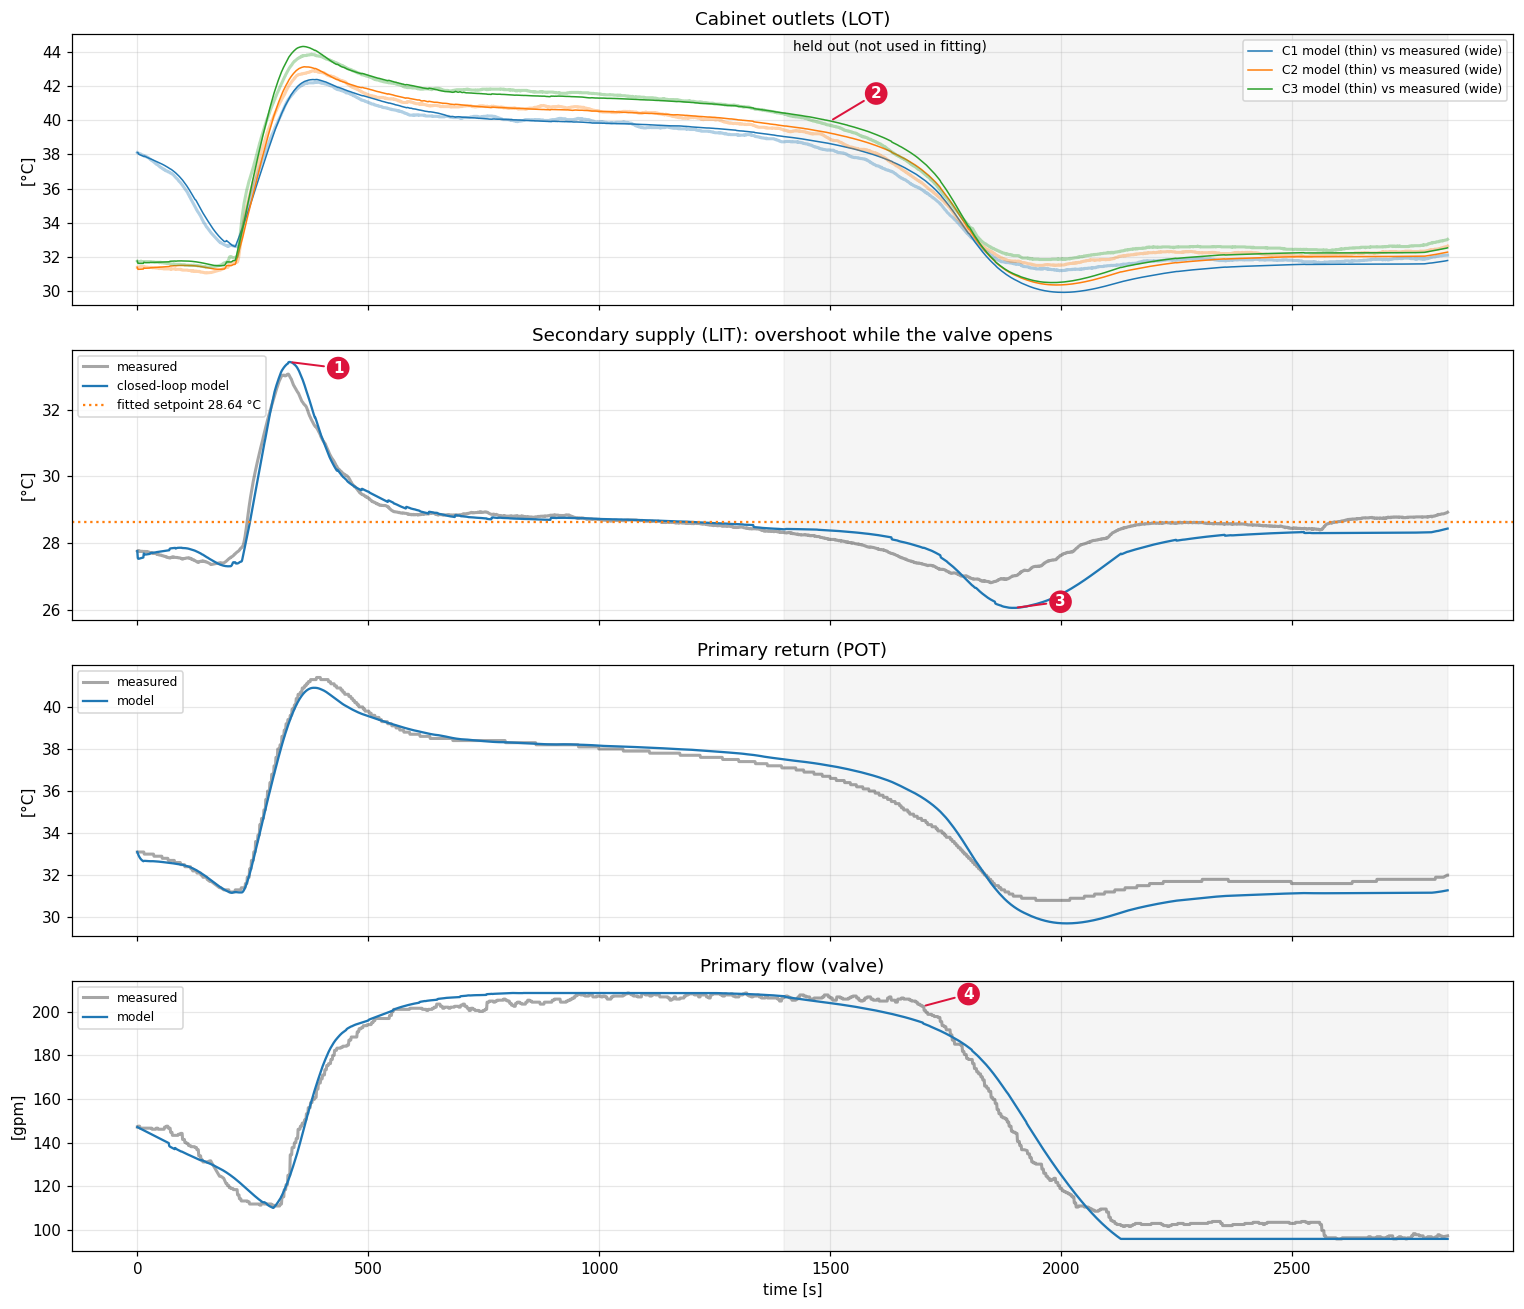

In [15]:
def fig_closed_loop():
    fig, ax = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
    for j in range(3):
        ax[0].plot(t_cg, LOT_m[j], color=CAB_C[j], lw=2, alpha=0.35)
        ax[0].plot(t_cg, LOT_hat[j], color=CAB_C[j], lw=1, label=f'C{CABS[j]} model (thin) vs measured (wide)')
    ax[0].set(ylabel='[°C]', title='Cabinet outlets (LOT)'); ax[0].legend(fontsize=8)
    ax[1].plot(t_cg, LIT, 'k', lw=2, alpha=0.35, label='measured'); ax[1].plot(t_cg, CL['LIT'], color=MAIN_C, label='closed-loop model')
    ax[1].axhline(CTL['T_set'], color=CMP_C, ls=':', label=f'fitted setpoint {CTL["T_set"]:.2f} °C')
    ax[1].set(ylabel='[°C]', title='Secondary supply (LIT): overshoot while the valve opens'); ax[1].legend(fontsize=8)
    ax[2].plot(t_cg, POT, 'k', lw=2, alpha=0.35, label='measured'); ax[2].plot(t_cg, CL['POT'], color=MAIN_C, label='model')
    ax[2].set(ylabel='[°C]', title='Primary return (POT)'); ax[2].legend(fontsize=8)
    ax[3].plot(t_cg, PLF, 'k', lw=2, alpha=0.35, label='measured'); ax[3].plot(t_cg, CL['PLF'], color=MAIN_C, label='model')
    ax[3].set(xlabel='time [s]', ylabel='[gpm]', title='Primary flow (valve)'); ax[3].legend(fontsize=8)
    for a in ax:
        a.axvspan(T_SPLIT, t_cg[-1], color='0.5', alpha=0.08)
    ax[0].annotate('held out (not used in fitting)', (T_SPLIT + 20, ax[0].get_ylim()[1] - 1), fontsize=9)
    i = int(np.searchsorted(t_cg, 1500)); mark(ax[0], 2, 1500, LOT_hat[2][i], dx=30, dy=18)
    i = np.argmax(CL['LIT']); mark(ax[1], 1, t_cg[i], CL['LIT'][i], dx=32, dy=-4)
    i = np.argmin(np.where(t_cg > 1500, CL['LIT'], np.inf)); mark(ax[1], 3, t_cg[i], CL['LIT'][i], dx=30, dy=4)
    i = int(np.searchsorted(t_cg, 1700)); mark(ax[3], 4, 1700, PLF[i], dx=30, dy=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part3_closed_loop.png', bbox_inches='tight')

fig_closed_loop()

**How to read this figure.** In each panel, the wide faded line is measured and the thin line is the model. The grey shaded area is the part the model never saw.

1. **The overshoot is reproduced** without any temperature measurement going in. The model peaks at 33.4 °C against the measured 33.1 °C.
2. **The cabinet outlets stay close in the unseen part**, within about 0.6–0.7 °C RMS.
3. **The largest miss.** In the unseen part the model's supply dips earlier and deeper than the real one (lowest about 26.1 °C vs. about 26.8 °C).
4. **The cause of that miss.** The real valve stays near full flow about 150 s longer than the model's. The real CDU logic, maybe with a different measured variable or a feed-forward term, isn't public.

**How good is it?** Typical errors are ~0.2 °C on the fitted window and 0.6–0.8 °C on the unseen ramp-down, with valve flow within 4–6 gpm. For a model with so few numbers, that's good.

**Do the fitted numbers make physical sense?** A model that fits but has absurd numbers is suspect. These are plausible against the literature:

* Secondary flow **≈ 27–30 kW/K per cabinet ≈ 100–115 gpm of water**, ~325 gpm for the CDU. Kumar et al. [3] give 250–300 gpm per CDU; a glycol mix would bring these together.
* Cabinet **time constant ≈ 1 minute** (66–78 s), similar to the ~1 min plant lag Shin et al. saw on Summit [6].
* Cabinet thermal mass ≈ 0.8–1.6 MJ/K: the ~83 L of coolant in a cabinet [4] is 0.35 MJ/K, so the rest is copper and blade hardware.

### Why the overshoot happens: two experiments on the fitted model

A fitted model lets us try things we couldn't try on the real machine. **These are what-ifs**, not measurements.

**Experiment 1: one cabinet's water, on its own.** Hold the inlet water fixed and step one cabinet from idle to full power. That isolates Piece 1.

**Experiment 2: a faster thermostat.** Replay the measured run with the same model, but make the controller's 68 s delay only 10 s. Nothing else changes.

Experiment 1: outlet rise 8.1 °C
Experiment 2 and variations (peak of supply water; seconds more than 1 °C above target):
  fitted                   peak  33.4 °C at t =   329 s;  221 s above target + 1 °C
  delay 40 s               peak  31.8 °C at t =   316 s;  270 s above target + 1 °C
  delay 10 s               peak  31.1 °C at t =   344 s;  292 s above target + 1 °C
  delay 0 s                peak  31.0 °C at t =   350 s;  294 s above target + 1 °C
  delay 10 s, gains x2     peak  30.3 °C at t =   328 s;  164 s above target + 1 °C
  fitted delay, gains x2   peak  33.8 °C at t =   309 s;  182 s above target + 1 °C
  fitted delay, gains x4   peak  38.6 °C at t =  1567 s;  375 s above target + 1 °C


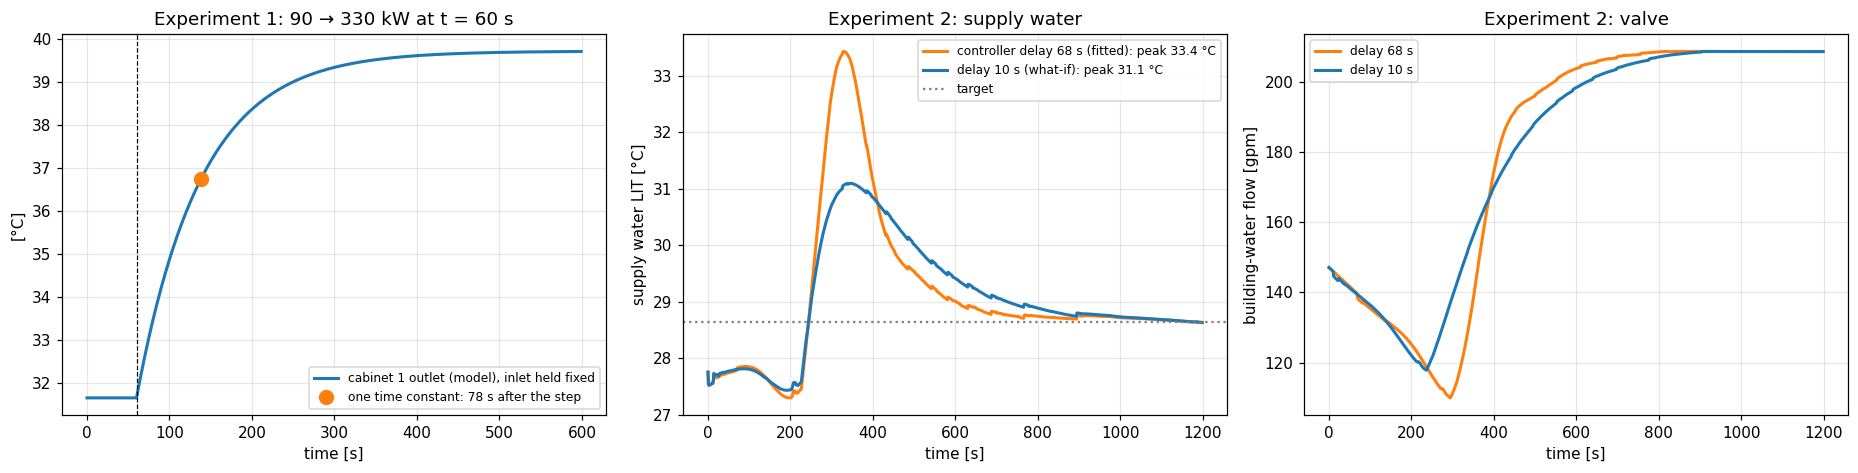

In [16]:
def fig_why_overshoot():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
    a = ax[0]; t = np.arange(600.0); p = CAB[0]
    ac_step = np.where(t < 60, 90e3, 330e3)
    out, _ = cabinet_outlet(ac_step, np.full_like(t, CTL['T_set']), p['Ch'], p['UA'], p['mcp'], 0.0)
    a.plot(t, out, color=MAIN_C, lw=2, label='cabinet 1 outlet (model), inlet held fixed')
    lvl = out[0] + (out[-1] - out[0]) * (1 - np.exp(-1))
    a.plot(60 + p['tau'], lvl, 'o', color=CMP_C, ms=9, label=f"one time constant: {p['tau']:.0f} s after the step")
    a.axvline(60, color='k', lw=0.8, ls='--')
    a.set(xlabel='time [s]', ylabel='[°C]', title='Experiment 1: 90 → 330 kW at t = 60 s'); a.legend(fontsize=8)
    fast = dict(CTL); fast['d_c'] = 10.0
    CLf = simulate_cooling_group(AC, PIT, ctl=fast, state=st0)
    sl = t_cg < 1200
    a = ax[1]
    a.plot(t_cg[sl], CL['LIT'][sl], color=CMP_C, lw=2, label=f"controller delay {CTL['d_c']:.0f} s (fitted): peak {CL['LIT'].max():.1f} °C")
    a.plot(t_cg[sl], CLf['LIT'][sl], color=MAIN_C, lw=2, label=f"delay 10 s (what-if): peak {CLf['LIT'].max():.1f} °C")
    a.axhline(CTL['T_set'], color='0.5', ls=':', label='target')
    a.set(xlabel='time [s]', ylabel='supply water LIT [°C]', title='Experiment 2: supply water'); a.legend(fontsize=8)
    a = ax[2]
    a.plot(t_cg[sl], CL['PLF'][sl], color=CMP_C, lw=2, label='delay 68 s'); a.plot(t_cg[sl], CLf['PLF'][sl], color=MAIN_C, lw=2, label='delay 10 s')
    a.set(xlabel='time [s]', ylabel='building-water flow [gpm]', title='Experiment 2: valve'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part3_why_overshoot.png', bbox_inches='tight')
    above = lambda x: ((x > CTL['T_set'] + 1) & (t_cg > 211) & (t_cg < 800)).sum()
    print(f"Experiment 1: outlet rise {out[-1]-out[0]:.1f} °C")
    print(f"Experiment 2 and variations (peak of supply water; seconds more than 1 °C above target):")
    for name, kw in [('fitted', {}), ('delay 40 s', dict(d_c=40.0)), ('delay 10 s', dict(d_c=10.0)), ('delay 0 s', dict(d_c=0.0)),
                     ('delay 10 s, gains x2', dict(d_c=10.0, Kp=2 * CTL['Kp'], Ki=2 * CTL['Ki'])), ('fitted delay, gains x2', dict(Kp=2 * CTL['Kp'], Ki=2 * CTL['Ki'])),
                     ('fitted delay, gains x4', dict(Kp=4 * CTL['Kp'], Ki=4 * CTL['Ki']))]:
        o = simulate_cooling_group(AC, PIT, ctl={**CTL, **kw}, state=st0)
        print(f"  {name:24s} peak {o['LIT'].max():5.1f} °C at t = {t_cg[o['LIT'].argmax()]:5.0f} s; {above(o['LIT']):4d} s above target + 1 °C")

fig_why_overshoot()

**How to read this figure.**

* **Left (Experiment 1):** with the inlet held fixed, stepping one cabinet from 90 to 330 kW raises its outlet by 8.1 °C (240 kW ÷ 29.8 kW/°C, Idea 1). The orange dot marks one time constant, 78 s. So the warm water is on its way within about a minute.
* **Middle (Experiment 2):** the supply water with the fitted 68 s delay (orange) and a 10 s delay (blue). The peak falls from 33.4 °C to 31.1 °C, so the overshoot goes from about 4.8 °C to about 2.5 °C.
* **Right:** the valve. With less delay it starts earlier, but it then climbs more gently, because it's seeing a smaller error.

**What this says, including what it doesn't.**

* **The delay explains about half of the peak, not all of it.** Even zero delay leaves a peak of 31.0 °C. The rest is the speed of the heat compared with the controller's gains.
* **Removing delay alone doesn't shorten the disturbance.** The time spent more than 1 °C above target goes *up*, from 221 s to 292 s, because the gentler valve takes longer to catch up. It's a lower, longer bump.
* **Stronger gains can help, up to a point.** With a 10 s delay and doubled gains, the peak is 30.3 °C and the time above is 164 s. With the fitted delay, 4× gains make the loop unstable: the peak reaches 38.6 °C, and it comes late in the run rather than at the job's start. That's Idea 5's warning.

These are what-ifs on a simplified controller that doesn't match the real valve in every detail, so treat the direction as more reliable than the exact numbers.

In [17]:
# Save the fitted numbers so other code can use them, and show them as a table.
params = dict(cabinets=[{k: float(v) for k, v in p.items()} for p in CAB],
              cdu={k: float(v) for k, v in CDU.items()},
              controller={k: (list(map(float, v)) if isinstance(v, tuple) else float(v)) for k, v in CTL.items()},
              ac_from_node_sum_poly=list(map(float, AC_POLY)), ac_from_node_sum_range_W=list(map(float, RF_RANGE)))
(OUT / 'cooling_group_params.json').write_text(json.dumps(params, indent=2))
pd.DataFrame([{'cabinet': CABS[j], 'C_h_MJ_per_K': p['Ch'] / 1e6, 'UA_kW_per_K': p['UA'] / 1e3, 'mcp_kW_per_K': p['mcp'] / 1e3,
               'flow_gpm_water': p['mcp'] / GPM_WK, 'delay_s': p['d'], 'tau_s': p['tau'], 'LOT_offset_K': p['b']} for j, p in enumerate(CAB)]).round(3)

,cabinet,C_h_MJ_per_K,UA_kW_per_K,mcp_kW_per_K,flow_gpm_water,delay_s,tau_s,LOT_offset_K
0,1,1.618,35.223,29.758,113.067,2.386,78.368,0.270
1,2,1.083,20.266,28.873,109.704,0.000,74.344,0.625
2,3,0.763,15.145,26.951,102.400,0.000,65.870,0.621


## Part 4: A model of the GPU chip

**The question.** Given a GPU's power over time and the temperature of its water, how hot is the chip at each instant, and how much heat is flowing through each layer around it?

**The data.** A separate recording of one computer running HPL (82 s, read through Ampere, as in `liquid_bl_rochpl.ipynb`). For each of its 4 GPU packages it has power (updated about every 3.3 ms) and the **chip's own temperature sensor** (about every 6.5 ms, in 1 °C steps). So here we have the real chip temperature to compare with. We don't have the water temperature for this run, so the fit estimates it.

**What goes in and out.** In: a package's power and the water temperature. Out: the chip's temperature and three heat flows.

### The analogy: three buckets in a row

Think of heat as water flowing through three buckets joined by narrow pipes, with the last pipe draining into a lake.

```
power ─► [ bucket 1: the die ] ─pipe R1─► [ bucket 2: package ] ─pipe R2─► [ bucket 3: cold plate ] ─pipe R3─► water
          small: fills in ms                 medium: ~1.5 s                   large: ~15 s
```

Bucket size is thermal mass. Water level is temperature. Pipe narrowness is thermal resistance. Pour in a sudden burst and the small first bucket rises at once, then drains into the next ones. By the time the burst reaches the lake it has spread out into a slow trickle. **That is why the water never sees fast spikes.**

Engineers call this a **Cauer ladder**, a standard kind of compact chip thermal model [10]. Which physical layer each bucket stands for is our interpretation. The fit only knows three buckets.

### The equations

One line per bucket, each saying the same thing: **how fast this bucket warms = heat flowing in − heat flowing out.**

$$C_1\dot T_1 = P - \frac{T_1 - T_2}{R_1},\quad C_2\dot T_2 = \frac{T_1 - T_2}{R_1} - \frac{T_2 - T_3}{R_2},\quad C_3\dot T_3 = \frac{T_2 - T_3}{R_2} - \frac{T_3 - T_c}{R_3}$$

| Symbol | Meaning | How we get it |
|---|---|---|
| $P$ | the package's power, all turned into heat in bucket 1 | measured |
| $T_1$ | temperature of bucket 1. This is the **junction** temperature | computed |
| $T_2$, $T_3$ | temperatures of buckets 2 and 3 | computed |
| $T_c$ | temperature of the water | fitted here; from Part 3 later |
| $C_1, C_2, C_3$ | thermal masses (bucket sizes), J/K | fitted |
| $R_1, R_2, R_3$ | thermal resistances (pipe narrowness), K/W | fitted |
| $\dot T$ | how fast that temperature is changing | computed |
| $(T_1 - T_2)/R_1$ | heat flowing from bucket 1 to bucket 2 (Idea 2 rearranged), W | computed |

### The three heat fluxes

"Heat flux" could mean three different things here. Each is power ÷ $A$, the 14.5 cm² die area, so they can be compared directly.

| Name | Formula | In words |
|---|---|---|
| $q''_{gen}$ | $P/A$ | the heat being **made** in the chip |
| $q''_{die}$ | $(T_1-T_2)/(R_1 A)$ | the heat **leaving the die** |
| $q''_{wall}$ | $(T_3 - T_c)/(R_3 A)$ | the heat **entering the water** |

In steady state all three are equal, since what goes in must come out. They differ only while a bucket is filling or draining.

**What the next two cells do.** The first loads the recording. The second defines the model and fits it to each of the 4 packages. The solver in `junction_response` is exact for each time step, and fast enough for 47 minutes at 1 ms steps.

In [18]:
configs = {
    re.compile(r".*rocm_smi.*energy.*"): MetricConfig(MetricType.CUMULATIVE, scale_factor=1e-6),       # uJ -> J
    re.compile(r".*rocm_smi.*power.*"):  MetricConfig(MetricType.INSTANTANEOUS, scale_factor=1e-6),    # uW -> W
    re.compile(r".*rocm_smi.*temp.*"):   MetricConfig(MetricType.INSTANTANEOUS, scale_factor=1e-3),    # m°C -> °C
    re.compile(r".*craypm.*power$"):     MetricConfig(MetricType.INSTANTANEOUS),                       # W
}
ensemble = Ensemble.from_trace_paths([str(TRACE)], {"Node0": ["MPI Rank 0"]}, configs)
node = ensemble.runs[0].nodes[0]
rank0 = node.ranks[0]
arr = lambda m: (np.asarray(m.times.to_ndarray(), float), np.asarray(m.values.to_ndarray(), float))

names = np.asarray(rank0.names.to_ndarray()).astype(str)
i_ges = np.flatnonzero(np.char.startswith(names, 'HPL_pdgesv'))[0]
T_GESV0, T_GESV1 = np.asarray(rank0.starts.to_ndarray())[i_ges], np.asarray(rank0.ends.to_ndarray())[i_ges]

# Per-package power on a 1 ms grid (each cell takes the dE/dt of the counter interval it falls in)
E = {d: arr(node.metrics[f"A2rocm_smi:::energy_count:device={d}"]) for d in OAM_DEVICES}
T0_N = max(E[d][0][0] for d in OAM_DEVICES); T1_N = min(E[d][0][-1] for d in OAM_DEVICES)
t_n = np.arange(T0_N, T1_N, DT_GPU)
def on_grid(t_e, e_j, g):
    p = np.diff(e_j) / np.diff(t_e)
    return p[np.clip(np.searchsorted(t_e, g, side='right') - 1, 0, len(p) - 1)]
P_OAM = np.array([on_grid(*E[d], t_n) for d in OAM_DEVICES])               # W, (4, n)
TJ = {d: arr(node.metrics[f"A2rocm_smi:::temp_current:device={d}:sensor=1"]) for d in OAM_DEVICES}
print(f"node trace: {t_n[-1]-t_n[0]:.1f} s at {DT_GPU*1e3:.0f} ms; HPL_pdgesv {T_GESV0-T0_N:.1f}-{T_GESV1-T0_N:.1f} s; "
      f"package power idle {P_OAM[:, (t_n - T0_N) < 10].mean():.0f} W, HPL {P_OAM[:, (t_n > T_GESV0 + 5) & (t_n < T_GESV1 - 5)].mean():.0f} W")

Loading Runs:   0%|          | 0/1 [00:00<?, ?it/s]

Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.13s/it]

Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.13s/it]

node trace: 82.2 s at 1 ms; HPL_pdgesv 18.5-81.2 s; package power idle 94 W, HPL 552 W


In [19]:
def cauer_matrices(R, C):
    '''State-space form x' = A x + B [P, T_c] of the Cauer ladder: R[i] joins node i to i+1 (the last one to the coolant).'''
    n = len(R); A = np.zeros((n, n))
    for i in range(n):
        A[i, i] = -1 / (R[i] * C[i]) - (1 / (R[i - 1] * C[i]) if i else 0)
        if i: A[i, i - 1] = 1 / (R[i - 1] * C[i])
        if i < n - 1: A[i, i + 1] = 1 / (R[i] * C[i])
    B = np.zeros((n, 2)); B[0, 0] = 1 / C[0]; B[-1, 1] = 1 / (R[-1] * C[-1])
    return A, B

def junction_response(P, Tc, R, C, dt=DT_GPU, area_cm2=A_DIE_CM2):
    '''Junction temperature and layer heat fluxes for a package power trace P [W] and coolant temperature Tc [°C].

    P, Tc: arrays on a uniform dt grid (Tc may be a scalar). Starts in steady state at the mean input of the first second.
    Exact for inputs held constant over each step: the ladder is diagonalised and each eigenmode is a first-order IIR filter.
    Returns dict: T (n_nodes, N) node temperatures (T[0] = junction), q_gen, q_die, q_wall [W/cm^2 of die area].
    '''
    P = np.asarray(P, float); Tc = np.broadcast_to(np.asarray(Tc, float), P.shape)
    A, B = cauer_matrices(R, C)
    lam, V = np.linalg.eig(A); lam, V = lam.real, V.real; W = np.linalg.inv(V)
    u = np.stack([P, Tc])
    u0 = u[:, :max(1, int(round(1.0 / dt)))].mean(1, keepdims=True)
    x0 = -np.linalg.solve(A, B @ u0[:, 0])
    drive = W @ B @ (u - u0)                           # modal inputs, (n_nodes, N)
    z = np.empty_like(drive)
    for i, l in enumerate(lam):
        a = np.exp(l * dt)
        z[i] = lfilter([0, (a - 1) / l], [1, -a], drive[i])
    T = x0[:, None] + V @ z
    return dict(T=T, q_gen=P / area_cm2, q_die=(T[0] - T[1]) / R[0] / area_cm2, q_wall=(T[-1] - Tc) / R[-1] / area_cm2)

JNET = []
for k, d in enumerate(OAM_DEVICES):
    tt, TT = TJ[d]; m = (tt > t_n[0]) & (tt < t_n[-1])
    def res(q, k=k):
        out = junction_response(P_OAM[k], q[6], np.exp(q[:3]), np.exp(q[3:6]))
        return np.interp(tt[m], t_n, out['T'][0]) - TT[m]
    q0 = np.r_[np.log([0.015, 0.02, 0.015]), np.log([1.5, 60, 1000]), 33]
    s = least_squares(res, q0, bounds=(np.r_[np.log([1e-4] * 3), np.log([0.05] * 3), 0], np.r_[np.log([0.2] * 3), np.log([1e5] * 3), 60]))
    R, C = np.exp(s.x[:3]), np.exp(s.x[3:6])
    JNET.append(dict(device=d, R=R, C=C, Tc=s.x[6], rms=rms(s.fun)))
    print(f"package {k} (device {d}): R = {np.round(R, 4)} K/W (total {R.sum():.4f}), C = {np.round(C, 1)} J/K, "
          f"tau = {np.round(R * C, 3)} s, fitted coolant {s.x[6]:.1f} °C, RMS {rms(s.fun):.2f} K")

c_si = 1.63e6 * A_DIE_CM2 * 1e-4 * 0.5e-3          # J/K for 0.5 mm of silicon over the die area
print(f"check: 0.5 mm of silicon over {A_DIE_CM2:.1f} cm^2 holds {c_si:.2f} J/K (compare C_1)")

package 0 (device 0): R = [0.0155 0.0243 0.0155] K/W (total 0.0553), C = [   2.   75. 1107.] J/K, tau = [ 0.031  1.82  17.137] s, fitted coolant 34.4 °C, RMS 0.74 K


package 1 (device 2): R = [0.0169 0.018  0.0092] K/W (total 0.0440), C = [   1.9   70.2 1543.4] J/K, tau = [ 0.032  1.261 14.148] s, fitted coolant 35.1 °C, RMS 0.73 K


package 2 (device 4): R = [0.0127 0.0241 0.0173] K/W (total 0.0540), C = [  1.4  52.9 806.8] J/K, tau = [ 0.018  1.275 13.923] s, fitted coolant 31.1 °C, RMS 0.79 K


package 3 (device 6): R = [0.0151 0.0194 0.0072] K/W (total 0.0417), C = [2.1000e+00 6.2100e+01 2.1756e+03] J/K, tau = [ 0.032  1.207 15.565] s, fitted coolant 30.1 °C, RMS 0.79 K
check: 0.5 mm of silicon over 14.5 cm^2 holds 1.18 J/K (compare C_1)


,package,device,R1_K_per_W,R2_K_per_W,R3_K_per_W,C1_J_per_K,C2_J_per_K,C3_J_per_K,tau1_s,tau2_s,tau3_s,R_total_K_per_W,Tc_fit_C,rms_K
0,0,0,0.0155,0.0243,0.0155,1.9849,75.0435,1106.9688,0.0308,1.8200,17.1374,0.0553,34.4091,0.7394
1,1,2,0.0169,0.0180,0.0092,1.8781,70.2026,1543.4361,0.0317,1.2608,14.1476,0.0440,35.1387,0.7265
2,2,4,0.0127,0.0241,0.0173,1.4004,52.8552,806.8471,0.0177,1.2750,13.9230,0.0540,31.1048,0.7866
3,3,6,0.0151,0.0194,0.0072,2.1377,62.1033,2175.6013,0.0323,1.2074,15.5645,0.0417,30.0991,0.7878


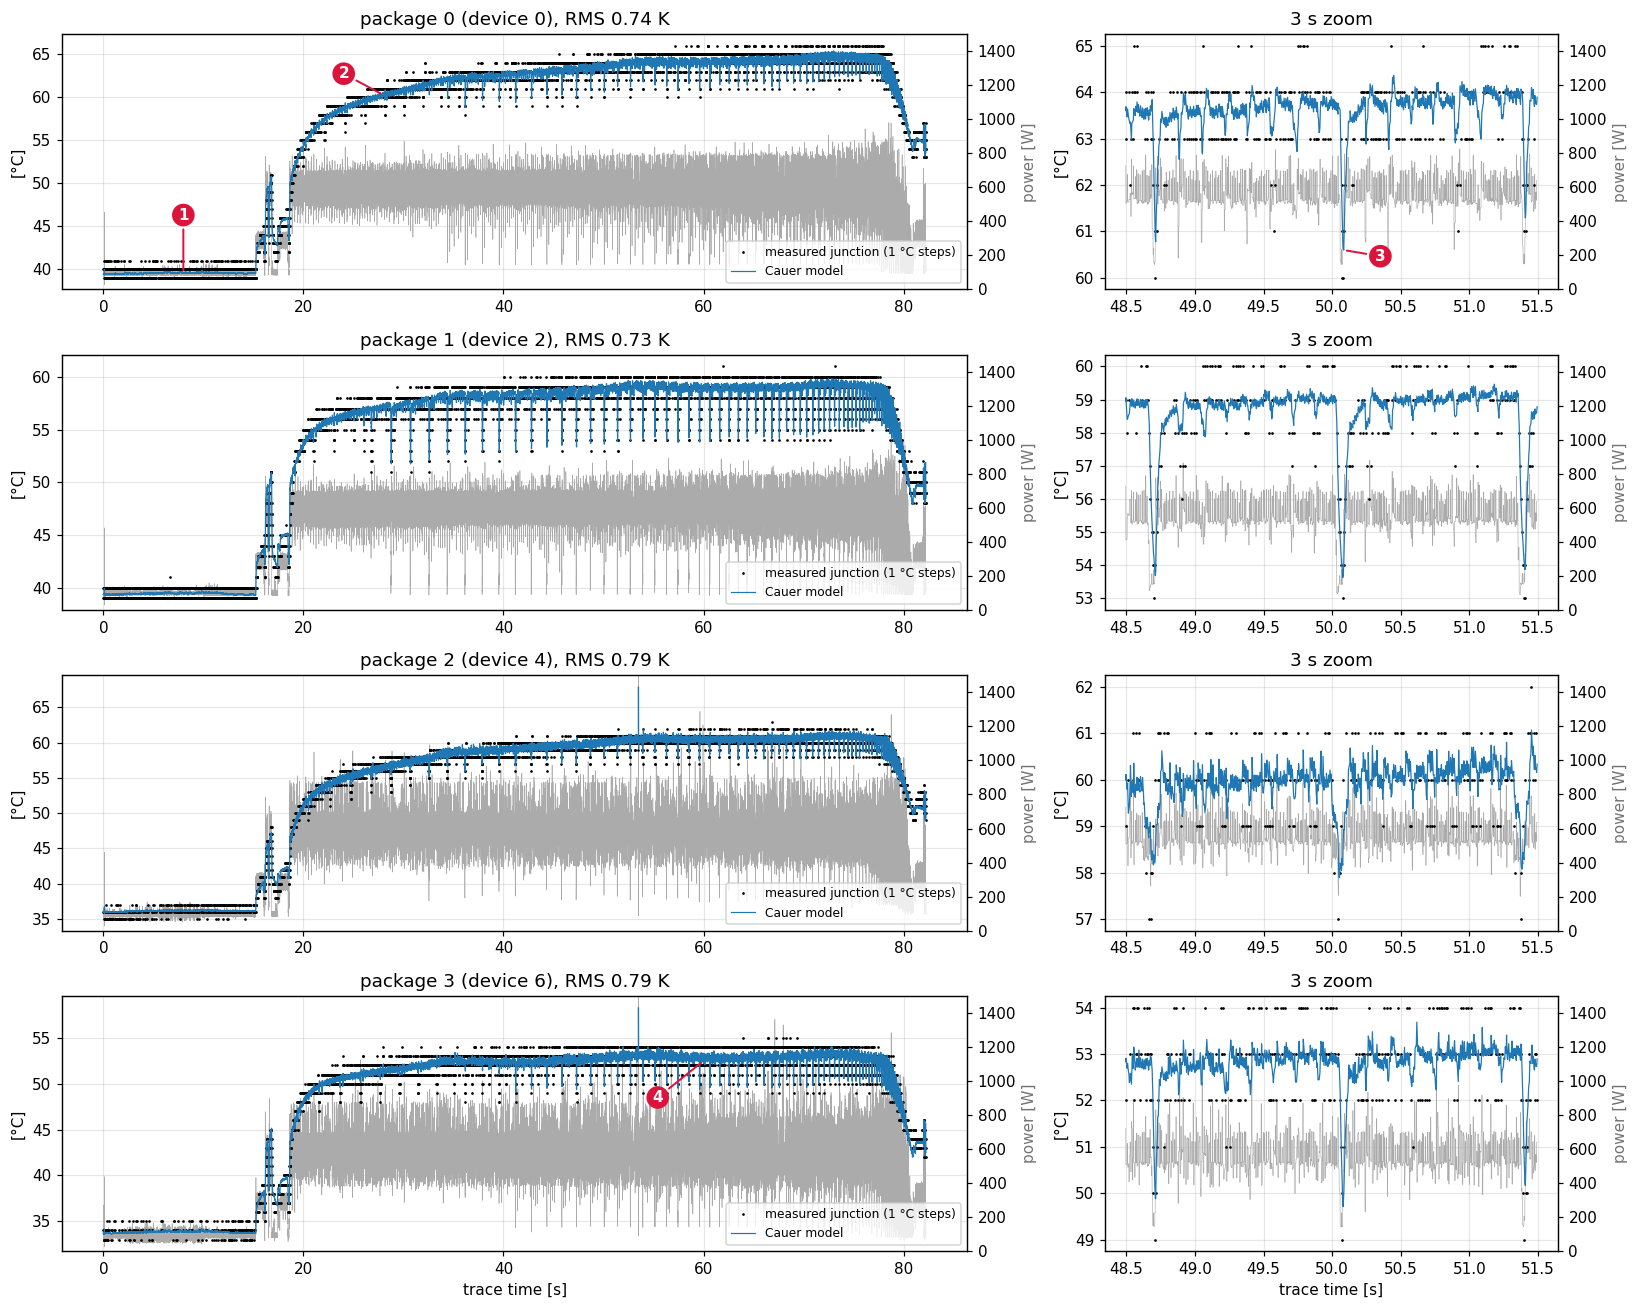

In [20]:
def fig_junction_fit():
    fig, ax = plt.subplots(4, 2, figsize=(15, 12), gridspec_kw=dict(width_ratios=[2, 1]))
    zs = T_GESV0 + 30.0
    for k, jn in enumerate(JNET):
        out = junction_response(P_OAM[k], jn['Tc'], jn['R'], jn['C'])
        tt, TT = TJ[jn['device']]
        for a, (lo, hi) in zip(ax[k], [(t_n[0], t_n[-1]), (zs, zs + 3)]):
            m = (tt >= lo) & (tt < hi); mg = (t_n >= lo) & (t_n < hi)
            a.plot(tt[m] - T0_N, TT[m], '.', color='k', ms=1.5, label='measured junction (1 °C steps)')
            a.plot(t_n[mg] - T0_N, out['T'][0][mg], color=MAIN_C, lw=0.8, label='Cauer model')
            a2 = a.twinx(); a2.plot(t_n[mg] - T0_N, P_OAM[k][mg], color=POWER_C, lw=0.4, alpha=0.6); a2.set_ylabel('power [W]', color=POWER_C)
            a2.grid(False); a2.set_ylim(0, 1500)
            a.set(ylabel='[°C]', title=f'package {k} (device {jn["device"]}), RMS {jn["rms"]:.2f} K' if lo == t_n[0] else '3 s zoom')
            a.set_zorder(a2.get_zorder() + 1); a.patch.set_visible(False)      # keep the numbered circles above the power line
        ax[k, 0].legend(loc='lower right', fontsize=8)
    ax[-1, 0].set_xlabel('trace time [s]'); ax[-1, 1].set_xlabel('trace time [s]')
    t_rel = t_n - T0_N; o0 = junction_response(P_OAM[0], JNET[0]['Tc'], JNET[0]['R'], JNET[0]['C'])['T'][0]
    at = lambda s: o0[int(np.searchsorted(t_rel, s))]
    mark(ax[0, 0], 1, 8, at(8), dx=0, dy=38)
    mark(ax[0, 0], 2, 28, at(28), dx=-26, dy=14)
    zm = (t_n >= zs) & (t_n < zs + 3); iz = np.flatnonzero(zm)[np.argmin(o0[zm])]
    mark(ax[0, 1], 3, t_rel[iz], o0[iz], dx=24, dy=-4)
    o3 = junction_response(P_OAM[3], JNET[3]['Tc'], JNET[3]['R'], JNET[3]['C'])['T'][0]
    i3 = int(np.searchsorted(t_rel, 60)); mark(ax[3, 0], 4, 60, o3[i3], dx=-30, dy=-24)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part4_junction_fit.png', bbox_inches='tight')

fig_junction_fit()
pd.DataFrame([{'package': k, 'device': j['device'], **{f'R{i+1}_K_per_W': j['R'][i] for i in range(3)},
               **{f'C{i+1}_J_per_K': j['C'][i] for i in range(3)}, **{f'tau{i+1}_s': j['R'][i] * j['C'][i] for i in range(3)},
               'R_total_K_per_W': j['R'].sum(), 'Tc_fit_C': j['Tc'], 'rms_K': j['rms']} for k, j in enumerate(JNET)]).round(4) \
  .to_csv(OUT / 'gpu_junction_params.csv', index=False)
pd.read_csv(OUT / 'gpu_junction_params.csv')

**How to read this figure.** One row per GPU package. Left: the whole 82 s run. Right: a 3 s zoom. Black dots are the chip's own sensor, sitting in horizontal bands because it reads whole degrees. The blue line is the model. Grey is the power, on the right-hand axis.

1. **Idle.** At about 90 W the chip sits near 40 °C.
2. **HPL starts and the chip warms in stages:** a quick jump, then a slow climb lasting tens of seconds. The slow climb is the big bucket 3 filling.
3. **Fast dips in the zoom.** When HPL pauses briefly, the power drops and the chip cools by a few degrees within tens of milliseconds, then recovers. Bucket 1 is small enough to follow that, and the model tracks it.
4. **Packages differ.** Package 3 plateaus near 53 °C and package 0 near 64 °C, under the same power. That's partly different resistance and partly warmer water, see below.

**What the fit says** (table above; each row is one package).

* The model follows the measured junction to ~0.75 K RMS. The sensor's 1 °C steps alone account for ~0.3 K of that. It also follows the fast dips (the ~5 °C drops when HPL stalls for ~50 ms between panels).
* Three time scales: **18–32 ms** (the die: $C_1$ ≈ 1.4–2.1 J/K, close to the 1.2 J/K of 0.5 mm of silicon, a physical check the fit didn't know about), **1.2–1.8 s** (package/cold-plate base), **14–17 s** (cold plate and the coolant in it).
* Total junction-to-coolant resistance **0.042–0.055 K/W per package**, in line with the 0.034–0.044 K/W reported for comparable liquid-cooled GPU cold plates.
* The four packages sit at different fitted coolant temperatures (~30–35 °C). HPE/LRZ [9] report that coolant flows **serially** across a blade, so downstream GPUs see warmer coolant. The offsets are carried into Part 6 as *coolant offset relative to the cabinet supply*. That assumes the node run was at the same supply setpoint as the cooling group (the node trace has no coolant telemetry).

### Watching the buckets: one burst and one long step

Now use the fitted model for package 0 with a simple made-up power signal, to see the three fluxes separate. The GPU sits at 300 W, gets a brief 0.2 s burst of an extra 260 W at t = 2 s, then an extra 260 W that stays on from t = 10 s.

burst: junction +4.5 °C; peak flux made 38.7, leaving die 38.2, entering water 20.87 W/cm^2 (base 20.7)
step: junction +14.3 °C at the end; flux entering the water reaches halfway 14.5 s after the step


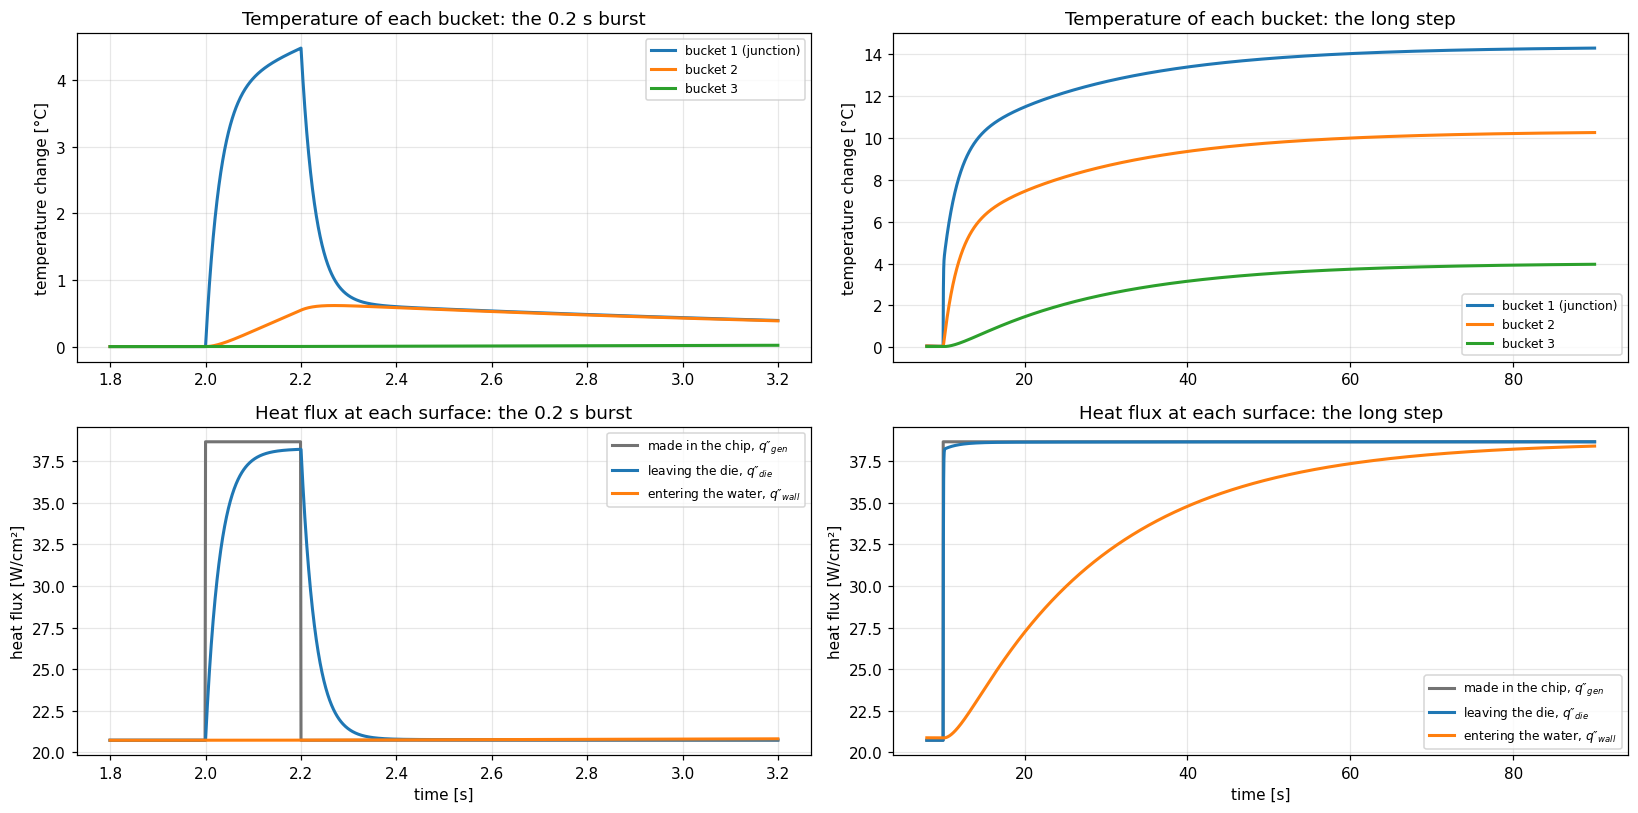

In [21]:
def fig_ladder_demo():
    jn = JNET[0]; t = np.arange(0, 90, DT_GPU)
    P = np.full_like(t, 300.0)
    P[(t >= 2) & (t < 2.2)] += 260; P[t >= 10] += 260
    o = junction_response(P, jn['Tc'], jn['R'], jn['C'])
    fig, ax = plt.subplots(2, 2, figsize=(15, 7.5))
    for col, (lo, hi, name) in enumerate([(1.8, 3.2, 'the 0.2 s burst'), (8, 90, 'the long step')]):
        m = (t >= lo) & (t < hi)
        a = ax[0, col]
        for i, (c, lab) in enumerate(zip([MAIN_C, CMP_C, THIRD_C], ['bucket 1 (junction)', 'bucket 2', 'bucket 3'])):
            a.plot(t[m], o['T'][i][m] - o['T'][i][0], color=c, lw=2, label=lab)
        a.set(ylabel='temperature change [°C]', title=f'Temperature of each bucket: {name}'); a.legend(fontsize=8)
        a = ax[1, col]
        a.plot(t[m], o['q_gen'][m], color=POWER_C, lw=2, label='made in the chip, $q″_{gen}$')
        a.plot(t[m], o['q_die'][m], color=MAIN_C, lw=2, label='leaving the die, $q″_{die}$')
        a.plot(t[m], o['q_wall'][m], color=CMP_C, lw=2, label='entering the water, $q″_{wall}$')
        a.set(xlabel='time [s]', ylabel='heat flux [W/cm²]', title=f'Heat flux at each surface: {name}'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part4_ladder_demo.png', bbox_inches='tight')
    b = (t >= 1.8) & (t < 3.2); w = (t >= 2) & (t < 10)
    print(f"burst: junction +{(o['T'][0][b] - o['T'][0][0]).max():.1f} °C; peak flux made {o['q_gen'][b].max():.1f}, leaving die {o['q_die'][b].max():.1f}, "
          f"entering water {o['q_wall'][w].max():.2f} W/cm^2 (base {o['q_gen'][0]:.1f})")
    h = o['q_gen'][-1]; base = o['q_gen'][0]; half = base + 0.5 * (h - base)
    print(f"step: junction +{o['T'][0][-1] - o['T'][0][0]:.1f} °C at the end; flux entering the water reaches halfway {t[(t > 10) & (o['q_wall'] >= half)][0] - 10:.1f} s after the step")

fig_ladder_demo()

**How to read this figure.** Top row: how much each bucket has warmed. Bottom row: the three heat fluxes. Left column: the 0.2 s burst, zoomed in. Right column: the long step.

* **The burst, top left.** The junction (blue) jumps 4.5 °C within 0.2 s, then falls back within about 0.2 s more. Bucket 2 barely moves, and bucket 3 not at all.
* **The burst, bottom left.** Heat being made (grey) jumps from 20.7 to 38.7 W/cm². Heat leaving the die (blue) follows, a little behind, reaching 38.2. **Heat entering the water (orange) stays flat**, rising from 20.7 to only about 20.9 W/cm². The burst's energy is parked in bucket 2 and released slowly.
* **The step, top right.** Each bucket rises at its own pace, ending with the junction 14.3 °C up (260 W × 0.0553 K/W, Idea 2).
* **The step, bottom right.** All three fluxes end up equal, as they must in steady state. But heat entering the water takes 14.5 s to get halfway. During that time the difference between the curves is warming the buckets.

### How much of each rhythm gets through

Idea 4 said a filter passes slow swings and blocks fast ones. The next figure measures this for the fitted chip model. Take a power swing with a repeating rhythm of some **period** (the time for one full cycle), and ask how much of it gets through.

Periods to keep in mind: 12 ms is HPL's fast rhythm, 1 s is how often the cabinet sensors report, and 60 s is the rough cabinet time constant.

package 0, period 12 ms / 1 s / 60 s:
  |dTj/dP| = 0.0010, 0.0152, 0.0412 K/W
  q_die/q_gen = 0.062, 0.957, 0.998
  q_wall/q_gen = 0.000, 0.001, 0.452


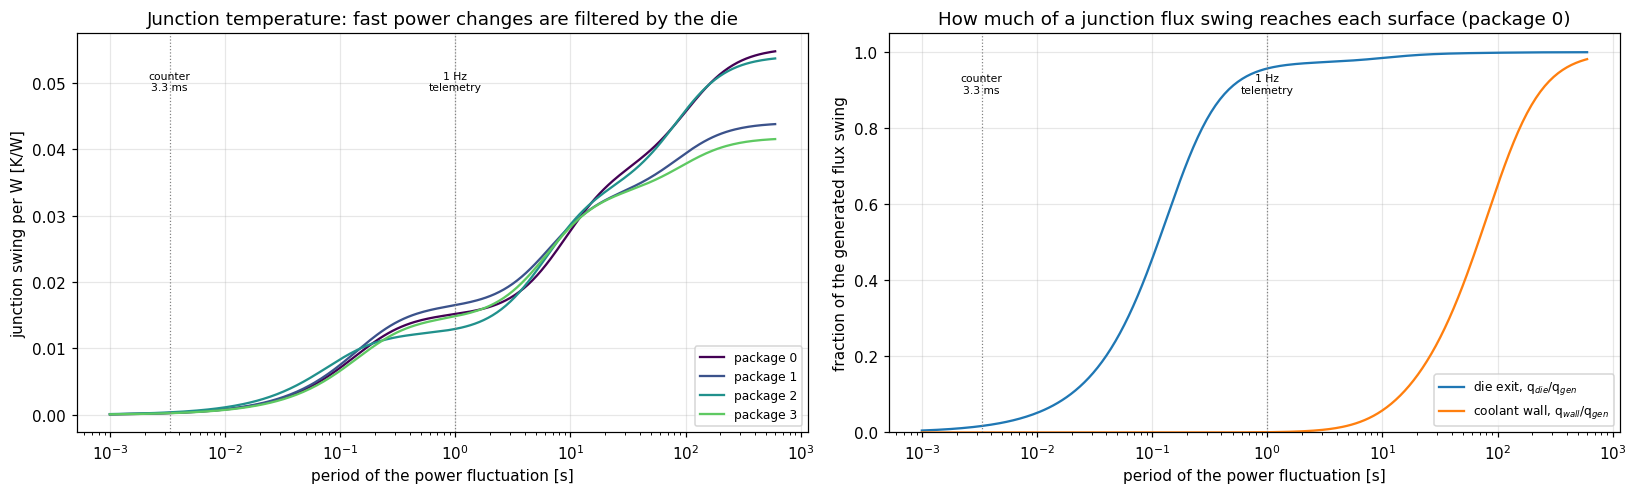

In [22]:
def junction_freq(jn, periods):
    '''Complex gains vs period for package network jn: dTj/dP [K/W], q_die/q_gen and q_wall/q_gen (dimensionless).'''
    A, B = cauer_matrices(jn['R'], jn['C']); n = A.shape[0]
    g = np.array([np.linalg.solve(2j * np.pi / T * np.eye(n) - A, B[:, 0]) for T in periods])     # dT/dP per node
    return g[:, 0], (1 - (2j * np.pi / periods) * jn['C'][0] * g[:, 0]), g[:, -1] / jn['R'][-1]

def fig_junction_freq():
    periods = np.geomspace(1e-3, 600, 300)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    for k, jn in enumerate(JNET):
        gT, gd, gw = junction_freq(jn, periods)
        ax[0].plot(periods, np.abs(gT), color=plt.cm.viridis(k / 4), label=f'package {k}')
        if k == 0:
            ax[1].plot(periods, np.abs(gd), color=MAIN_C, label='die exit, q$_{die}$/q$_{gen}$')
            ax[1].plot(periods, np.abs(gw), color=CMP_C, label='coolant wall, q$_{wall}$/q$_{gen}$')
    ax[0].set(xscale='log', xlabel='period of the power fluctuation [s]', ylabel='junction swing per W [K/W]',
              title='Junction temperature: fast power changes are filtered by the die'); ax[0].legend(fontsize=8)
    ax[1].set(xscale='log', ylim=(0, 1.05), xlabel='period of the power fluctuation [s]', ylabel='fraction of the generated flux swing',
              title='How much of a junction flux swing reaches each surface (package 0)'); ax[1].legend(fontsize=8)
    for a in ax:
        for T, lab in [(3.3e-3, 'counter\n3.3 ms'), (1.0, '1 Hz\ntelemetry')]:
            a.axvline(T, color='0.5', ls=':', lw=0.8); a.annotate(lab, (T, a.get_ylim()[1] * 0.85), fontsize=7, ha='center')
    fig.tight_layout(); fig.savefig(FIG / 'cg_part4_junction_freq.png', bbox_inches='tight')
    gT, gd, gw = junction_freq(JNET[0], np.array([0.012, 1.0, 60.0]))
    print("package 0, period 12 ms / 1 s / 60 s:\n  |dTj/dP| = " + ', '.join(f'{v:.4f}' for v in np.abs(gT)) + " K/W\n"
          "  q_die/q_gen = " + ', '.join(f'{v:.3f}' for v in np.abs(gd)) + "\n  q_wall/q_gen = " + ', '.join(f'{v:.3f}' for v in np.abs(gw)))

fig_junction_freq()

**How to read these plots.** Horizontal is the period of the swing, with fast ones on the left and slow ones on the right. Each tick mark is 10 times the last. The dotted lines mark the power counter's update time (3.3 ms) and the cabinet sensors' 1 s.

* **Left:** slow power changes (≳ 3 min) move the junction by the full $R_{tot}$ ≈ 0.04–0.055 K/W. A 1 min change gets ~75 % of that, a 1 s change ~30 % (the die and package respond on their own), and the ~12 ms HPL rhythm only ~2 %.
* **Right:** this is the link to `liquid_bl_rochpl.ipynb`, which fed the raw GPU power into the boundary layer as wall heat flux. The die exit passes everything slower than ~1 s but only a few percent of the 12 ms rhythm. **The coolant wall sees nothing faster than ~5 s, and only ~45 % of a 1-minute swing.** So when the boundary-layer model is applied to a cold-plate wall, it should be driven by $q''_{wall}$, not $P/A$.

## Part 5: From one computer to a whole cabinet

**The question.** We recorded one computer in detail, but the cooling system sees 128 at once. If all 128 ran that same recording, what would the cabinet's power look like?

**The analogy.** A crowd walking across a bridge. If everyone steps at random, the footsteps average out. If everyone marches in step, the bridge feels every step at full force. Whether fast power swings add up or cancel depends on how well the computers are in step.

**What goes in and out.** In: one computer's power over time, and a choice of how far out of step the copies are. Out: the cabinet's total, to compare with what the real cabinets did.

**First step: GPU power to whole-computer power.** The computer also has a CPU, memory, network cards and so on. A sensor called craypm reports whole-computer power about 10 times a second, so we fit a straight line from GPU power to computer power. Then any GPU trace gives a computer's total. The next cell does that, and its printout reads: `node = slope × sum(package) + constant`.

In [23]:
tcp, pnode = arr(node.metrics['A2coretemp:::craypm:power'])
m = (tcp > t_n[0] + 0.2) & (tcp < t_n[-1] - 0.2)
# craypm samples are ~100 ms averages: compare with the package sum averaged over the preceding 100 ms
psum = np.array([P_OAM.sum(0)[(t_n > tc - 0.1) & (t_n <= tc)].mean() for tc in tcp[m]])
NODE_FIT = np.polyfit(psum, pnode[m], 1)
node_from_packages = lambda p_sum: np.polyval(NODE_FIT, p_sum)
print(f"node = {NODE_FIT[0]:.3f} * sum(package) + {NODE_FIT[1]:.0f} W   (RMS {rms(pnode[m] - node_from_packages(psum)):.0f} W);  "
      f"idle {pnode[m][psum < 500].mean():.0f} W, HPL {pnode[m][psum > 2000].mean():.0f} W per node")
print(f"cooling-group nodes (Redfish): idle {RF[:, t_cg > 2200].mean()/N_NODES:.0f} W, HPL peak {RF.max(1).mean()/N_NODES:.0f} W per node")
params.update(node_from_packages_poly=list(map(float, NODE_FIT)))
(OUT / 'cooling_group_params.json').write_text(json.dumps(params, indent=2))

node = 1.149 * sum(package) + 146 W   (RMS 208 W);  idle 554 W, HPL 2692 W per node
cooling-group nodes (Redfish): idle 477 W, HPL peak 2221 W per node


1340

The single node draws more than the cooling group's nodes (554 vs. 477 W idle, 2692 W during HPL vs. a 2221 W peak). Part of that may be the instrument (craypm vs. Redfish), and part may be the job: a single-node HPL could keep its GPUs busier than a 384-node run, which has to communicate. The data can't separate these. Keep it in mind when scaling one node to a cabinet.

**Being in step.** HPL makes computers wait for one another, so they pause at similar moments. If the 128 copies are perfectly aligned, their swings add (×128). If independent, they partly cancel (×√128 ≈ 11). The next cell makes 128 copies of the recording with different amounts of time scatter (*jitter*), adds them up, and measures how much the sum varies from one second to the next, which is what a 1-per-second cabinet sensor would see. The real cabinets' sensors include their own noise, and their fluctuations are only weakly correlated between the 3 cabinets (0.2–0.35).

In [24]:
def cabinet_node_sum(node_W, offsets_s, dt=DT_GPU):
    '''Sum of len(offsets_s) copies of one node trace node_W [W] (uniform dt grid), copy i delayed by offsets_s[i] seconds.
    Copies wrap around (the trace is treated as periodic), so use a segment that is in steady state at both ends.'''
    shifts = np.round(np.asarray(offsets_s) / dt).astype(int)
    return sum(np.roll(node_W, s) for s in shifts)

def hp1s(x_1s, w=31):
    '''Fluctuation about a ~30 s running mean.'''
    return x_1s - uniform_filter1d(x_1s, w)

seg = (t_n > T_GESV0 + 8) & (t_n < T_GESV1 - 8)             # steady HPL factorisation
node_W = node_from_packages(P_OAM.sum(0))[seg]
rng = np.random.default_rng(0)
spreads = {'synchronised': 0.0, '10 ms jitter': 0.01, '100 ms jitter': 0.1, '1 s jitter': 1.0, 'independent': None}
SYNC = {}
for name, sd in spreads.items():
    offs = rng.uniform(0, len(node_W) * DT_GPU, N_NODES) if sd is None else rng.normal(0, sd, N_NODES) if sd else np.zeros(N_NODES)
    cab = cabinet_node_sum(node_W, offs)
    n1 = len(cab) // 1000
    SYNC[name] = (cab, hp1s(cab[:n1 * 1000].reshape(n1, 1000).mean(1)).std())
meas_hp = np.array([hp1s(RF[j])[(t_cg > 400) & (t_cg < 1500)].std() for j in range(3)])
x_corr = np.corrcoef([hp1s(RF[j])[(t_cg > 400) & (t_cg < 1500)] for j in range(3)])[np.triu_indices(3, 1)]
for name, (_, s) in SYNC.items():
    print(f"{name:14s}: 1 s cabinet node-sum fluctuation {s/1e3:5.2f} kW RMS")
print(f"measured (Redfish, HPL plateau): {np.round(meas_hp/1e3, 2)} kW RMS; correlation between cabinets {np.round(x_corr, 2)}")

synchronised  : 1 s cabinet node-sum fluctuation  3.91 kW RMS
10 ms jitter  : 1 s cabinet node-sum fluctuation  3.84 kW RMS
100 ms jitter : 1 s cabinet node-sum fluctuation  3.41 kW RMS
1 s jitter    : 1 s cabinet node-sum fluctuation  2.62 kW RMS
independent   : 1 s cabinet node-sum fluctuation  0.33 kW RMS
measured (Redfish, HPL plateau): [2.23 2.05 1.9 ] kW RMS; correlation between cabinets [0.35 0.19 0.22]


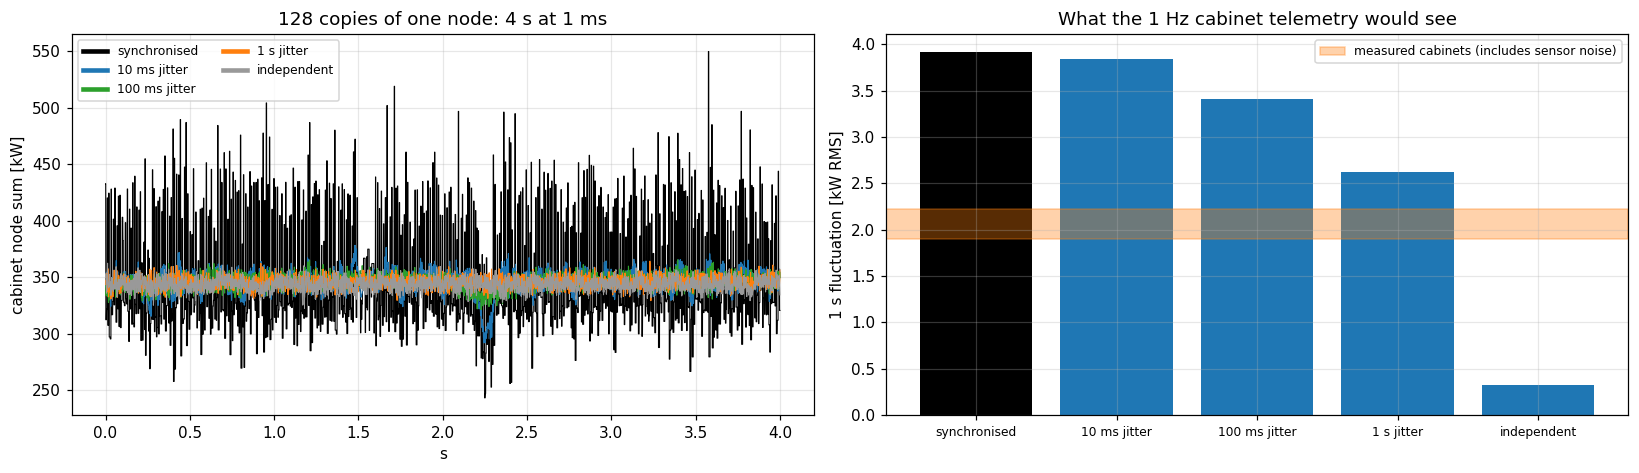

In [25]:
def fig_sync():
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
    a = ax[0]; tt = np.arange(4000) * DT_GPU
    for (name, (cab, _)), col in zip(SYNC.items(), ['k', MAIN_C, THIRD_C, CMP_C, '0.6']):
        a.plot(tt, cab[:4000] / 1e3, color=col, lw=0.7, label=name)
    a.set(xlabel='s', ylabel='cabinet node sum [kW]', title='128 copies of one node: 4 s at 1 ms')
    for l in a.legend(fontsize=8, ncol=2).get_lines(): l.set_linewidth(3)
    a = ax[1]; names = list(SYNC); vals = [SYNC[n][1] / 1e3 for n in names]
    a.bar(range(len(names)), vals, color=[('k' if n == 'synchronised' else MAIN_C) for n in names])
    a.axhspan(meas_hp.min() / 1e3, meas_hp.max() / 1e3, color=CMP_C, alpha=0.35, label='measured cabinets (includes sensor noise)')
    a.set_xticks(range(len(names)), names, fontsize=8); a.set(ylabel='1 s fluctuation [kW RMS]', title='What the 1 Hz cabinet telemetry would see')
    a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part5_node_to_cabinet.png', bbox_inches='tight')

fig_sync()

**How to read this figure.**

* **Left:** 4 seconds of the cabinet's total at 1 ms steps. Black is all 128 copies perfectly in step: huge spikes. The coloured lines are progressively out of step, and much flatter.
* **Right:** the same thing boiled down to a number that the cabinet's once-a-second sensor can see. Each bar is one amount of jitter. The orange band is what the 3 real cabinets did.

**Takeaway.** Perfectly synchronised copies of the single-node trace would make the cabinet node sum swing by ~3.9 kW RMS from second to second. Fully independent copies would swing by ~0.3 kW. The measured cabinets sit in between at ~2 kW, and their 1 Hz fluctuations are only weakly correlated between cabinets running the same job (0.2–0.35). So part of it is common job pacing and the rest is noise or node-level independence.

The measured level is consistent with copies desynchronised by about a second or more, but it can't separate that from a 384-node job whose per-node swings are simply smaller than the single-node run's. Either way, **at the 1 s scale the cabinet sees a smoothed sum**, not 128 × one node's swings.

This matters little for the cooling group: its ~1 min time constant filters anything faster than ~10 s anyway (Part 6). It matters a lot for the **GPU junction**, which sees its own package's ms-scale power in full. So `run_chain` uses the cabinet **envelope** (slow) for the cooling group and each GPU's **own fine structure** for its junction.

## Part 6: Putting it all together

**The question.** Give the model any workload. What does the chip experience, including the cooling system's own behaviour?

`run_chain` does the whole path, in this order:

1. Computers' power → cabinet AC power (Part 2).
2. Cabinet AC power → water temperatures and valve, one step per second (Part 3).
3. Supply water → water at this GPU. That's LIT plus a fixed per-package offset from Part 4. **This step is an assumption**, and the weakest in the chain: nothing here measures the water at a GPU.
4. That water plus the GPU's power → chip temperature and heat fluxes, one step per millisecond (Part 4).

| It takes | Meaning |
|---|---|
| `node_sum_W` | each of the 3 cabinets' total computer power, one value per second. Shape: 3 rows, one per cabinet |
| `gpu_W` | one GPU package's power, one value per millisecond, over the same period |
| `pit` | the building water's temperature: one number, or one per second |
| `package` | which of the 4 fitted packages to use, 0 to 3 |

| It gives back | Meaning |
|---|---|
| `AC`, `LIT`, `LOT`, `POT`, `PLF` | the cooling group, one value per second |
| `Tc_gpu` | the water at this GPU |
| `T` | bucket temperatures; `T[0]` is the junction |
| `q_gen`, `q_die`, `q_wall` | the three heat fluxes, W/cm² |

In [26]:
LIT_REF = CTL['T_set']                                    # assumed supply temperature during the single-node run
for jn in JNET:
    jn['dTc'] = jn['Tc'] - LIT_REF

def run_chain(node_sum_W, gpu_W, pit, package=0, cg_state=None, warm=True):
    '''Arbitrary workload -> cabinet AC -> cooling group (1 s) -> coolant at the GPU -> junction (1 ms).

    node_sum_W: (3, n) per-cabinet node-power sum [W] at DT_CG. gpu_W: package power [W] at DT_GPU covering the same
    n * DT_CG seconds (or None to skip the junction). pit: facility supply [°C]. package: which fitted network (0-3).
    warm: start the cooling group in steady state at the first sample (else from cg_state / defaults).
    '''
    ac = cabinet_ac_from_nodes(np.atleast_2d(node_sum_W))
    pit_arr = np.broadcast_to(np.asarray(pit, float), (ac.shape[1],))
    if warm and cg_state is None:
        cg_state = cooling_group_steady(ac[:, 0], pit_arr[0])
    cgo = simulate_cooling_group(ac, pit_arr, state=cg_state)
    res = dict(t=np.arange(ac.shape[1]) * DT_CG, AC=ac, **cgo)
    if gpu_W is not None:
        jn = JNET[package]
        t_f = np.arange(len(gpu_W)) * DT_GPU
        tc = np.interp(t_f, res['t'], cgo['LIT']) + jn['dTc']
        res.update(t_gpu=t_f, Tc_gpu=tc, P_gpu=np.asarray(gpu_W, float), **junction_response(gpu_W, tc, jn['R'], jn['C']))
    return res

def fine_structure(package=0):
    '''Relative ms-scale fluctuation of one package during steady HPL: power / its 2 s running mean (mean ~1).'''
    p = P_OAM[package][seg]
    return p / uniform_filter1d(p, int(2 / DT_GPU), mode='wrap')

def package_from_node(node_W):
    '''Average package power [W] implied by a per-node power [W] (inverse of node_from_packages, 4 packages).'''
    return np.maximum((np.asarray(node_W) - NODE_FIT[1]) / NODE_FIT[0] / 4, 0)

### Scenario A: the measured 3-cabinet HPL run, down to the GPU junction

The cooling group is driven by the **measured** node sums (so its part of the chain is the validation from Part 3). The GPU in cabinet 1 gets an envelope equal to that cabinet's average package power, times the ms-scale HPL structure of package 0 from the single-node trace (looped), applied only while the node is busy. The junction temperature it predicts is a model output (the cooling group has no GPU telemetry). The comparison is between **coolant from the cooling group** (overshoot and all) and a **constant coolant at the setpoint**.

In [27]:
n_cg = len(t_cg)
env_pkg = np.interp(np.arange(n_cg * int(DT_CG / DT_GPU)) * DT_GPU, t_cg, package_from_node(RF[0] / N_NODES))
fs = fine_structure(0)
idle_pkg, busy_pkg = package_from_node(RF[0][t_cg > 2200].mean() / N_NODES), package_from_node(RF[0].max() / N_NODES)
w_busy = np.clip((env_pkg - idle_pkg) / (busy_pkg - idle_pkg), 0, 1)
gpu_A = env_pkg * (1 + (np.resize(fs, len(env_pkg)) - 1) * w_busy)

A_run = run_chain(RF, gpu_A, PIT, package=0, cg_state=st0, warm=False)
A_fix = junction_response(gpu_A, LIT_REF + JNET[0]['dTc'], JNET[0]['R'], JNET[0]['C'])
tj, tg_ = A_run['T'][0], A_run['t_gpu']
i_pk = np.argmax(A_run['LIT']); win = (tg_ > t_cg[i_pk] - 30) & (tg_ < t_cg[i_pk] + 30)
print(f"supply overshoot peaks at t = {t_cg[i_pk]:.0f} s: LIT {A_run['LIT'][i_pk]:.1f} °C (setpoint {CTL['T_set']:.1f})")
print(f"junction around the overshoot: {tj[win].mean():.1f} °C with the modelled coolant vs {A_fix['T'][0][win].mean():.1f} °C at constant coolant "
      f"(+{tj[win].mean() - A_fix['T'][0][win].mean():.1f} K); max junction over the run {tj.max():.1f} °C")
busy = w_busy > 0.9
fast = lambda x: (x - uniform_filter1d(x, int(1 / DT_GPU)))[busy].std()
print(f"while busy: generated flux {A_run['q_gen'][busy].mean():.1f} W/cm^2 mean, {np.percentile(A_run['q_gen'][busy], 99.9):.1f} p99.9; "
      f"sub-second swing (std about a 1 s mean): generated {fast(A_run['q_gen']):.2f}, die exit {fast(A_run['q_die']):.2f}, "
      f"coolant wall {fast(A_run['q_wall']):.4f} W/cm^2")

supply overshoot peaks at t = 328 s: LIT 33.3 °C (setpoint 28.6)
junction around the overshoot: 62.9 °C with the modelled coolant vs 58.9 °C at constant coolant (+3.9 K); max junction over the run 64.0 °C
while busy: generated flux 29.9 W/cm^2 mean, 45.2 p99.9; sub-second swing (std about a 1 s mean): generated 5.27, die exit 1.38, coolant wall 0.0020 W/cm^2


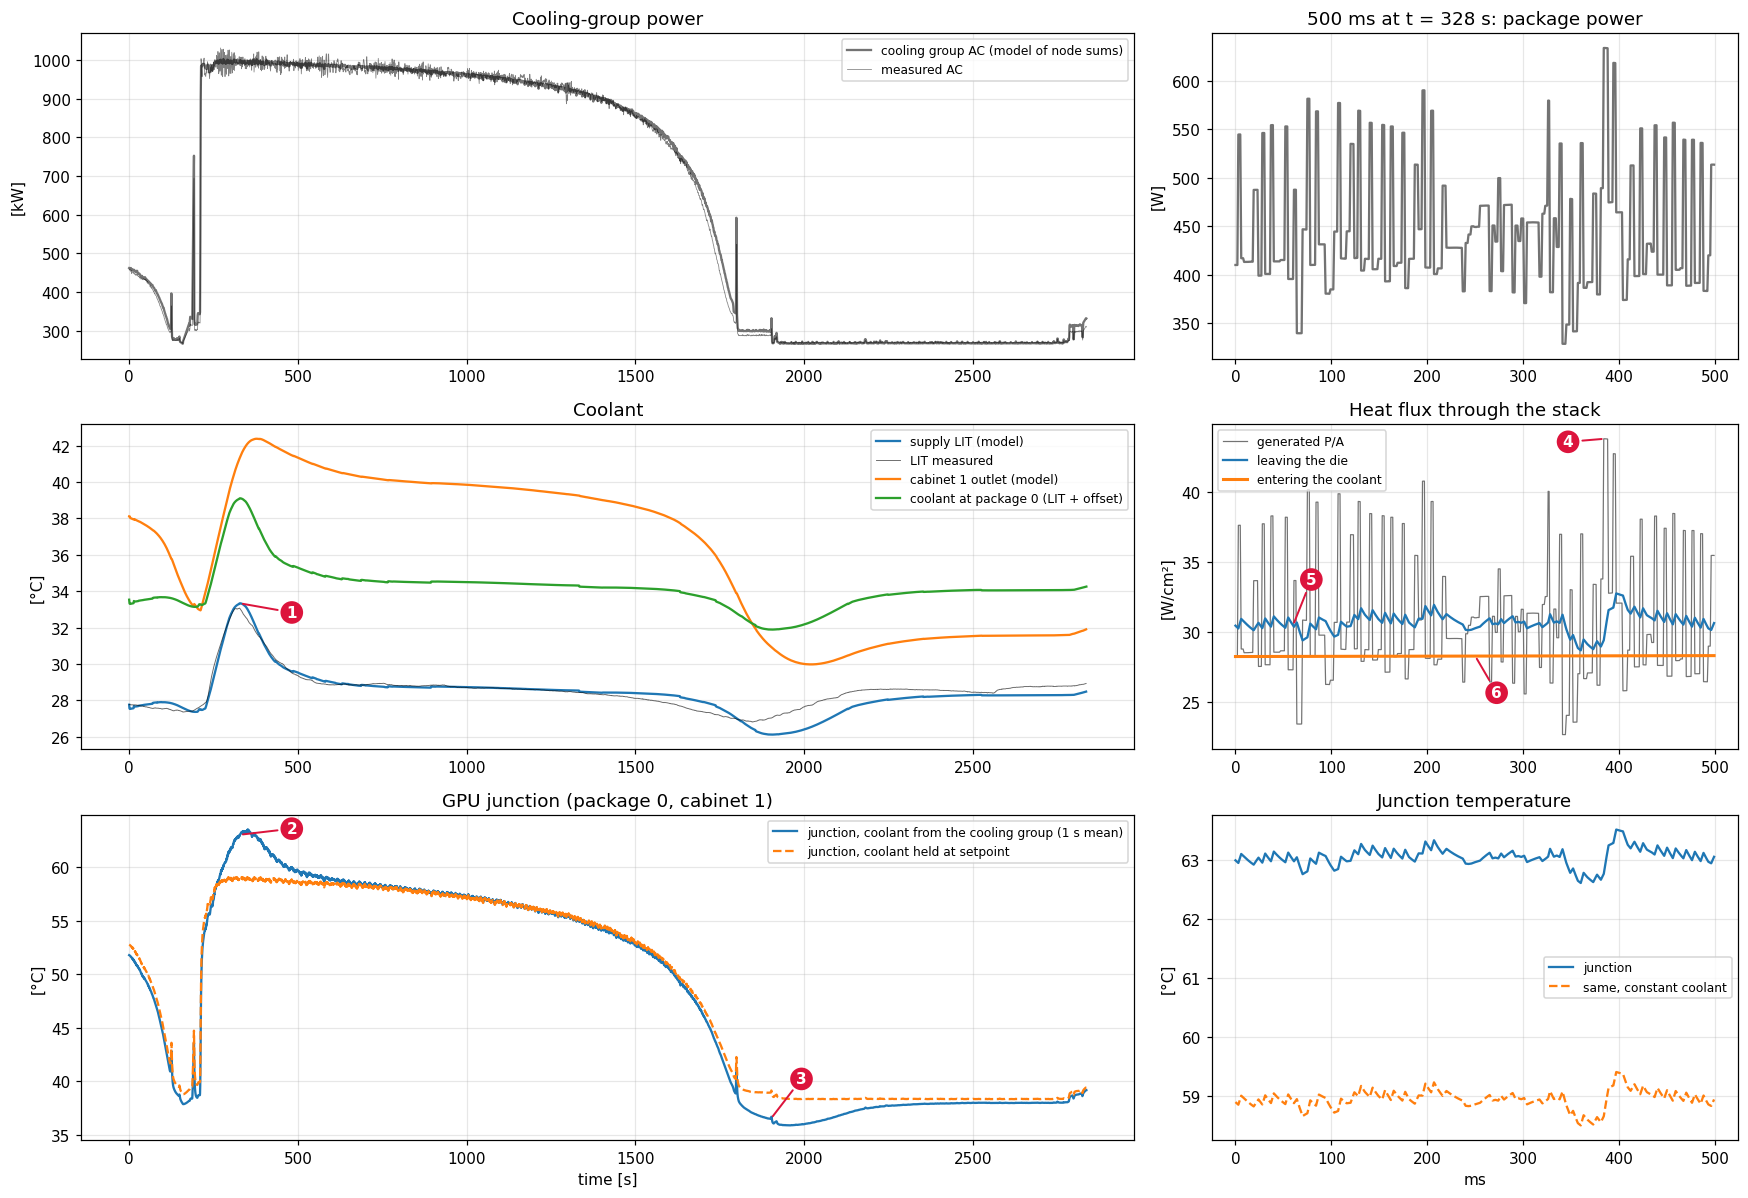

In [28]:
def fig_scenario_A():
    fig, ax = plt.subplots(3, 2, figsize=(16, 11), gridspec_kw=dict(width_ratios=[2, 1]))
    dec = slice(None, None, 200)
    a = ax[0, 0]
    a.plot(t_cg, A_run['AC'].sum(0) / 1e3, color=POWER_C, label='cooling group AC (model of node sums)')
    a.plot(t_cg, AC.sum(0) / 1e3, color='k', lw=0.5, alpha=0.5, label='measured AC')
    a.set(ylabel='[kW]', title='Cooling-group power'); a.legend(fontsize=8)
    a = ax[1, 0]
    a.plot(t_cg, A_run['LIT'], color=MAIN_C, label='supply LIT (model)'); a.plot(t_cg, LIT, color='k', lw=0.6, alpha=0.6, label='LIT measured')
    a.plot(t_cg, A_run['LOT'][0] + CAB[0]['b'], color=CMP_C, label='cabinet 1 outlet (model)')
    a.plot(A_run['t_gpu'][dec], A_run['Tc_gpu'][dec], color=THIRD_C, label='coolant at package 0 (LIT + offset)')
    a.set(ylabel='[°C]', title='Coolant'); a.legend(fontsize=8)
    a = ax[2, 0]
    a.plot(tg_[dec], uniform_filter1d(tj, 1000)[dec], color=MAIN_C, label='junction, coolant from the cooling group (1 s mean)')
    a.plot(tg_[dec], uniform_filter1d(A_fix['T'][0], 1000)[dec], color=CMP_C, ls='--', label='junction, coolant held at setpoint')
    a.set(xlabel='time [s]', ylabel='[°C]', title='GPU junction (package 0, cabinet 1)'); a.legend(fontsize=8)
    zs = t_cg[i_pk]; z = (tg_ >= zs) & (tg_ < zs + 0.5)
    a = ax[0, 1]; a.plot((tg_[z] - zs) * 1e3, A_run['P_gpu'][z], color=POWER_C); a.set(ylabel='[W]', title=f'500 ms at t = {zs:.0f} s: package power')
    a = ax[1, 1]
    a.plot((tg_[z] - zs) * 1e3, A_run['q_gen'][z], color=POWER_C, lw=0.8, label='generated P/A')
    a.plot((tg_[z] - zs) * 1e3, A_run['q_die'][z], color=MAIN_C, label='leaving the die')
    a.plot((tg_[z] - zs) * 1e3, A_run['q_wall'][z], color=CMP_C, lw=2, label='entering the coolant')
    a.set(ylabel='[W/cm²]', title='Heat flux through the stack'); a.legend(fontsize=8)
    a = ax[2, 1]
    a.plot((tg_[z] - zs) * 1e3, tj[z], color=MAIN_C, label='junction'); a.plot((tg_[z] - zs) * 1e3, A_fix['T'][0][z], color=CMP_C, ls='--', label='same, constant coolant')
    a.set(xlabel='ms', ylabel='[°C]', title='Junction temperature'); a.legend(fontsize=8)
    mark(ax[1, 0], 1, t_cg[i_pk], A_run['LIT'][i_pk], dx=34, dy=-6)
    ts = uniform_filter1d(tj, 1000); at = int(np.searchsorted(tg_, t_cg[i_pk]))
    mark(ax[2, 0], 2, tg_[at], ts[at], dx=34, dy=4)
    t_low = t_cg[np.argmin(np.where(t_cg > 1500, A_run['LIT'], np.inf))]; at = int(np.searchsorted(tg_, t_low))
    mark(ax[2, 0], 3, tg_[at], ts[at], dx=20, dy=26)
    x_ms = (tg_[z] - zs) * 1e3; ig = np.argmax(A_run['q_gen'][z])
    mark(ax[1, 1], 4, x_ms[ig], A_run['q_gen'][z][ig], dx=-24, dy=-2)
    mark(ax[1, 1], 5, 60, A_run['q_die'][z][60], dx=12, dy=30)
    mark(ax[1, 1], 6, 250, A_run['q_wall'][z][250], dx=14, dy=-24)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part6_scenario_A_hpl_replay.png', bbox_inches='tight')

fig_scenario_A()

**How to read this figure.** Left column: the whole 47 minutes. Right column: half a second, at the moment of the supply-water peak. The chip temperature here is a **model prediction**, since this run has no GPU sensors. The dashed orange line is a comparison: the same GPU if the water had stayed perfectly on target.

1. **The supply-water overshoot,** following the measured line.
2. **The result at the chip.** The blue line rises above the dashed line by about 3.9 °C, around the overshoot, with the GPU's power the same in both. This is the effect of the cooling infrastructure on the chip.
3. **The opposite at the end.** The supply water dips, so the chip sits below the dashed line. The model's dip is deeper than the real one (Part 3), so this gap is overstated.
4. **Grey: the heat being made.** It jumps by tens of percent within milliseconds.
5. **Blue: the heat leaving the die.** Same trace, far calmer. Sub-second swing is 1.4 W/cm² against 5.3 W/cm² for the heat being made.
6. **Orange: the heat entering the water.** Essentially flat (a swing of 0.002 W/cm²).

In short, the fast wiggles come from the GPU itself and stay inside the chip, while the slow offset comes from the cooling system.

### Scenario B: a made-up on/off workload

All 3 cabinets alternate between HPL-level load and idle, for example a job with long, synchronised pauses to save its state. Each cycle is 10 minutes, busy for 7 of them. While busy, the GPU uses the HPL rhythm.

**What to look for.** The workload repeats faster than the cooling system can settle, so the water never reaches a steady value. It's a repeated version of the start-of-job overshoot.

after settling: LIT swings 6.3 K peak-to-peak, cabinet outlet 11.3 K, primary flow 71 gpm


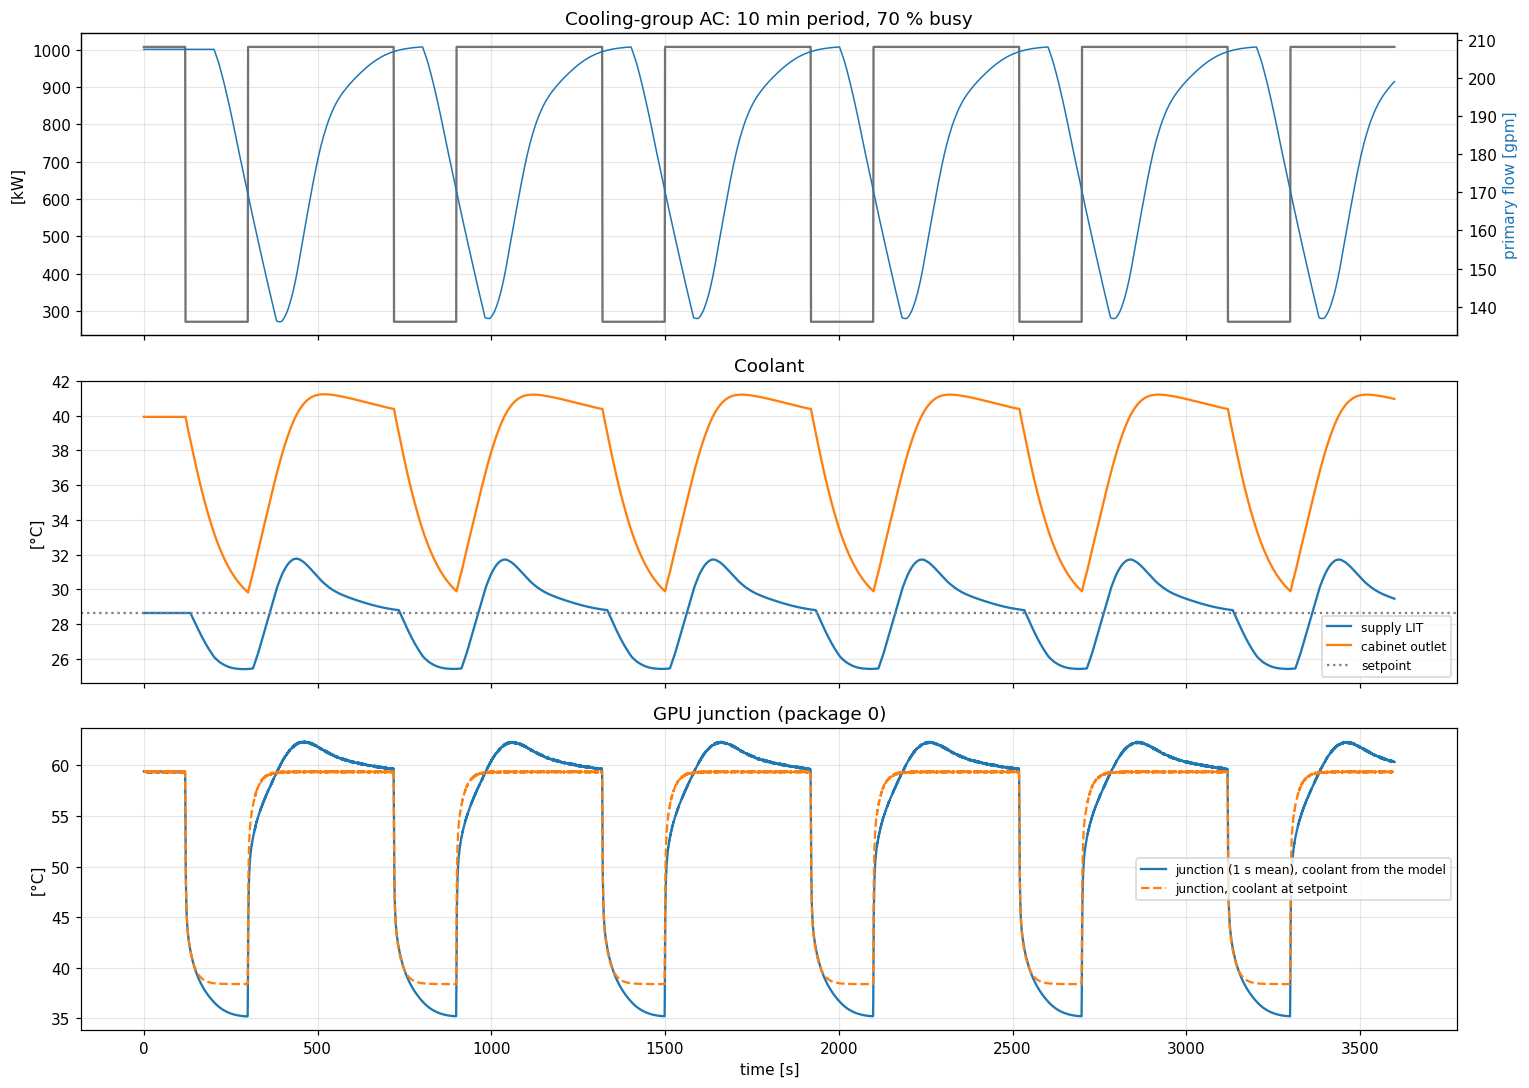

In [29]:
def square_workload(t, period, duty, hi, lo, t0=0.0):
    return np.where(((t - t0) % period) < duty * period, hi, lo)

def make_gpu_trace(node_W_1s, package=0):
    '''Package power at DT_GPU from a per-node power envelope at DT_CG, with the package's HPL fine structure while busy.'''
    tf = np.arange(len(node_W_1s) * int(DT_CG / DT_GPU)) * DT_GPU
    env = np.interp(tf, np.arange(len(node_W_1s)) * DT_CG, package_from_node(node_W_1s))
    lo, hi = package_from_node(node_W_1s.min()), package_from_node(node_W_1s.max())
    w = np.clip((env - lo) / max(hi - lo, 1e-9), 0, 1)
    return env * (1 + (np.resize(fine_structure(package), len(env)) - 1) * w)

DUR_B = 3600
tB = np.arange(DUR_B) * DT_CG
NODE_HI, NODE_LO = RF.max(1).mean() / N_NODES, RF[:, t_cg > 2200].mean() / N_NODES        # per-node W from the measured run
nodeB = square_workload(tB, 600, 0.7, NODE_HI, NODE_LO, t0=300)
B_run = run_chain(np.tile(nodeB * N_NODES, (3, 1)), make_gpu_trace(nodeB), PIT.mean(), package=0)
B_fix = junction_response(B_run['P_gpu'], LIT_REF + JNET[0]['dTc'], JNET[0]['R'], JNET[0]['C'])

def fig_scenario_B():
    fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    ax[0].plot(tB, B_run['AC'].sum(0) / 1e3, color=POWER_C); ax[0].set(ylabel='[kW]', title='Cooling-group AC: 10 min period, 70 % busy')
    ax2 = ax[0].twinx(); ax2.plot(tB, B_run['PLF'], color=MAIN_C, lw=1); ax2.set_ylabel('primary flow [gpm]', color=MAIN_C); ax2.grid(False)
    ax[1].plot(tB, B_run['LIT'], color=MAIN_C, label='supply LIT'); ax[1].plot(tB, B_run['LOT'][0], color=CMP_C, label='cabinet outlet')
    ax[1].axhline(CTL['T_set'], color='0.5', ls=':', label='setpoint'); ax[1].set(ylabel='[°C]', title='Coolant'); ax[1].legend(fontsize=8)
    dec = slice(None, None, 250)
    ax[2].plot(B_run['t_gpu'][dec], uniform_filter1d(B_run['T'][0], 1000)[dec], color=MAIN_C, label='junction (1 s mean), coolant from the model')
    ax[2].plot(B_run['t_gpu'][dec], uniform_filter1d(B_fix['T'][0], 1000)[dec], color=CMP_C, ls='--', label='junction, coolant at setpoint')
    ax[2].set(xlabel='time [s]', ylabel='[°C]', title='GPU junction (package 0)'); ax[2].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part6_scenario_B_periodic.png', bbox_inches='tight')
    late = tB > 1800
    print(f"after settling: LIT swings {np.ptp(B_run['LIT'][late]):.1f} K peak-to-peak, cabinet outlet {np.ptp(B_run['LOT'][0][late]):.1f} K, "
          f"primary flow {np.ptp(B_run['PLF'][late]):.0f} gpm")

fig_scenario_B()

**How to read this figure.**

* **Top:** grey is the workload switching on and off. Blue is the valve, on the right-hand axis, always chasing it and always late. It never reaches the bottom of its range.
* **Middle:** the water. Supply water (blue) swings by 6.3 °C around its dotted target, and the cabinet outlet (orange) by 11.3 °C.
* **Bottom:** the chip. Blue includes the cooling system's behaviour, and dashed orange assumes perfect water temperature. Blue overshoots the dashed line right after each busy phase begins, then falls toward it, and goes below it during idle. So the chip gets a wider swing than its own power alone would give.

### Scenario C: which workload rhythms matter?

**The question.** Scenario B tried one rhythm. Which rhythms does the cooling system average away, and which make things worse at the chip?

**The experiment.** Run on/off workloads between measured idle and peak power on all 3 cabinets, half the time on and half off, with cycle lengths from 10 s to 2 h. For each one, wait for it to settle, then measure the **peak-to-peak swing** (highest minus lowest) of the water, the valve and the chip. The chip is computed twice: once with water perfectly on target (its own power only), and once with water from the cooling model. The gap between those is what the cooling system adds.

,period_s,LIT_pp,LIT_dev,LOT_pp,PLF_pp,Tj_own_pp,Tj_full_pp,Tj_full_max,Tj_own_max
0,10,0.11,0.03,0.25,0.59,13.84,13.84,55.80,55.79
1,20,0.33,0.09,0.53,1.87,15.59,15.63,56.69,56.67
2,40,0.49,0.12,0.94,2.65,17.31,17.23,57.49,57.53
3,60,0.80,0.19,1.50,4.56,18.59,18.34,58.04,58.17
4,120,1.91,0.53,2.98,10.26,20.43,20.02,58.88,59.09
5,240,4.89,1.49,7.32,36.50,20.94,24.61,61.23,59.35
6,360,6.00,2.05,10.69,61.21,20.97,26.70,62.43,59.36
7,600,8.60,2.53,13.18,105.66,20.97,29.24,64.52,59.36
8,900,9.35,2.10,13.73,112.80,20.97,29.97,65.14,59.36
9,1200,9.54,1.66,13.90,112.80,20.97,30.14,65.32,59.36


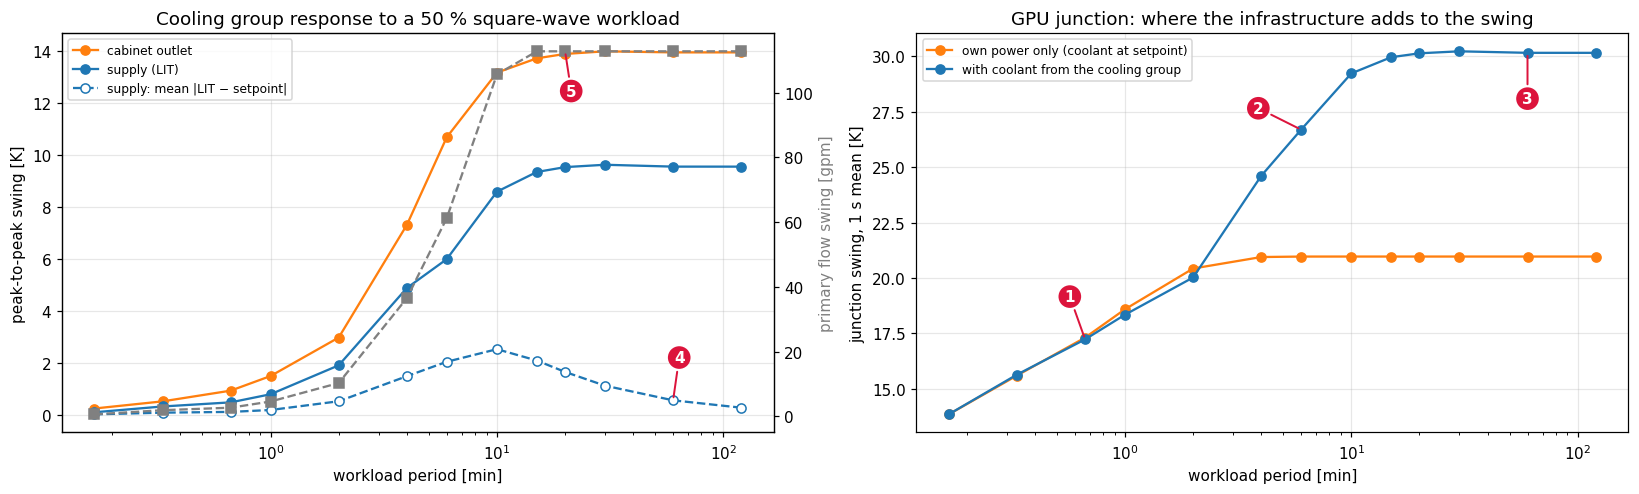

In [30]:
def period_sweep(periods, duty=0.5, n_settle=3, n_measure=2):
    rows = []
    for P in periods:
        dur = int(max((n_settle + n_measure) * P, 2400))
        t = np.arange(dur) * DT_CG
        nodeW = square_workload(t, P, duty, NODE_HI, NODE_LO)
        r = run_chain(np.tile(nodeW * N_NODES, (3, 1)), None, PIT.mean())
        late = t >= dur - n_measure * P
        pkg = package_from_node(nodeW)                         # slow junction at 1 s (fine structure averages out)
        jn = JNET[0]
        own = junction_response(pkg, LIT_REF + jn['dTc'], jn['R'], jn['C'], dt=DT_CG)['T'][0]
        full = junction_response(pkg, r['LIT'] + jn['dTc'], jn['R'], jn['C'], dt=DT_CG)['T'][0]
        rows.append(dict(period_s=P, LIT_pp=np.ptp(r['LIT'][late]), LIT_dev=np.mean(np.abs(r['LIT'][late] - CTL['T_set'])),
                         LOT_pp=np.ptp(r['LOT'][0][late]), PLF_pp=np.ptp(r['PLF'][late]),
                         Tj_own_pp=np.ptp(own[late]), Tj_full_pp=np.ptp(full[late]), Tj_full_max=full[late].max(), Tj_own_max=own[late].max()))
    return pd.DataFrame(rows)

SWEEP = period_sweep([10, 20, 40, 60, 120, 240, 360, 600, 900, 1200, 1800, 3600, 7200])
SWEEP.to_csv(OUT / 'cooling_group_period_sweep.csv', index=False)

def fig_sweep():
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    P = SWEEP.period_s / 60
    a = ax[0]
    a.plot(P, SWEEP.LOT_pp, 'o-', color=CMP_C, label='cabinet outlet')
    a.plot(P, SWEEP.LIT_pp, 'o-', color=MAIN_C, label='supply (LIT)')
    a.plot(P, SWEEP.LIT_dev, 'o--', color=MAIN_C, mfc='w', label='supply: mean |LIT − setpoint|')
    a2 = a.twinx(); a2.plot(P, SWEEP.PLF_pp, 's--', color='0.5', label='primary flow'); a2.set_ylabel('primary flow swing [gpm]', color='0.5'); a2.grid(False)
    a.set(xscale='log', xlabel='workload period [min]', ylabel='peak-to-peak swing [K]', title='Cooling group response to a 50 % square-wave workload'); a.legend(fontsize=8, loc='upper left')
    a = ax[1]
    a.plot(P, SWEEP.Tj_own_pp, 'o-', color=CMP_C, label="own power only (coolant at setpoint)")
    a.plot(P, SWEEP.Tj_full_pp, 'o-', color=MAIN_C, label='with coolant from the cooling group')
    a.set(xscale='log', xlabel='workload period [min]', ylabel='junction swing, 1 s mean [K]', title='GPU junction: where the infrastructure adds to the swing'); a.legend(fontsize=8)
    r = lambda p: SWEEP.iloc[(SWEEP.period_s - p).abs().argmin()]
    mark(ax[1], 1, 40 / 60, r(40).Tj_full_pp, dx=-10, dy=28)
    mark(ax[1], 2, 6, r(360).Tj_full_pp, dx=-28, dy=14)
    mark(ax[1], 3, 60, r(3600).Tj_full_pp, dx=0, dy=-30)
    mark(ax[0], 4, 60, r(3600).LIT_dev, dx=4, dy=28)
    mark(a2, 5, 20, r(1200).PLF_pp, dx=4, dy=-26)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part6_period_sweep.png', bbox_inches='tight')

fig_sweep()
SWEEP.round(2)

**How to read this figure.** Horizontal is how long one on/off cycle takes, in minutes, with each tick 10 times the last. Vertical is how far things swing. The table below it holds the same numbers. Circles 1–3 are in the right panel, and 4–5 in the left.

1. **Fast rhythms (up to about 1 minute): the two lines overlap.** The cabinet's thermal mass averages the workload, so the supply water barely moves (under 1 °C). All of the chip's swing comes from its own power, and it grows with cycle length because the chip's slower buckets get time to fill.
2. **From about 4 minutes up: the lines split.** The valve can't hold the water steady through each on/off switch. This is where the cooling system matters at the chip.
3. **From about 15 minutes up: the gap is at its largest.** The cooling system adds about 9 °C to the chip's own swing of about 21 °C, and raises its hottest moment by about 6 °C. Each switch gives the water a swing of about ±5 °C, as in the measured run.
4. **The dashed line (left panel): average distance from target.** It peaks at 2.5 °C for a 10-minute cycle and then falls to 0.3 °C at 2 hours. Each disturbance lasts only a few minutes, so a longer cycle spends more of its time settled. For long jobs, what matters are the starts and stops.
5. **The grey dashes: the valve runs out of range.** From about 15 minutes up it covers its whole range of about 113 gpm. Idle and peak load sit near its two limits, so this cooling group has little margin at either end.

### One more link: warmer water means slightly more power

The loop also runs the other way. A hotter chip leaks more electricity, which makes more heat. HPE/LRZ [9] measured +69 W per computer on HPL for +15 °C of inlet water, or about 1.15 W per °C per package ($\beta$ in the formula below). Since some of that extra heat warms the chip further, a change of supply temperature gets multiplied by $1/(1-\beta R)$, with $R$ the package's total thermal resistance. The next cell works it out.

In [31]:
BETA_LEAK = 69.0 / 15.0 / 4                         # W per K of junction, per package (from [9]; assumes all of it is GPU leakage)
for k, jn in enumerate(JNET):
    gain = 1 / (1 - BETA_LEAK * jn['R'].sum())
    print(f"package {k}: +1 K supply -> +{gain:.3f} K junction, +{BETA_LEAK * gain:.2f} W package power")
dAC = cabinet_ac_from_nodes(RF.max(1).mean() + N_NODES * 4 * BETA_LEAK) - cabinet_ac_from_nodes(RF.max(1).mean())
print(f"per cabinet at HPL load: +{dAC/1e3:.1f} kW AC per K of supply temperature (from GPU leakage alone)")

package 0: +1 K supply -> +1.068 K junction, +1.23 W package power
package 1: +1 K supply -> +1.053 K junction, +1.21 W package power
package 2: +1 K supply -> +1.066 K junction, +1.23 W package power
package 3: +1 K supply -> +1.050 K junction, +1.21 W package power
per cabinet at HPL load: +0.6 kW AC per K of supply temperature (from GPU leakage alone)


The effect is small: +1 °C of supply gives about +1.05 to +1.07 °C at the chip and about +1.2 W per package. Over a cabinet at HPL load, that's about +0.6 kW per °C.

## Try it yourself

Change the numbers in the next cell and re-run it. As it stands: 10 minutes idle, 20 minutes busy, 10 minutes idle, with the GPU at 450 W and a 50 ms pause every 2 s. All 128 computers in all 3 cabinets do the same thing.

Why 450 W? Through `node_from_packages` that's about 2.2 kW per computer, or 283 kW per cabinet, right at the top of what the cabinet fit in Part 2 has seen (281 kW). A much higher value still runs, but it would rely on extrapolation. To use a real trace, replace `gpu_W` with your array at 1 ms steps.

node sum peak 283 kW per cabinet (Part 2 fit covers 59-281 kW)
supply water peak 34.0 °C, lowest 25.7 °C; valve 99-206 gpm
hottest junction 64.1 °C; junction change over one 50 ms pause about 3.8 °C; settled junction before the job ends 58.9 °C
heat flux entering the water: peak 34.3 W/cm^2; flux made during busy (mean) 30.6 W/cm^2


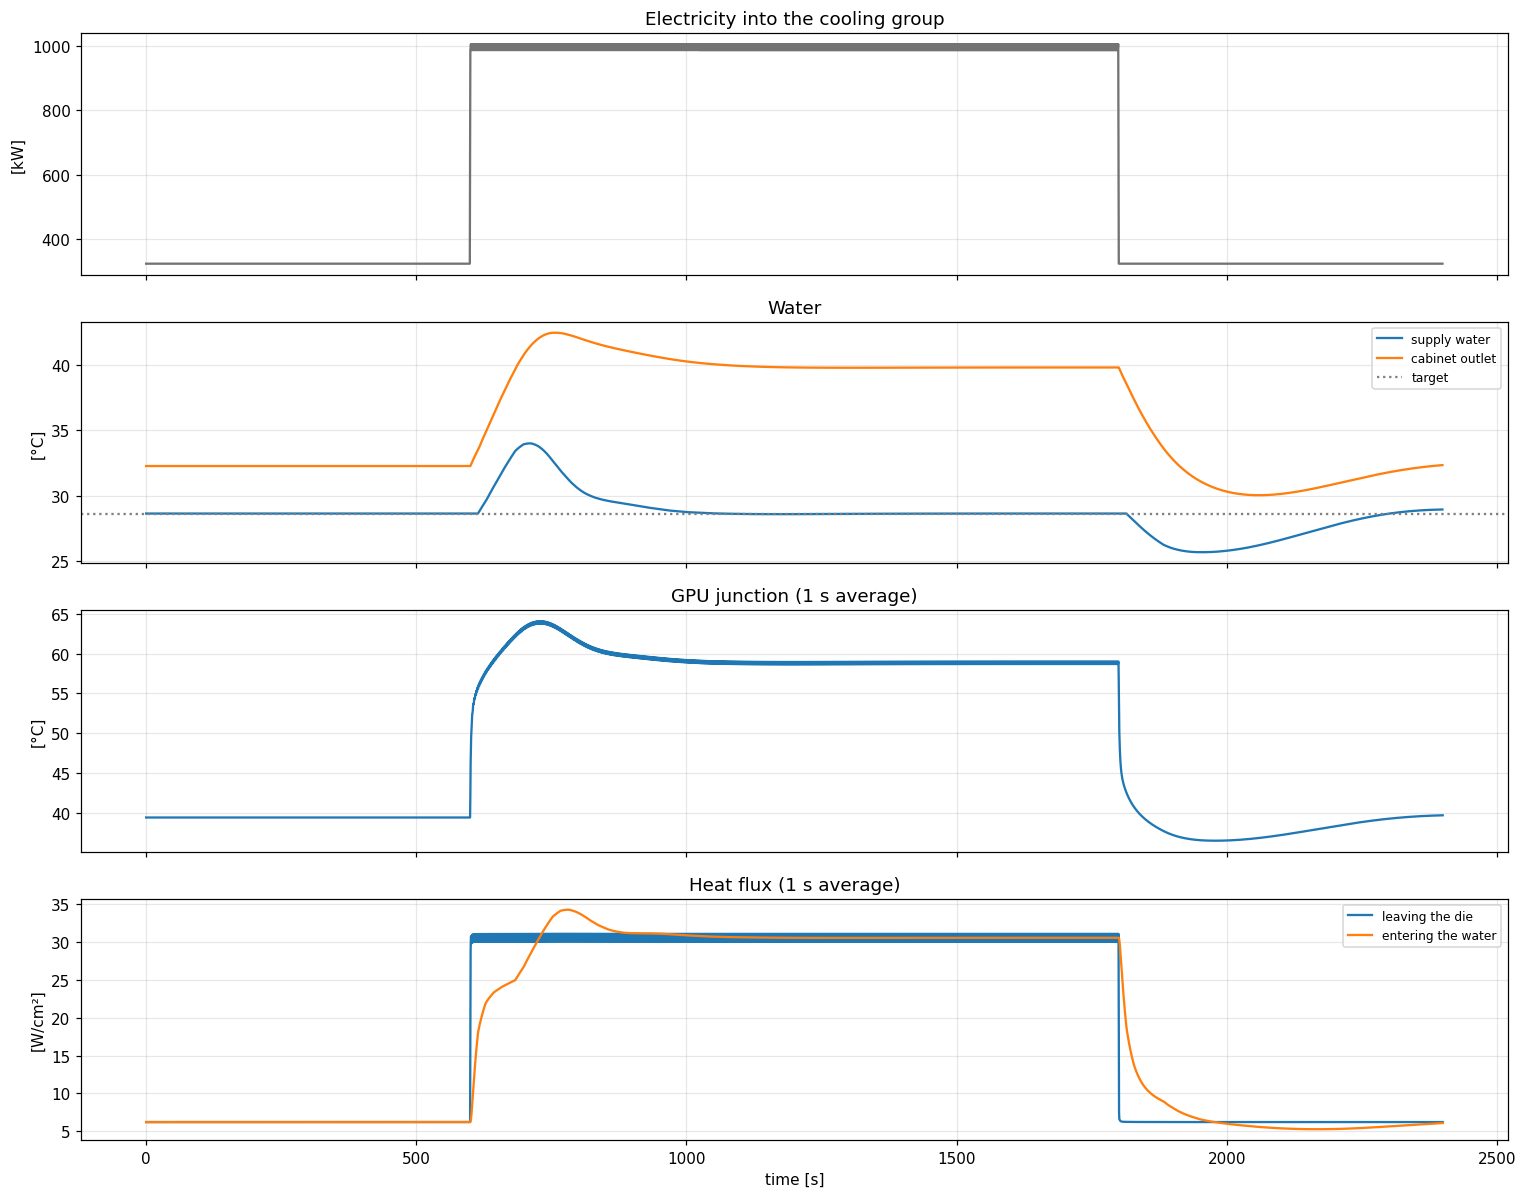

In [32]:
# ---- Change these -------------------------------------------------------------------------------
IDLE_S, BUSY_S, COOL_S = 600, 1200, 600     # seconds of idle, busy, idle
GPU_IDLE_W, GPU_BUSY_W = 90.0, 450.0        # one GPU package's power when idle and when busy [W]
PAUSE_EVERY_S, PAUSE_S, GPU_PAUSE_W = 2.0, 0.05, 150.0   # a short pause in the busy phase: how often, how long, power during it
BUILDING_WATER_C = 21.0                     # building water entering the CDU [°C]
# -------------------------------------------------------------------------------------------------

total_s = IDLE_S + BUSY_S + COOL_S
t_ms = np.arange(total_s * 1000) * DT_GPU                                      # one sample per millisecond
is_busy = (t_ms >= IDLE_S) & (t_ms < IDLE_S + BUSY_S)
is_pause = is_busy & (((t_ms - IDLE_S) % PAUSE_EVERY_S) < PAUSE_S)
gpu_W = np.where(is_busy, GPU_BUSY_W, GPU_IDLE_W)                              # the GPU's power trace
gpu_W[is_pause] = GPU_PAUSE_W

gpu_per_s = gpu_W[:total_s * 1000].reshape(total_s, 1000).mean(1)              # one value per second
node_W = node_from_packages(4 * gpu_per_s)                                     # 4 packages -> one computer
node_sum_W = np.tile(node_W * N_NODES, (3, 1))                                 # 128 computers, 3 identical cabinets

mine = run_chain(node_sum_W, gpu_W, BUILDING_WATER_C, package=0)

def fig_try_it():
    fig, ax = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
    t = mine['t']; dec = slice(None, None, 500)
    ax[0].plot(t, mine['AC'].sum(0) / 1e3, color=POWER_C); ax[0].set(ylabel='[kW]', title='Electricity into the cooling group')
    ax[1].plot(t, mine['LIT'], color=MAIN_C, label='supply water'); ax[1].plot(t, mine['LOT'][0], color=CMP_C, label='cabinet outlet')
    ax[1].axhline(CTL['T_set'], color='0.5', ls=':', label='target'); ax[1].set(ylabel='[°C]', title='Water'); ax[1].legend(fontsize=8)
    ax[2].plot(mine['t_gpu'][dec], uniform_filter1d(mine['T'][0], 1000)[dec], color=MAIN_C); ax[2].set(ylabel='[°C]', title='GPU junction (1 s average)')
    ax[3].plot(mine['t_gpu'][dec], uniform_filter1d(mine['q_die'], 1000)[dec], color=MAIN_C, label='leaving the die')
    ax[3].plot(mine['t_gpu'][dec], uniform_filter1d(mine['q_wall'], 1000)[dec], color=CMP_C, label='entering the water')
    ax[3].set(xlabel='time [s]', ylabel='[W/cm²]', title='Heat flux (1 s average)'); ax[3].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'cg_part6_try_it.png', bbox_inches='tight')
    print(f"node sum peak {node_sum_W.max()/1e3:.0f} kW per cabinet (Part 2 fit covers {RF_RANGE[0]/1e3:.0f}-{RF_RANGE[1]/1e3:.0f} kW)")
    print(f"supply water peak {mine['LIT'].max():.1f} °C, lowest {mine['LIT'].min():.1f} °C; valve {mine['PLF'].min():.0f}-{mine['PLF'].max():.0f} gpm")
    print(f"hottest junction {mine['T'][0].max():.1f} °C; junction change over one 50 ms pause about "
          f"{np.ptp(mine['T'][0][(t_ms >= IDLE_S + BUSY_S - 2) & (t_ms < IDLE_S + BUSY_S)]):.1f} °C; settled junction before the job ends "
          f"{mine['T'][0][(t_ms >= IDLE_S + BUSY_S - 60) & (t_ms < IDLE_S + BUSY_S)].mean():.1f} °C")
    print(f"heat flux entering the water: peak {mine['q_wall'].max():.1f} W/cm^2; flux made during busy (mean) {mine['q_gen'][is_busy].mean():.1f} W/cm^2")

fig_try_it()

**How to read this figure** (with the default numbers). All four panels share a time axis. The job runs from t = 600 s to 1 800 s.

* **Electricity:** a clean step up and down.
* **Water:** the supply peaks at 34.0 °C after the job starts, then returns to target. It undershoots to 25.7 °C after the job ends. The valve ranges over 99–206 gpm.
* **Junction:** the hottest moment is 64.1 °C, during the overshoot, about 5 °C above where it settles (58.9 °C). The band's thickness is the 3.8 °C dip at each 50 ms pause.
* **Heat flux:** orange lags blue at each edge. It also briefly goes above blue, peaking at 34.3 W/cm² against the 30.6 W/cm² being made. That's the supply water cooling back down after its overshoot: as the water cools, the warmed metal releases stored heat into it. So the cooling system changes the flux into the water as well as the chip's temperature.

## Summary: what we learned

**The question was:** given a GPU's power over time, how hot does the chip get and how does heat flow out of it, once the cooling system is included?

**The model** is a chain of simple pieces, each matched to measurements: computers' power → cabinet electricity → warm metal and water → heat exchanger with a late-reacting valve → water at the GPU → three "buckets" of chip, package and cold plate.

**How well it matches**

| What | Typical error |
|---|---|
| Cabinet outlet water, using measured inlet water | 0.12–0.19 °C |
| Whole cooling group from electricity and building water alone | ~0.2 °C on fitted data, 0.6–0.8 °C on unseen data |
| Cabinet electricity from computers' power | ~1.4 kW out of about 330 kW |
| GPU chip temperature, on the one recorded computer | ~0.75 °C (the sensor reads whole degrees) |
| GPU chip temperature on a running cabinet | **Not checked.** No recording has both |

**What it says**

1. **The cooling system reaches the chip as a slow offset.** At a job's start the heat arrives faster than the valve opens, the supply water peaks about 4.4 °C above target, and the chip runs about 3.9 °C hotter for a few minutes. In the model, a much quicker thermostat cuts that peak roughly in half but doesn't remove it.
2. **The chip's own fast swings come from its own power.** Fast pauses cause dips of a few degrees that the cooling system plays no part in.
3. **The package smooths heat strongly.** The water sees essentially nothing faster than about 5 s, and about 45 % of a 1-minute swing. So `liquid_bl_rochpl.ipynb`, which sends raw power straight into the liquid, overstates fast flux at a cold-plate wall.
4. **Rhythm decides whether the cooling system matters.** Cycles under about a minute are averaged out. From about 4 minutes up, each switch disturbs the water, and in the worst case this adds about 9 °C to a chip swing of about 21 °C.
5. **Published loss formulas run low here.** RAPS under-predicts this cooling group's cabinet electricity by 8–16 %.

**How far to trust it**

* **Weakest link:** the water at each GPU is taken as supply water plus a fixed offset, from a different run on a different day.
* **The valve model is the simplest one that fits.** It's known to release too early during HPL's decay.
* **Only one job.** Everything comes from one 47-minute HPL recording on one cooling group and one 82 s single-computer run. Other workloads in Scenarios B and C are what the model predicts, not things we've observed.
* **Column meanings were inferred.** The energy balance supports them, but they should be confirmed with whoever produced the file.

The table below gives more detail on what's fitted and what's assumed.

## Assumptions, limits and next steps

**What is fitted vs. assumed**

| Link | Source | Confidence |
|---|---|---|
| Node sum → cabinet AC | fit to this cooling group (quadratic, 59–281 kW node sum); RAPS slope outside | good inside the range, with a gap in the data between idle and high load; extrapolation is a guess |
| Cabinet thermal mass, flow, UA | fit, train/test split | good (0.12–0.19 K RMS with measured inlet) |
| CDU HX, lags, κ | fit | good; κ = 0.884 is a calibration, not physics |
| Valve controller | PI fit | fair; misses the hold at full flow during the ramp-down |
| GPU junction network | fit to rocm_smi junction sensor, single node | good for that node; one sensor per package, 1 °C steps |
| GPU coolant = LIT + offset | assumption (no blade-level coolant telemetry); offsets from the single-node fit | the weakest link |
| Coolant is water | assumption; only affects gpm conversions | |

@@@END
@@@OLD
| `RFNP_Cn` | sum of node power reported via Redfish [W] | 470 W/node idle, 2.2 kW/node peak *(inferred name)* |
@@@NEW
| `RFNP_Cn` | sum of node power reported via Redfish [W] | ~475 W/node idle, 2.2 kW/node peak *(inferred name)* |
**Next steps**

1. **Blade-level coolant path**: model the serial flow across a blade (CPU and 4 packages in order [9]) so a GPU's coolant depends on its neighbours' power, instead of a fixed offset. That needs the blade's plumbing order and flow per blade.
2. **Get coolant and junction telemetry from the same run**: a multi-node rocHPL with Ampere on nodes inside the cooling group would test Part 6's junction predictions directly.
3. **Better controller**: fit against more cooling-group events (job starts and stops of different sizes) to identify the real CDU logic (anti-windup, feed-forward, flow limits).
4. **Facility side**: feed `Q_prim` into the HTW/cooling-tower Modelica model of ExaDigiT [3, 4] to go from cooling group to the whole plant.
5. **Two-phase / boundary-layer link**: drive the `liquid_bl_rochpl.ipynb` boundary-layer model with $q''_{wall}(t)$ from Part 4 instead of $P/A$.